# EXP_02. ¿Cambiar el peso de los meses mejora la predicción?

**CRISP-DM: preparar datos, modelar y evaluar.** Una media por captura concede
más peso a los meses con más valores disponibles. La hipótesis T1 cambia esa
representación: primero promediar dentro de cada mes; después ponderar las siete
medias por los días del mes. Preguntamos si mejora E2, no si su aritmética era errónea.

**Lector retrospectivo: cero ajustes de modelo.** Reconstruimos tres variables
desde capturas reales y recalculamos métricas de OOF **guardadas**. No recalculamos
predicciones, scores interiores ni las 59 predicciones finales.

Trabajo original: **29 de septiembre de 2026**, posterior a exploración del 24.
Adaptación: **8 de octubre de 2026**. El original usó Python 3.12.14/scikit-learn
1.9.1; este lector usa Python 3.13. Es la segunda ronda histórica, no otra búsqueda.

**Recorrido:** capturas → pesos → tres variables → comparación pareada → decisión.
Sube solo este `.ipynb` a Colab y ejecuta en orden. Contiene capturas, tablas y
controles; no necesita Drive, ZIP, Git ni otro cuaderno. Dos bloques técnicos están
plegados; todos los cálculos que explican el experimento permanecen visibles.

## 1. Entorno e insumos: ¿qué corre realmente?

Colab prepara NumPy, pandas y Matplotlib con las versiones de uv. Si cambia un
módulo ya cargado, solicita reiniciar manualmente. En local no instala nada.
«Mostrar código» abre los dos bloques técnicos: entorno y tablas comprimidas.
No contienen un modelo oculto ni extracción científica sin explicar.

In [1]:
# @title Preparación de Colab: tres bibliotecas, sin descargar datos { display-mode: "form" }
"""Preparación explícita de Colab y descarga verificada, sin cambiar cálculos científicos.

Este módulo usa la biblioteca estándar hasta que se solicita preparar Colab o descargar
el ZIP. Se incrusta completo en el notebook para no depender de un clon del proyecto.
"""

from __future__ import annotations

import hashlib
import importlib
import importlib.metadata as metadata
import os
import re
import subprocess
import sys
import tempfile
from pathlib import Path


REQUERIDOS_AUDITORIA = ("numpy", "pandas", "matplotlib")
MODULOS_DISTRIBUCIONES = {
    "numpy": "numpy", "pandas": "pandas", "matplotlib": "matplotlib",
    "pyshp": "shapefile", "shapely": "shapely", "pyproj": "pyproj", "gdown": "gdown",
    "pillow": "PIL", "python-dateutil": "dateutil", "beautifulsoup4": "bs4",
    "scikit-learn": "sklearn", "pysocks": "socks", "typing-extensions": "typing_extensions",
}


class ReinicioColabRequerido(RuntimeError):
    """Una instalación cambió una biblioteca que ya estaba cargada en la sesión."""

    def __init__(self, cambios: list[str], modulos_cargados: list[str]):
        self.cambios = cambios
        self.modulos_cargados = modulos_cargados
        super().__init__(
            "Las versiones se prepararon, pero ya había módulos cargados que cambiaron: "
            + ", ".join(modulos_cargados)
            + ". En Colab selecciona Entorno de ejecución > Reiniciar sesión y después "
            "Ejecutar todas. No se reinicia ni se mata la sesión automáticamente."
        )


def _perfil_fijado(perfil: str) -> dict[str, str]:
    versiones = {}
    for nombre, version in re.findall(
        r"^([A-Za-z0-9_-]+)==([^\s;]+)", perfil, flags=re.MULTILINE,
    ):
        clave = nombre.lower().replace("_", "-")
        if clave in versiones:
            raise ValueError(f"Paquete repetido en el perfil: {nombre}")
        versiones[clave] = version
    if not versiones:
        raise ValueError("El perfil de uv no contiene versiones fijadas.")
    return versiones


def versiones_requeridas(
    perfil: str, nombres: tuple[str, ...] = REQUERIDOS_AUDITORIA,
) -> dict[str, str]:
    """Lee las versiones de las raíces realmente utilizadas en esta auditoría."""
    fijadas = _perfil_fijado(perfil)
    faltantes = [nombre for nombre in nombres if nombre not in fijadas]
    if faltantes:
        raise ValueError("Faltan paquetes del cuaderno en el perfil uv: " + ", ".join(faltantes))
    return {nombre: fijadas[nombre] for nombre in nombres}


def _version_o_ausente(nombre: str, consultar_version) -> str | None:
    try:
        return consultar_version(nombre)
    except metadata.PackageNotFoundError:
        return None


def _modulo_cargado(nombre: str, modulos) -> bool:
    raiz = MODULOS_DISTRIBUCIONES.get(nombre, nombre.replace("-", "_"))
    return any(clave == raiz or clave.startswith(raiz + ".") for clave in modulos)


def _comprobar_importaciones(versiones: dict[str, str]) -> None:
    """Prueba importaciones y operaciones pequeñas; no entrena ni lee datos del reto."""
    for nombre, esperada in versiones.items():
        modulo = importlib.import_module(MODULOS_DISTRIBUCIONES.get(nombre, nombre))
        version_cargada = getattr(modulo, "__version__", None)
        if version_cargada is not None and str(version_cargada) != esperada:
            raise ReinicioColabRequerido([], [nombre])
    import numpy as np
    import pandas as pd

    if not np.isclose(np.array([1.0, 3.0]).mean(), 2.0):
        raise RuntimeError("No pasó la comprobación mínima de NumPy.")
    if pd.DataFrame({"x": [1, 2]}).shape != (2, 1):
        raise RuntimeError("No pasó la comprobación mínima de pandas.")


def _avisar_incompatibilidad_numba(informar) -> None:
    """Aviso acotado: este notebook no usa ni modifica Numba."""
    try:
        requisitos = metadata.requires("numba") or []
        from packaging.requirements import Requirement

        numpy_version = metadata.version("numpy")
        for texto in requisitos:
            requisito = Requirement(texto)
            if requisito.name.lower() != "numpy":
                continue
            if requisito.marker is not None and not requisito.marker.evaluate():
                continue
            if numpy_version not in requisito.specifier:
                informar(
                    f"Aviso del entorno de Colab: Numba declara {requisito}, pero NumPy es "
                    f"{numpy_version}. Este cuaderno no usa Numba ni lo actualiza. "
                    "La verificación cubre sus bibliotecas, no todos los paquetes de Colab."
                )
    except (metadata.PackageNotFoundError, ImportError):
        return


def preparar_colab(
    perfil: str, *, en_colab: bool, habilitar: bool = True,
    consultar_version=metadata.version, modulos=None, ejecutar=subprocess.check_call,
    informar=print, verificar_importaciones=None,
) -> dict:
    """Instala solo raíces distintas/faltantes en Colab, con dependencias restringidas por uv.

    Las funciones inyectables permiten probar instalación, versiones y reinicio sin red.
    En local no se llama a pip ni se modifica el entorno: lo prepara uv.
    """
    esperadas = versiones_requeridas(perfil)
    instaladas = {
        nombre: _version_o_ausente(nombre, consultar_version) for nombre in esperadas
    }
    cambios = [f"{nombre}=={version}" for nombre, version in esperadas.items()
               if instaladas[nombre] != version]
    if not en_colab:
        informar("Entorno local: no se instala nada desde el cuaderno; se utiliza uv.")
        return {"estado": "local_sin_instalar", "cambios": [], "instaladas": instaladas,
                "reinicio_requerido": False}

    informar("Preparación de Colab: Python y paquetes se comprobarán antes de leer datos.")
    informar("Plan: " + (", ".join(cambios) if cambios else "sin instalaciones necesarias"))
    if cambios and not habilitar:
        raise RuntimeError(
            "El perfil difiere y PREPARAR_COLAB está desactivado. Actívalo y vuelve "
            "a ejecutar esta celda, o prepara manualmente las versiones impresas."
        )

    fijadas = _perfil_fijado(perfil)
    modulos = sys.modules if modulos is None else modulos
    cargados_antes = {nombre for nombre in fijadas if _modulo_cargado(nombre, modulos)}
    versiones_antes = {
        nombre: _version_o_ausente(nombre, consultar_version) for nombre in cargados_antes
    }
    if cambios:
        with tempfile.TemporaryDirectory(prefix="agrocebada-colab-perfil-") as carpeta:
            restricciones = Path(carpeta) / "perfil-uv-constraints.txt"
            restricciones.write_text(perfil, encoding="utf-8")
            comando = [sys.executable, "-m", "pip", "install", "--only-binary=:all:",
                       "--disable-pip-version-check", "--constraint", str(restricciones),
                       *cambios]
            informar("Se instala únicamente el plan; dependencias necesarias limitadas por uv.")
            try:
                ejecutar(comando)
            except (subprocess.CalledProcessError, OSError) as error:
                raise RuntimeError(
                    "No se pudo preparar el perfil binario. No se ejecutará la auditoría "
                    "con otras versiones. Revisa el error de pip y reinicia la sesión "
                    "si la instalación quedó a medias."
                ) from error

        importlib.invalidate_caches()
        cargados_cambiados = sorted(
            nombre for nombre in cargados_antes
            if versiones_antes[nombre] != _version_o_ausente(nombre, consultar_version)
            or any(cambio.startswith(nombre + "==") for cambio in cambios)
        )
        if cargados_cambiados:
            raise ReinicioColabRequerido(cambios, cargados_cambiados)

    instaladas = {
        nombre: _version_o_ausente(nombre, consultar_version) for nombre in esperadas
    }
    divergentes = [nombre for nombre, version in esperadas.items()
                  if instaladas[nombre] != version]
    if divergentes:
        raise RuntimeError("El perfil no coincide tras prepararlo: " + ", ".join(divergentes))
    comprobar = _comprobar_importaciones if verificar_importaciones is None else (
        verificar_importaciones
    )
    comprobar(esperadas)
    # Evita inspeccionar el entorno verdadero en pruebas con proveedores de versiones inventados.
    if consultar_version is metadata.version:
        _avisar_incompatibilidad_numba(informar)
    informar("Perfil requerido e importaciones comprobados; no se garantiza todo el entorno Colab.")
    return {"estado": "colab_instalado" if cambios else "colab_existente", "cambios": cambios,
            "instaladas": instaladas, "reinicio_requerido": False}


def validar_dataset(ruta: Path, sha256_esperado: str, bytes_esperados: int) -> Path:
    """Rechaza tamaño o huella incorrectos antes de que se abra el ZIP."""
    ruta = Path(ruta)
    if not re.fullmatch(r"[0-9a-f]{64}", sha256_esperado) or bytes_esperados <= 0:
        raise ValueError("Contrato de identidad del dataset inválido.")
    if not ruta.is_file():
        raise FileNotFoundError(f"No existe el archivo de entrada: {ruta}")
    if ruta.stat().st_size != bytes_esperados:
        raise ValueError(f"Tamaño incorrecto de {ruta.name}: se esperaban {bytes_esperados} bytes.")
    huella = hashlib.sha256()
    with ruta.open("rb") as archivo:
        for bloque in iter(lambda: archivo.read(1024 * 1024), b""):
            huella.update(bloque)
    if huella.hexdigest() != sha256_esperado:
        raise ValueError(f"SHA-256 incorrecto de {ruta.name}; no se usará este archivo.")
    return ruta


def obtener_dataset(
    destino: Path, *, file_id: str | None = None, sha256_esperado: str,
    bytes_esperados: int, permitir_descarga: bool, descargar=None,
) -> Path:
    """Usa caché validada o descarga explícita a temporal; publica solo bytes verificados.

    Una copia local incorrecta nunca se sustituye silenciosamente. Una descarga rechazada
    queda en cuarentena para diagnóstico; no se cambian permisos, cuentas ni credenciales.
    """
    destino = Path(destino).expanduser()
    if destino.exists():
        return validar_dataset(destino, sha256_esperado, bytes_esperados)
    if not permitir_descarga:
        raise FileNotFoundError(
            "No está el ZIP original. En local, coloca DataSet.zip en data/raw/ o indica "
            "RUTA_DATASET. La descarga solo se habilita explícitamente."
        )
    if file_id is None or not re.fullmatch(r"[A-Za-z0-9_-]{10,}", file_id):
        raise ValueError(
            "Falta el ID de Drive del ZIP original autorizado. Configura ID_DRIVE_DATASET "
            "(no el ID del notebook), o proporciona una copia local verificada."
        )
    if not re.fullmatch(r"[0-9a-f]{64}", sha256_esperado) or bytes_esperados <= 0:
        raise ValueError("Contrato de identidad del dataset inválido.")
    destino.parent.mkdir(parents=True, exist_ok=True)
    descriptor, nombre_temporal = tempfile.mkstemp(
        prefix=destino.name + ".", suffix=".part", dir=destino.parent,
    )
    os.close(descriptor)
    temporal = Path(nombre_temporal)
    try:
        if descargar is None:
            import gdown

            descargar = gdown.download
        resultado = descargar(
            id=file_id, output=str(temporal), quiet=False, use_cookies=False,
        )
        if resultado is None:
            raise RuntimeError("Drive no entregó un archivo descargable.")
        validar_dataset(temporal, sha256_esperado, bytes_esperados)
        # Mismo directorio/sistema de archivos: la creación del enlace publica el
        # archivo completo y falla atómicamente si otra ejecución ganó la carrera.
        # No usamos exists() + replace(), que permitiría sustituir una aparición
        # concurrente entre ambas operaciones.
        try:
            os.link(temporal, destino)
        except FileExistsError:
            validar_dataset(destino, sha256_esperado, bytes_esperados)
        except OSError as error:
            raise RuntimeError(
                "Este destino no permite publicar mediante enlace atómico sin reemplazo. "
                "Usa una carpeta local de la sesión; no se sobrescribirá otro archivo."
            ) from error
        temporal.unlink()
        return destino
    except Exception as error:
        if temporal.exists():
            cuarentena = temporal.with_suffix(".rechazado")
            os.replace(temporal, cuarentena)
            detalle = f" Archivo recibido conservado para revisión en {cuarentena.name}."
        else:
            detalle = ""
        raise RuntimeError(
            "La descarga no quedó publicada como DataSet.zip: comprueba enlace, permisos, "
            "cuota y coincidencia de tamaño/SHA-256." + detalle
        ) from error


In [2]:
PREPARAR_COLAB = True
import importlib.util
import sys
try:
    EN_COLAB = importlib.util.find_spec("google.colab") is not None
except ModuleNotFoundError:
    EN_COLAB = False
if sys.version_info[:2] != (3, 13):
    raise RuntimeError("Este lector requiere Python 3.13 en local y Colab.")
REQUIREMENTS_COLAB = "affine==3.0.1\n    # via rasterio\nattrs==26.1.0\n    # via\n    #   affine\n    #   rasterio\nbeautifulsoup4==4.15.0\n    # via gdown\ncertifi==2026.7.22\n    # via\n    #   pyproj\n    #   rasterio\n    #   requests\ncharset-normalizer==3.5.2\n    # via requests\nclick==8.5.0\n    # via rasterio\ncloudpickle==3.1.2\n    # via joblib\ncolorama==0.4.6 ; sys_platform == 'win32'\n    # via tqdm\ncontourpy==1.4.0\n    # via matplotlib\ncycler==0.12.1\n    # via matplotlib\nfilelock==4.0.12\n    # via gdown\nfonttools==4.66.1\n    # via matplotlib\ngdown==5.2.2\nidna==3.20\n    # via requests\njoblib==1.6.0\n    # via scikit-learn\nkiwisolver==1.5.1\n    # via matplotlib\nmatplotlib==3.11.2\nnarwhals==2.26.0\n    # via scikit-learn\nnumpy==2.4.4\n    # via\n    #   agrocebada-uv\n    #   contourpy\n    #   matplotlib\n    #   pandas\n    #   rasterio\n    #   scikit-learn\n    #   scipy\n    #   shapely\npackaging==26.3\n    # via matplotlib\npandas==2.2.3\n    # via agrocebada-uv\npillow==12.3.0\n    # via matplotlib\npyparsing==3.3.3\n    # via\n    #   matplotlib\n    #   rasterio\npyproj==3.8.0\npyshp==3.1.6\npysocks==1.7.1\n    # via requests\npython-dateutil==2.9.0.post0\n    # via\n    #   matplotlib\n    #   pandas\npytz==2026.5\n    # via pandas\nrasterio==1.5.2\nrequests==2.34.2\n    # via gdown\nscikit-learn==1.9.1\n    # via agrocebada-uv\nscipy==1.18.0\n    # via\n    #   agrocebada-uv\n    #   scikit-learn\nshapely==2.1.2\nsix==1.17.0\n    # via python-dateutil\nsoupsieve==2.10\n    # via beautifulsoup4\nthreadpoolctl==3.7.0\n    # via scikit-learn\ntqdm==4.70.1\n    # via gdown\ntyping-extensions==4.16.0\n    # via beautifulsoup4\ntzdata==2026.5\n    # via pandas\nurllib3==2.8.0\n    # via requests\n"
VERSIONES = {'numpy': '2.4.4', 'pandas': '2.2.3', 'matplotlib': '3.11.2'}
assert hashlib.sha256(REQUIREMENTS_COLAB.encode()).hexdigest() == '8f18975fe344552700b5efe887bc0ede3128554a73f1457649652b35eb9cd95e'
preparacion = preparar_colab(REQUIREMENTS_COLAB, en_colab=EN_COLAB, habilitar=PREPARAR_COLAB)
print(preparacion["estado"])

Entorno local: no se instala nada desde el cuaderno; se utiliza uv.
local_sin_instalar


In [3]:
import base64
import hashlib
import importlib.metadata as metadata
import io
import json
import platform
import zlib
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

FECHA_EJECUCION_UTC = datetime.now(timezone.utc).isoformat()
assert all(metadata.version(k) == v for k, v in VERSIONES.items())
print("Python:", platform.python_version(), "| Ejecución UTC:", FECHA_EJECUCION_UTC)
display(pd.DataFrame([{"biblioteca": k, "version": v} for k, v in VERSIONES.items()]))
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

Python: 3.13.13 | Ejecución UTC: 2026-10-08T14:04:36.638681+00:00


,biblioteca,version
0,numpy,2.4.4
1,pandas,2.2.3
2,matplotlib,3.11.2


| Insumo | Uso | Alcance |
| --- | --- | --- |
| Capturas Planet NDVI y Sentinel-2 NDVI/NDWI | Reconstruir medias mensuales | Recortes nuevos de los CSV originales, no resultados entrenados |
| Variables y etiquetas separadas | Comprobar columnas y rendimientos | 197 parcelas; solo 138 etiquetas |
| Particiones y scores guardados | Revisar roles y elección de alpha | No reproducir scores mediante ajustes |
| OOF guardadas | Calcular errores y métricas | No son 1,380 etiquetas independientes |
| Tablas de control, manifiesto y registro | Contrastar después | Hash comprueba integridad, no anterioridad externa |

Los recortes se crearon **el 8 de octubre**, no se registraron el 29 de septiembre.
Seleccionan columnas, sensor y abril–octubre de 2025; conservan los valores ausentes.
No filtran nubes, agrupan, interpolan ni usan rendimiento. Los CSV originales se
comprobaron byte a byte contra miembros de `DataSet.zip` durante la preparación.
Sus hashes y los de los recortes se muestran por separado.

In [4]:
# @title Tablas: descompresión limitada, SHA-256 y contrato de uso { display-mode: "form" }
INSUMOS_INCRUSTADOS = {'variables': {'ruta_local': 'data/exp_02_ponderacion_temporal/variables.csv', 'sha256': '62e39ba23fb33f8834e92943f9714fea38aa731da079e0431d707aab13151595', 'bytes': 977024, 'uso': 'predictores_fuente', 'origen': '/home/netfoor/Documents/ObsidianVault/agrocebada/integracion_v0/salidas/variables_v0_197.csv', 'bytes_zlib_base64': '...'}, 'etiquetas': {'ruta_local': 'data/exp_02_ponderacion_temporal/etiquetas.csv', 'sha256': 'dd43b5b0468f56eaf5c58b1a055e8b7d8039a3037902564d6e65dce1a3941cc1', 'bytes': 1765, 'uso': 'etiquetas', 'origen': '/home/netfoor/Documents/ObsidianVault/agrocebada/integracion_v0/salidas/etiquetas_138.csv', 'bytes_zlib_base64': 'eNpNVM2OmzEIvPdZosjY/JjjqrvaRmqTqtp73v8tarzjwI35ADPA8N3en38fv2+fj/vj8u/j/n77c/u4fz2eX89fbz/ePn8+W6PLuArsfuGrDgBejgZbLnIlBdAVxQ5gJX0uhxzgCxiiqC1AsHeR4xgLtOPhBSbKk1z6VRnAlscnwCz1yZNlb8mlU2QgvfdCrI+SsXtExa6RjqgRKcczgiUbAC9iyB8SvYDXKKMYc9nI5pYFmVYyYpgzniUHxFrio3E+QbMk+9qIoIJQiZKRzwpnhsQOX0G6QENHYmU8UopI7JBBS2OH0gH6KjKPJ/YmBxT2asUu72qQZ8jJWo7K6qIspn4cpRELunayZ5Ywz5dm0cIMiaPXGY8quM5NHCKZRUneyl59k0K+h/gF4nMrUvbCxP1VndqeG2zKp2hfG8NOUVLbrBRAcgX0fXkDYObUaV8bOqHva5sAUdI6QM8yxMXeOoadMibypNjpNV3qPWPWPfWXzSGrA+LRhle7hV7R+QhO0wFiDISHR8zB0dTgVBztU+OTY6XdkcqiEYQVZfbhIZ3zN0ecYqJ1ePl97xZz41wnSZE+7WPD0kmC/EQ9kRpmJX//CxGlwUoRpftyMaN1VHK0RVoUoWVVuueA1texvTrROhMt/0ha5/aKsvwZkcXPiI4jihMyLCYxMAmLt8bxeF4ozS00lJxU9LgvC39MmvHnacdT5jI9f7Lko9yGc67OY0U4RnLNfe3zW/P+D7J+efM='}, 'oof_ronda1': {'ruta_local': 'data/exp_02_ponderacion_temporal/oof_ronda1.csv', 'sha256': '88678e5de818b8cdb78405b68ef09df91c1d5fd484156c3969fc51d96632219e', 'bytes': 290192, 'uso': 'resultados_guardados', 'origen': '/home/netfoor/Documents/ObsidianVault/agrocebada/integracion_v0/experimentos/ronda1/salidas/predicciones_oof_ronda1.csv', 'bytes_zlib_base64': '...'}, 'alpha_ronda1': {'ruta_local': 'data/exp_02_ponderacion_temporal/alpha_ronda1.csv', 'sha256': '57d0a398be55b557fc6c5afb9f3cdeea2acbd6fe51108956e57f9b7c9cfe7651', 'bytes': 26658, 'uso': 'scores_guardados', 'origen': '/home/netfoor/Documents/ObsidianVault/agrocebada/integracion_v0/experimentos/ronda1/salidas/alphas_seleccionados.csv', 'bytes_zlib_base64': 'eNptnWuuLUtunP/3WBqNfD8G0OMQBPvCbkBSC7I8f8XHYK2qBlqyjHPX2XtVZSaTDAaDPP/+9//9x7/9/c//9cd//vHff/tff/v7f/z5P//tb3/8n///x5//9d/+8//+65//69//3x//8rf/+O8//us//v4v8dG/lL+U+s8//6cf//MPyz//tPzpr+XP8b88pPxlrD56v2uUO3apyx+tWmef/EXf8cmtZY3adh9n1tv12Rz1nHvOWG3uta4+2l1/OKvM3krVL//przUeVf/C48a+455aTl9331biUXuWe/dYZfW2S49n7XvLurPXXfdqg8+O/nq2dUo5ZdfBO81TVyuj7TX2Gf3+6a8t11WfLx69jbuuHnrjo8EK2+m3nXPik3XXnPvsU/eesSiWUKd+a57Z+Gg3Lbnc0rV0veuf/tq/j5n6eA4tputbZnyHPtMil35rj1lGPHrq267+umu3jzabR9W6Sum7lclf8z67lMse6+22/qD9G96/4g28u/Wu7W516TjiYG7bdZ1T9PHuMz7au1V957h6+CrVnzVtmlZ6l7av31iq9rE0/V7Rs+7etov62AWv2vS1fek76ur+SHuu/23n6gxzv/TqQ/axR6s6gL/oJMvWr+ov6jyFlWIU7eoY+pyco82iplnoK/SAU3WSXb954kF6dz1Tp6/TKnHa+o9Te61Npqmn89Eql4+1ezKBEg/vpR99LluSSfRpm3jXpB9btzTt39ZGxinItGRXQyeufRmxpiXLn11foJfQZsf3aplr6DLs2K9YVNF96LoES6a2q+3is3296pxmPaMNWa4/whza0TN16NcL1Sd6k6slyA7DrLW5+pl6ik5xrrhWnF3TldFfaGdtFjVNME766O7IrNleb+lgO3UAVf8T+6cVTTZwtTuGX3FumfU+umx6xxPLlOHWNW/r97ZRbRLt5ypuH7IGnWUtTec//dmUwVbZbJ95qaduqV6TI1zyELFQLFcL0/5rN/iyLTNd2uWtr+NYbBTtMQq92aw6G9yQnE98pFX2UnbZOsfW4uGn60hG047JZ5Q4vaq/27Jn7YYuDGesky1Nu9RkJng0W0V79q/JXU0ZztSVyv1rU69e5LC0uHQMXaagbWp4pzpimXq7pis82yj9xk9tHFWVo9TKZB22iXf/sB5dv7W1WbkCfb0cxa1n6932tq+bcqpdLkQWYU87dLLakHivYZO4co+jyJzH0eNtEr/dq3Jrp+BQZTE2qyqT0OnqU+1fXJaps9Z3VPkNGXyNvdCLy1iXTpA/xcPvXbgCvWOVy5i2if7bPBnD6Tr+rlt0/QnBosqw1mN7sgVZdz2t6/h7t5WPVXUVt7zsihijndDXayerXlM/Z4Poz5JkEfpcF0i7VHz/9Z16irZNDqSkl5Bpa+1e/4yFs5WlysPKfZfu2ywPrKPW8/WkVm0PvyXpe4s2oChIbR1CfCSHpOh15CBk8C0vT9MtkG3JynpYmSxbF2DjGvsNf66f1gdbP8R1yNjxW1Lv3D5tg+JHtYOVa5r6QHal1/ZHvPwlyClWRJSQVejnZfVajp4eezeuDleR8/BROzaH/gSOeeVzZKy67Xo7B8+iqK0rKbcr57K9IsKE3I7cuf4UH8nsZIb8snav2xPq1+aVJcm/1Iwa471LstSC4S7csD/iJl+tgvOK7VT4FWAockW42HDDZ+KH2iF6jAgt2jbdP92AES497WG8UUPRpJWD0zu++dqR0+ZpWpH8eQYS1lLkRrYsIn5KXnDLnLVKzBaTBfvI8OTC5KS0ibaH35o6AV2xUgaoS+1D0fUrl8Axa/NlkgfoYCk8dY9lCgfJyxetVA/a4fNk/VchDYxUwpH375J6ZU8VubQifZNPf8lJ88L6v+37BdjR6en5upHxU+CGgjO8LLSFQWzty8Df6+L2ZYMYbyDUS+iOBJrqMyO5TPtwc1o/eXNk9Dg93d3rzVtbEUjGrfsp31N9mVr8ijyaDLNjEPXFR2Av4bBV5Y934EZdFx1qQASFqxURboAOqjaKr9r7iRjCGoe7I98bIXfLkuRAZTVyy7NiEe+j9FeDwxDw1Gl5Y/TfCna6xpet2fZwODIdii7TsZFg4Oy04r7cD2tSiNKN16trg+UmMIh/WJO2puiYJk7Pn8iNChwOIlrzswUPhGyIFtoXI+bNRum2ywZ6xP/NrYqXUTCUOWEQ9QeY5bP1Cng0UNrygrTb8hICVopoXnYVpFAIAgjaFLXSAa5V/Gex8RzFzsm+CZaOszGHz3MU/vSW+sYCpBp22Wym3AwR99iL6yIIuggH7esL1w/eTh5F0SNOSEtQUMGCGxhx2hh+SKXrehUZJgfVfRwd/C4TFSASSPRNGjIMfacsX5HRkXZyEjqUwwmFd5BdCKIpd5ABxlWq8aRnRdpX+Q6cvmzFfmjjneTOZMH2ObqnBCYgkvIY47HGceijTqKy7daLMIxw3pa5nm1b+D2IJ+mWy0cBILsjlSKPYL5MiOjkSHVYp3CBbl1EOzIMELJguUy8OFroGncd3W16obSFd0WbbebtRxoY2CNMR1dnG7k2crLKDsvhNN9YeWIhPqL6aLHBOlK9SNOm6dxlNDaG+gsWusfr6HPZkTxEPErHoU8ntkfa4IU3ooM80Ul4C+TUk0sNpNwyJOqqKAAPXqPaHH7AS6hDF0axBbc4vP+chhyLPgQ/J0TWmSiZOvgh753CiXZcnkLoZKdrIIsbOlI8Y7qGHx7qQBCAAoEokbciBYFeX9ZmQjztT8GnKu7pVxJ1bHZy4h1ugEndM7kk3WktdA6bw29JOnXdIF3mo11JlCJHpri0WOnsmXMIXcvsF8jevlYeRBdNFzlud/edlblVIIXMHsPr3yXJbet6yr7ZvPBaOAcBS6UCNdxT+kTFGpD3IhuIh8u+cEvC3dhJZLidl9WNFbiWSdgg2s8gFohbR6Dw4FfT9lw5Uh03OOU45SjC2DLpQdLSM2XTO8pMlELqevkyKbor3RFc0R9sDj/cVWW8rcg3anP2HvkRiXk4nGUoVpVEC5IOImmZ9g56eUVDUmYFp4DHi8O8WAknd2wOP+Cleya/IJQADjhOY3Ak8td6gW62QF+o/9RVOCPOxZuOD506Y92gCOkLWFp1+XVpW1Ae7fskknyh2s0WTLsHBQsuBEcix/JAVB3OIN0tTi30fcKAm0RC6wrvoLvCHzFQnUizOfw2TwASHCk8pwXHXrNKpaaKINqI3DwtD295hfO0UKM+naWWjMdWvhnBQt+Ct9F9UZ43p83hBZNAJMD8Ks/ZdzIJ5euCOXqo0w3MW7gNh3vtMYgMsnZdXv3vyVWSpSqpkpkQ/bCHH0ghEdKF1t4pYoLz/BnZPf5Z6LyFlQwi7CCqaLEKltuQSIBS4VeZqIB7WLn8t4DBBoDpYWkT4xfU5df0txVMLpOJjwia+gqtbUJb2SqGAA2RWXDmOqxXvI9yZu7Rtd8rUFiceyHs2ihe9KUFEF0PYX87PYOpCu/KzUhAJswt2LSBdzVj0YVpUb4sSHh8WNo/naReSDdcqM9m8VuVYou2QehWL2vsOrBDrbIYW8/c1UHyPlmZENNMYmQBqJWolaQhdFdOAbvqYpW0ix96FXQD5Hci0HCSIZiDQerk4VsSfuHY9VaHhCV/b5NetDjo6XxdxqzgrhuhFV/son0YS52L0E1RvnLjevoz8sagwgQtHkypbEaXWglq85ESyGRqCtCCQd2c5cQTEoeEBhXjMIv2wXqyal0avY9CsinLSypH0C49UxV4hgljIosephZljV1vGBzfneF5dd1hfyAbuRaBJN4naT26A5iaTrgZcRXcB6YnjFWMJFhjXoCTaY/MjiQYuvMm3NO2a4+Ec7R83QOM4rOms4ErOqNFLtRsANxE+RjlbnJxsU7wscxNyFkIue6dRsEP6mBm8Y+RZxzIP7DiJZke8azH1QoV4C+07j6SstwEAdaq+2iTLJEDN/iUacL5cusALPqf6WBAVq28QZFLbnl2W8UPW+qMIBy1HqEiZ6/6wqHF6nO5YOOLAgW6hwCQcupTTYMqL5bhAePudfTA6hQkCYmyIZvED4lVGFZ5C2gGcwGVrLkFQBQasqclcldItIKH9RU/8oRKuXRBSho6Dl03TMuReV1bxEvsFcVUBXJdzqNEyWBIV0fAgExrh/3KTVwSyiWnDbiOncKVK9dXVBCidwKwlU9rMxq8OGGq/+PmyZVPMAF+3QuQiyjEL21YTVpPtqHrIsuSdzUjjFkuuDauXbziDh5fcVtXEd7H9vDi5TBn3V+9mjb3wVjy8JH+jWGAJBgAUQmVs5KnVfIgUycS69Ui2ahkDxVqjPQmDaK9BAFwmxSF5N1b1binSsF0h+bJj/QycnK6ojrC2AxFgktGw//Xw2xkKQMLIr3WFU+D+D1JS9YbCXVtqF4DZrL1pf9UznFzmXJvUCACN9VGPknN9VtDd1cv4Gxat0UuDX6GVMoW8YOXi3iikx2w8z5rYYZFWlxL1Cj8kf6b7ZP/7XY9ys9kjtpmvZMZIy1FblaOQlabceOzpGA7D8BXNz2plEJlQsvCiKp9nHIc3U640uQroFowZ9mFftzUlHyNjroE8+Fso33Apcxb8aEDCeQx/SUYVAMGE6y8cIU87UmBKJ/J/uMYIAeuEkaz/wKkglIyGYg3c1Ptgy/loSk1ydYFJoyYyZ7CPBQfMiksUY6Y8cM3SQ+KBvo1WbaJcpK0W8Lh6/m72iBeUhQaclFraZAADoUUYAL+6g28ez0oVQKsjsYxV2kuKTXWs7ehhDyEYLFuOahr2iD6m7kre9IS1oJMM3fNl5QREK8lZSQLA/idWK45Dy6XfIjQBdsRjlweHeaTGD1OtUW8mFkuqHTKGRBLdnFEHADSBU74I6UROu0NY5G5DuiO9G1yx+JBJNdsMmBft80W8eJLckUZiy614PZ9Lv9UuIPVojzoWlSUF+KeDV+ndik0tQst6DxF0VtODY4F6mHaIMYn4gbpxx72dNsKGnpKxPJ2ck3KDGQOupOknWGgkHAEWRnadsSQBV14wta4dbaH8VuS3AcUDL6srofJGdAZcNLwVcbwWvIFCi69ruGmsC1lEJnDof7jVDGWLZerw7gZNF62srMAwS3ZWv0FHrhR+bcO1HdqdqJ0CrYxioW11R/lTyv7GK5cDgpugxoH5Lwt4gF8A0YNAutCQK1tbEQRCrBAkaMaHB1yDIFKUI/22nFMi2cdHFcNGCOnC3NCkoCFHVvFu4XQpiBJUHzzYVVKNBBW1DiMAvnaSjpYdxkGcKyLOk2LFMs7GIXEqE/ptCIP7W+Z+gjhsrnaexCt68+bZEpQklJnM2iR2yX11v1XMBnJ/CxwjE51tURHh7ir/6QS48jxedTFz4JchGOLc0zBUDjHcSJJGVkRkqXoIDa03LSxkHUqq2z4pNONL0E2OLNwT9hF/3CJAnfyr5wpdRRbJSUMXZ5Iag2ZJsC1AVIUKex6BUEJHOyHVhdl6s2NEkIHw/ewi/6FfOR1VGV/3oY0Ul97D+TKsmWz0MWVguLIjAe0UkiAoJnDKgqnLdSj3YecxCr6WxGHQIoUUYZoKD61U4J70Lusze5PN6FA6g1ul5cu7NxwsYJw3UQZ5kw5cQn63TltFJ/SMfR/OOf7SAVkQ4CG7RKkuR42slFeUi6chzK5KT2wbCzpEl60UHII7bRN4gfFogQCi6WDaC58Nq1eZjp0zBRg7eomxJtcpZbvZEt3moq4ri6XLwoQneAKDNW7UmFt3wdB9eiy6VlIMPwJVOiBzLjJ8ik4cJpa/ejmLwAXG+abundWPanb4fJlkryj7eFdEflcC2Kvmi8HFMllEiP1ACMmATuuKhyrrNp1LurvCtE8cj489iXsk0DKVUybww9cym3iUmScEdxc1OIiISMhQXd9D1rzQjNXSk7eO/CxnHpQfVnnktnoekYWZHVE//B8UT8kYVegqy1NETeHMT4lDEG7hTrmkMyG4eloB/RmYfNbeKN9uPtybBsaeizbw4vEDphbr6vsbNl3Aw9hYDb3wt5cllujstxcjKSKq83Qrm6ctInLHnVmubBg6G0OvxXpKigdvFH8SYEN10hoTx4e1te5ZufeKtmm3hGhZMEDUnDYQG2vSKE+CpR6stzosT20l5sHoZAgKEO15fGT2JOA3HTkw+gnyiTZ6En5yYJ2QZXD1cg8F0dNrsU2pXd4MwB9LdC88B49kyWdG4VfKJCRF/vwcYlKo3kpqA+QgyxXp+lzE3g7SJDIKp1rhNN7xTJ4SWVlM/1z5/YJCGkZyxefS+iNw8PHFoPcKTxSt6TmZHPQLwgVCLMjdbA59HdN7J8urXLJ+RDk8pic0rjzAUIz/LdcgyzNS1J8jZLOgd+KZ8tqqA5OKNd4UMsl+ZYgy1jKS1BLmaNCzALzHcXzJ6kp2IZulpzHNkdV477qOhw49kBHwBg5GbQT7YkXL1pGlyT0Sva06s2acYNJBEtZWgbSbVA0PVhy+ys5FPlVP9FKoxEOiNooKHvZIF5oyXvjC+RZS9ZtSdLgrC+lJWcWwprEQPl5Xd+EUFCbkOhUylzp4hnjhn6nnGWDeLnLINnwZmjDWsrCyNxqGJ4ZFlj/jtOAPjX3gM2DlXHkMr1rDAHOpqIHYL+2iB/Ftwj5sqHObTn+3iibyuOBJO1l9CwqYKgNdLOKYQUVYEgg6vk78zcSecxJ69yJIV428ZAT3hF1PCvo5IiI3sJWCkcPddP06wVy51HKgGPlXATeEFfF1QWEULtoQVqlj/js3xio4tAIaSnev0GRlF9EVBQfKQxoo2WlsDw+PBJf9B+QCcV1ePg0QTTwElS7jeJdFABDd3vcYEotVGQ3K5KrDLiCueTevCzL8GaAJytRE97KtbZI0qgNjCgVRsn9l24ICR9SE2KCS52kaUBQAaOeAQsm+VAVokhgPyxLAOUoxectrahrxG8FlpCObExivAisE4BI1WHo7eUIgfoGeckCXehiRqAd3QjdPYMnZBHoPIG75kyoUXACsNAKUEFIfNYUErWI5HoPp0s6DARBAEsnR6RxSFUaarP8qa1z048JQeu0loMGxQ89l9qNbhYG8d280FzAfJ9HpMXicE5guGHSVZcx6hDwvsuhHXVmHRRA4Kxj83QBdHdDSgQkxh4+m6eUCohxICGqVUVC4wh/ZEO88iNxI7LoQpI194TTXGitgspHaiF1hABRygej2yDqRw+mE4Rnoljc8xPoNgp2PSKWQgq5gO4S4gHdLPNGVMwJfjBaqUakdFSjHip7tEH8gFFRPEMbJfiVNb9JmZbkV4jFsoFxQhCKJ2xUSxOkH98nqtyud8EskxSDFW6zPdRXdXug6OTlwJXDH3WcOIpBBCpJ+F6kmgREWKusMV/CblTurZcA02+cDTLQdZtN4vcsnQVUPJkCHt2btZVCwllS2vDFlQcOsC9YnaGwISqEzofwdsVLwCjEBQqObVZbxIfwXXZewg3VYJuarKKu3liQxRmidl43HCZ3mjGjTkEJCjAkNJncoj5FllJIfZYN4ofB0DjIpAhEqBv8kY4NOh+86Uio1VEu3JS7m7k5anVAv1BXRPUDBQh10gq1udJBtI+YACdxoL5StYcdEPD0FcWUlcC8IsYibvCorKMj66DMqtBu1Zs2XL8LShMcszm8CzqkTK6i7qTcDgnJoIheXFPj4mNNobfsriiCde+EgJWdREUv9Afyk8BE1C42hs/WCSYryb6BwfwJBgWDGEswYRCJiK5jOzWrn9pBEAgClLB5YcmBSVJKRS5gW3j5yo6KpJApwE8+opECtAHb9FTPoIoSRCeXTNeql662zOnUUG9cuBPtRjUlw8VLV0JYdgpyehnnE06zKpQWTLi3k5yrmZY1RkfxIhRJPVd7YkxZdoquBNavjeEtHevioyUDOyXcKelYEZaUfBCFZ4rcEK41L9Liv7Tac7LEBUl6CJxbhtGGzeEFr9RCdtQPH3oQpw4/guTGhXd2BzcP4GlWJqJ1RaBQYU9TOCUvVVCEAxLKtjW8ewcOp1AdFYyeH1ETEa7T79XcToI/2ik5zZLFIFkh8gmqGT2VtmA9ee+F0DB9Q3/pNkSBupu6pTMruRNkjnnQSmBMB4chQ26IpR2WLlbYgbLTNYOF0WAKLD61U+Pl9Qamom0OlWKGNqADEmuSXaNZuUPEbxdp0DEJUFYgFYxZPnjaHBauslFGDilB/T4JbUvUJZBCtSzkkjC3OSLRSo67IQ/Vk4kN+T4XhEbupCdMlzP01kBbjMXKys+TFtJfJBeALxODCN2EFntY7yM+EmAt0LyzWxC/Wmxe4Yq0FTF6I/UipaecItdhgxhfOX6hb4Kf6FnQCMW8TIwSjT2RAoK5WvI8J9I42cKn1P2s0xqB/FAlUnRP/PAKUyk4F24FZGbK8fVtDco9umXy7qBuvIT/LI3DGbURGTtiyFgnumUcJTWeGYXw+QFfG4wMb4CfTv223hchhkKwHXSwNXCd9LMsIxU9sYRaICjRiIBIGREgcJbdJvF5UoHCoYEFebszBQDZ1FuFFDG5wx7SyKOMrDiRhkmWZxzx1c54QYak1h15Q8CHz3OgveGsFGUh1p4LdhBByiqtfZ8oOo4p3pJs+kXeprXjb6t9ni4KMSRMrOyogc8PHQpQK/w8PMTIuBrfQi/B8pJqqMTJDCFUkioCTSySOtmtI8Zmj6mbayuCuP48SIstzqSFDpPa4ODlYoWJq3t2iIpAbpojdsav4C2wL6zW0rMC8YJNkAttW8OXoRz0ZZC+onJMQrWSUMKpnayBTgQ3igYVbZaZ/xb6bOFb8g6rK88GSVLp0Flem8PbsaODP5TSB6lCEmKFfQYO5CoHcjDQ8IiKt5X1OnakOrL5HQ9aHBe3Avqpj217+FGH7KmuYw1jS3UluQSutMJxZCUQJlOHsSjaHZOU8PJgeaKuSzQotBcyDnBPsz28u1dDZY6uDSvOBEl/QMejeFtPGkRFIy/32AWtzEqRG4BdBrJAd4Ggg9VByYGhPrBFvGV9ABZZrM56OMGgtHjJKTYFGMcHcGMhlRZEs+VhIpVeBAFBJ2fQEoMCSol+KVtEexPOheuVXQOAVsoxZEI6oxsa/pRlyT1veQD5qJssAASvvlL5+zzePaggUmhq4i0Nov1UMtp4cMThjk7nx+ydAj4ax5NBj+YOimmAXBcdaSkbdMygf0zGXK4dHQ2q4B1JU/suCtQYWmno/JZlaBozClmygoZ/qlKmufAaNxMeIczKLut6gJJTJI/pCSkLWtRhk3gXdShFIBKtvEk24AUpOaqlibl2aqb6kRrxPY5qWUaqQ1wGG3L/oD0E2Mqa7rJNfBp2EEahekXvka680XDQSL0TR1RoZ4wcqmxmW1LZIeompRjZ7YTmEM0sgH7aKPqrnsKHw8e0R5XJR1Rcncyk9AjlIY1U+v6sjEdVgA401D4rVbc9qAh0Y/t2W8VXZgltgj+l2pxCqSNHpBxgRrHeLYx65iLR0E8m+wvvLxcbJQOHlxUpMEonYL2pqc+yon+DfJGYacIbTL0pBwL7b1IRVIbJvSik+e7x8uATsICVihvVywB2YIkz7aK/xo4NVOwN1jblo4pmKEFpA3UrFXoi/DuoaGXDna4QnBiMvpmx2MrwXhQuTppF/9UHdRMpDwIub4oSlaaFT4IMHH44kBtPTPPLE52VoQhXgFvGdeJesN1jU1+JJV6ARHFdLyoj1V87Ain+4JKQcwjtGTLjFuDKDzWWVGtcAhOStGkmQQZLZxWpn8B1HzaLt82FCjYgjOJINjkNZaMX9c845j2ADrTrRgnGlYZJJ4RcolyrvqEk2XwicJFjjlJtFC9m1itVWrL2feTD2kkQX2lBiPqj0MLuUG0s938IGciOuNmo3XxQG1UsiRcSHpvEu3vVCpsGOzkyYaJARMKi/GSsDPyHmvHom8qRdy9qVYjWaPYzGaFvgpGDdXL+OT91cHoo4dPOjpzb5WzqG5UK9XKdDEpXsQHF4r0pCtsUjOFb9OUuudPKu0M5r93XqjCJ9dFZ6twnjQDIBFxKpVWMFqDQbhyTzZvoSK1XHhwh5cP3ouYbkIAu1SzWzOsgFJ9R5VofSSL0Czc15PXn6YOEYQl94UmSJQrLG0Z0J+UHgqJSSADryboN2HqY26XkIDDFd1krEs6xAnxZgCjzgeOCM+wGmbRlaOt6dJId5/kDEVjDR+Ie3fBOmku1VuvaIyob//CoDS1eiUp0CuZHPLpB4Z18VEjCBv85UrffoVQogJBM5KMoN1PbOBSmMIvvky4JBSXqg+TPzbHIQJA8wA4kIICJLNE8XueTQ3C9ynFnlbE0bAotKELaZdsqXoavEhivyRr3u28i16TdmY2wm6JBVakMsAEpg5H8YeeU2J+bjeGFjsVLbwdZcLdR1HdegEyXRFDBNGPFDgXcQrV2Emcg9NCb0xW+t4UYNOzX0G+G6sSZPXn1QMFIoDg2ig+XSBH8gJ6LdyYcEQV3WuXOo5OGVAcorRVksOEcl27rassyXDsW7kVbFA46hIn9+yy6jKmGa/d6iiEopZPIkblyP9MmDzXbMt9Wr1Z4H/QxipeRIWI7SOovPqx2m8VvBw9NBDgYORKIVlPM0BEz+jn6dRMysQu85uY4/2aUemlKWCdv9SKUITzUuuQRbBgvMIuexqq3ydMlW7/0AFyaNVbCvarTDrAzs/PlUJi/tNKGbi1b67kmjbarVtJXtA8TIvc3Ogl0Fn3oIdpRbabpcWRPBV5/MhAg1RkIauFRofzs+4Vs5AyjooR+Ll3FD5URaSak9MEYnowEll0gcj5dcKH6RZdLrG4pwA210iDWj2zYnl4WjclnN9vEW+WHh4HF7RSrTE9EeRE2R0El++20YHpnQJDNa1ohWwX3aFdcQG5U2YTjYJ7PnTaJl8CcyF5CCI+9nxTlUuhkKAf8kSmLg2IsErZyM5mkxtNr9NInpmi0RhwwnmJbt0W8mKyFxm3c8A3GZOjjYJGogS+Xt+ArYDvJbY+pZxBNpyH8UJWLJJsJEgMNUUMQOWwTbyv1oeNE6Bkc4e/owD6YmwY1bmkkIZ1eJjjr+XTmldB/Hww3exiRjCACQGJtk/jxfWR1nW7BAvfYHk3BYFwE55BCpgEDix6VhM06IGoUCCSUvrihcke6iWqGiz7STXzaodhucqpG9v7kqHIBZ++n+xbgsShUIWDxEJHo0d1BDlJhzTZTBLYCaodJLtcm8dEUIIDVlkRrb1Is9DiR9iLN9zGhy6OpAWH7c+MD7pCNeqQELf0oXGJywqUcgEG82kS4C8YttDXKc0oxX+DAxzytMBTKJ0AeXZEjOs2YRf5RqZdb05FJIBTjHEvEwxpP+jWjCP9O8hNlaymCrYBEvQFtzVmLGCvED81CXvPRoYOnmMe0Bs8U0eXSYzsMwrQ9vBBT16wfUhd6JBwPyKYguOvTdoUKaVTazDFxf+mKriuyu+p5OtTMb7SsCrYdG8O7cyVym4EMuvvkG6Z8acSiGPF0izONgIZ3xi94SA4NrrQnM57G2Q1zdIbz/jMzZPx2jmIw4g26EbMYg5L50gg8KOHOnBXAemnL03m4St2jchpdQGblqC8qRWJYR/R8YQ37OzqnEc1ovMYpWbkAROTag4CWQR/ZB1EDeYjpKa2AagYqzdCRZn5NkxiCnSbrwR72K7SkZCUDIsO5Y6b6goLtdsFxBotFlOyRxbVI3owW0U3WFariFE6ioWIgRugHZ0SNz7o8uUQhEs3QIxa41wkYTG62wVeMWZj/RNe+nVHBldCZdOxcdgmuaeiQ4XjDR3yWFRwFUgNAZRDoI75XZ1hJqZYlpVzHRcMjzecWtCrezSBzAOTuxV5BNyCcXFQvgsjcn+lDlBZHTA0gYzBuYU4PxCWFS5d74X7lGChK7dxC+mFDgkwqmXEgunGRqCO137aMV8eHoH8EkUydJ6V9MiF6CzjwrB5QF4dxYriM3Q/NpTS4xDCOcLKXOMA8JLope7Vd/J5EjwdjPWg5va5AnBtzhmQDNLfMZD5GrQGfH635ptaA7URtKKwdFKfVUP3Shk5bxfOkBcLG+1Cby1EahaER0bOLdNDAAUZ9wS5QN7RMqzNSKVCYUJo7GVFcR2kZrfOwUXxabDDjjuCrZWkhKtCocguawNSZUnpErE9JzcukhatSFKYZNps3SA5oZem05Nskfq3iuDltNVI15tI4ejb0iYylOvQC/BpqFPDlDRAFur6LGr4gVS1WewIrScFatJE3W8Q7oyfaSSvq52xGQt94AUsy2VUTHkXZnJL2yulOdL6HSrf3bgo3mkvon6ErO+p5NR70bJ72Tk4rFKtGHvB4JMo9uhVSIRadHdwyUs/sYqKCqnODKi7ZKY4lRTNzjVEp7bskF1OAPi3bwlFfIawKkZN5nMyhSyhCLMAQ2lgUl5ijYcSy6ci6QRIxqqfaHj7F/ovuGWxC+0n6z0Za32PyQX7UD30fC6GK4ZKu1UBQaymBgQQMZAWm0VXVbQ8/bIk4hIoDFQ70Kh70g0mhY9iUI1ImFVIZZsiM/qQWJfAmdvQYEs3lcJCRHtsgXmwZvCDlnh6DS56P6GahpSOrHTUaagX30VK1HBvHsLGQM9FGYTWVMtUDtKYGm7HjxZaNRmB6symHpMASHaKC8kWyOH/9CZDNtGVaJALpCNMeMdvyX+p7IAb6sCL2tlzUU4PYLbhsaC+rGOjLp9QID5JrQgCJ46PvyXTBYeZS6LFL1vjgq2LYHRqmW9NHvDV/Cp3YFAZXku0DHdFogmTHBRDoAtiW0MQbXDJWjiE1lFG3p0kseqcKHKQijk3i3TwUfnuFED1nuxUasRQ6R3mApI66MyqHomDLLqYbvUTEm+MwIsOnI3FFO+l0t/j+KAYZSUfL+gp9Skv9Ej2ME2ULFIOFTyVq/AQPgIepMdzbQJc8ukdxUNcMFSFZ7LBF/DpfaFzp0WQX7dJmC04M5LpI6Ec2jRRuZOO+npYFRSJuTDPEc2RRb8WcDPQ9ZjD3l5Z19w4aM7RJ/gie9EZcSK5Zb3Lp7GDmYe05nIz8JVKdklRzR4hO4a4jprVFfLrtYzwj2a3cWNL1jPajKsGokFUfSRgY/hBAnsFR3fV6ZmP19ijsNup3JUrtVNvED2Iy3+uQCTAsw83mZEIEjUsUTvocLmTTmqpvWqnxGTFwJLrQ2i+rYuzcDZ4JmzjfRmf66xpw1KpduFiKEjSk5bgZYuWMmXY1BjzlCBfmH+DhSY16FnkpyFCXWiEirfGkxyJ2FDFpH6MxwZgvGsZWwIHlYK6dVa5Edh5dgKkSg3yu8Ul2d0AGMPCNCZKtR+PG+RbjAVFMqwN1pRwNYoguuyDdshWPV2aMjUCzz4nWpB0zBapbzhY0ArIT+rBWDxnNZ1XKRhbCejq+SVL9Gdr0GLN23CQS7dCAeUruo2ZvEe0cyLOpKAVqCbFOB6sJBUw7ivNp5Wn+FdROFGlTPgbyAcjkJDlBMH5dIXJ0t5wyu6DiLLC2LL8xyAlkjS7urGareGWX+ESo/MYcMGtU9VnrMQa1Ra99ctIHMT6tOjWXRQsbkNnTtSKdOvTa0fZNiB22i1d4iaKOqLAwn/GQsFjKZdjYzuEdaAcYtSkDO4llYnweNYQcmLiCimQkXYtCsK3iZTCp4VLYqIh8azbewcnrFIOhzTVRP6bsWswNUOUjQnTmqrYs/teoM8IByH3ZKD7b12E82o7Ot/KoLIkSJESMhnjuFdQ1klSUt49wlSBDj1PzZFlY+xUTvphq1o+ton4UYwBMtvjcLO1GvAdp3F0euR02zKMrur0k0NktXWp6QKrhWIlhgBs62fKJ80GYzFTjIUxryywzTIi4wGitnMbHQDN6JM+jM6To2+lsQtqdoy17qCtI8aGEbRMvqwh6hwXUJqzcF0j4RgREbTEecZ2gJ/2Z7QcGZyg/W4sm/FgTqhIhHj1J1zxt4kPJxkS0UE9kpxPelKGztBesm1Nd6dke0azXXKjS0TMVbUU3q9u4QwhK2hNyGNvEO63zoBtCYoFS2lEqyrTNRJQhUmF6KFMK+jMXK6YpbsaKKHpYaNBhL5ltQeWp2RxedE4kZ7Yw4oXSnykpcpfIAeU5RuoxKcVdj77LUZGFJroRYvGcHnDpsaERhzCdoePDXTKmd5woA6dElnJQjN+ZROTUK0WjAYNybs714jApPKN5TTobHb6ADXW2VpfN4VUQohOdiE3mM+ThJ5KlgpVzsZgPytha4I9JW/i+FXxW8zDRSMc2vedw5PXYGt4+G1RINy4vBIs/ikEqfvbDMSPJuDFcazsBukSikLULCq/MCxHu79D/FWeg5ytdpcrJiLdIJ1JrWaKvsIF9U18MdwC7rH0yjl1UALFMtGFGLch+QaSNml7aw4e5bEFIKKqVp5R8SLRBtjFmKyW7bi0A7M4c+8BYR+7b+HEHndmkzA8iD7M5fAq8vQUrQZEsJ2RQwlDKSpDNHgaK4Fxb1HIJ1ildthisjbDcCWiFcOTiQtQdm8MLjujAxHVFi3aCdWgCfRX9LgkLYR+oLTN5LvPhE9MJ+NrTn9EBwU9cmg+7reGjiCQHgq4jfc69Q8PDxKGOFCKZbBhSsBEgxj1rg7mAg5UejzIAoEEbMrQD72hz+JCx6HiCRxsnZx9MN2JxrDmOmlabG9MGwyxymkTsEY0ro7sK2qi/nejsiybG8X0S7gV3w/97eiV6NIMMhjE4AeFWM6eHMV595Uwu+rJ6sMFz2BwY/7BoX+yUBbGH+9Zb9bulBkWNPnqktoS+9xh410Z/UrVNQCbZShoaZ0W4j4l67nFGVxUERRRKwiC+jyKZLR43uW8OVtrQLVBV5MDPSFLEtwd+s/t2k4YzzJlcy1nhYsSjjLG7qzrkl/cjv6RXkeDKJNXk+OVjYISgFp5BoSH1ohc/Rr97JMGNkuSOkVE+qBMqcuZt6WeDk7jfEZrU5hgIBpGRc4FiPoJ+hYwyMQRdTOAv/WnYC4cqKfrGqItYWkVfFt3YCCprZBufReGL6GjbM2YsO+xQF4/+qZsoCObk0PZUaIcx5UijLiPbIV8cMxrtBzRjkGaOZaP4tG7L7vYC7NNbnF3NQD/mHdUcEoC/xJVro/pJ1o9xF0xh0db3blTJpEzCDE69dtvEC4tCvtVjFM55yg4U75jmEOxndiRTsosR3y3xayhVF9WUafy8Ymz4iY6/lrPKPmsit1vBgNPJ5N0LkS6dB0R3797GQ8COBc1sd4rqObAHPt3Tbynx0V5BJ/62SdR35AxXrgZPc1pKYAdFH4oylJyTPUCdg1aK0qgrFgQ7RjQOqxw351ujP56ZAc0G8Q64vFEBjF5G3J9JX6Z84DwpBFswABGCenXGJFgTV4gYGP2i47fQNEamgOZWVoewiE9XCt1TpJoBU7KhB5CkKDxzXigqR8bkkVr3p8AgCyOtYBEp0K70JJZoU9npI16KrzfPxbsM4s05NpWulsGc4hxYwCy8kKfhqLJZr+6IAjiuVH+EjpHuWyRV1ebwouToFWF4oe78zsZ9WsnofDznmWzDuB80VTDZqT7q0ecWnGMq9sHj0H0ksuvYGl5EWWMGdsFhtYx5HEb80xEoDntKNOGsrJwZ7eE2mY8NBIQViCIK49VP9DJbTzD8qF9LzwEGRrdQeb6EbgF0JNEd6xkWeFOyn9VNJYF1STtqjQzHv0kHI307EFpCzzaID6xEkUa6CNWYsIxabjAmJ8cWIwIVOGECGwKitNkgUzojWZtdRKHURAVOuWvbNol38iTANJiZqHBmv4j/iQAa6rIiLtdIlb6i+SmpkIM3pN3vNpd5GKDO0IXpsb5pEy/aOzGXOQbKZBuKQu6i/2B49LKhEZMyAZU4XZsauscZ4wybd5ThGyhVtsfGdhvFO+2IkAd7OH8lzxYzo2mxhJTNTC5moICW2zNJApk0s13PyRFvI6bw4yh6mRbt32+jOCM0KjRbaTkfhP4C2iwQ1W2fNb2JtTB8jVp7/oMOQeyeWFOisGC6Y5qksi4bxEu7bQgOhuotNyNYUFWiAa4HxrYUijHyJfoBfE/d0wEz+6iIGEICUi6giJiVUuNJD5kTA30ZFMZvmbgh6jDt/5mOPXBXIS6tAfdzfs8gx4h/jQP1lUl0/i2KExPcm0US922pJtEx0cRIVS+Aqjg45ID3kzQgid6kVMxHdsgKDSO6h1a8yTtKKDfkzC1GK/XvoxiZSUN/taYu/0Ebmi5iyGL+8yt4AP6hF2b9Jtbln8FgCMCF67CXQDHUrEQeI6PGO+0o7OHE6LWdt59/Piaa3brn1cakPiZSjbis2RALhgZzUdtdWU+Hl+adGDf9p/8BEPzTdA=='}, 'externas': {'ruta_local': 'data/exp_02_ponderacion_temporal/externas.csv', 'sha256': '02d07dfcdb8064a4daf08b5bebc575f807ccab09ca33f27ec7dfa1a069c300ec', 'bytes': 175295, 'uso': 'particiones', 'origen': '/home/netfoor/Documents/projects-2026/agro/analysis/reunion_inicial/particiones_cv_5x10.csv', 'bytes_zlib_base64': '...'}, 'internas': {'ruta_local': 'data/exp_02_ponderacion_temporal/internas.csv', 'sha256': 'a35412fda33fcea7b379f6d95418eaaa7ebafc5b5330873613b83184cb16ab6a', 'bytes': 601731, 'uso': 'particiones', 'origen': '/home/netfoor/Documents/ObsidianVault/agrocebada/integracion_v0/experimentos/ronda1/salidas/particiones_internas.csv', 'bytes_zlib_base64': '...'}, 'referencias': {'ruta_local': 'data/exp_02_ponderacion_temporal/referencias.csv', 'sha256': '5d2f954ecbe9bab64768c9550414264389ab0439714def4c9358639bcf4b3d71', 'bytes': 209628, 'uso': 'resultados_guardados', 'origen': '/home/netfoor/Documents/projects-2026/agro/analysis/reunion_inicial/predicciones_oof_referencias.csv', 'bytes_zlib_base64': '...'}, 'mensuales': {'ruta_local': 'data/exp_02_ponderacion_temporal/mensuales.csv', 'sha256': 'f050a5a763db8a67d05224ea0a30534fc4047cbdad05d06a3b726498e9e6eb8b', 'bytes': 206608, 'uso': 'control_posterior', 'origen': '/home/netfoor/Documents/ObsidianVault/agrocebada/fortino-pruebas/t1-ponderacion-temporal-29sep/salidas/medias_mensuales_197.csv', 'bytes_zlib_base64': '...'}, 'atributos': {'ruta_local': 'data/exp_02_ponderacion_temporal/atributos.csv', 'sha256': '0d5d0f8c2b00423d85b1e9f310e3f3267895bc153be4ca9a400128e8db5bc900', 'bytes': 26296, 'uso': 'control_posterior', 'origen': '/home/netfoor/Documents/ObsidianVault/agrocebada/fortino-pruebas/t1-ponderacion-temporal-29sep/salidas/atributos_T1_197.csv', 'bytes_zlib_base64': 'eNqNXduOHceRfPdX+ANmhbpfHgWtYRuwLQH2074Qs5Qgz4IiCVv0rv9+IzKzuqv7VB1pKIzI4cw51VWZkZGRmcU//ue777790x9//+1fvn3585ePb+/fPr99evndP39+/f7TyzfvvvvTu4/f/+vt3U8/fP/2Ov3589v7T+8+/+PTT9PXvv/078vX/xquPyt//t/zz3/667t/vZWf9c+/+fr337xzzr988/rh85cP+PT68eVvH17/7/3rh9cX91UKpbruYqvV1xJ8wtdazH3+qC8hZXw9+uSrCy3gr11w3eNrrracvMupxl5yaKW8/If7qoTYQ8vVJ/kcuy0jvHzz97cfP77+/csr1/Hdlx/+W1fRs8st9O4T369FWUW6rKK8+MbVJRdqcMml3lIKsfB7XfP4Wu0Jb5tDjDXpKnzK069mq4gvf337+OOXtw9f3mMRf3j7/vXDj5/4yi342lpweFxfc5K9CO22ihAb96L1VpLDM9cYXKtcRGkt+xJz9sn5VvAUXETK006kmG0RaX8ieL3su+ut4uk6X7r0fl+FnQj+Hg9fSkrJp9q5DI+fLIVHiN/1kLruRW5x+hjLyJsTyaE4PE7Bz5XQc+O7terxvk3OILXi7Dm7z/xbF0rxPuDcY2pcfZP3jc37HFsq+jnZ+5adJcAQAs41dTyHS1XeF686fyRbRawuzl/n93rnO5cNI/IdBltlEd5ji86PsYi6M4SSWs4t5VhzjjHRxLqrbv6IwxAqvMeVClMM0fVKo/EZpxLxA7VgPbYGfMNpBvhsa2i7jUgRO1tTLlhE4kG5ryre7PIxNgIbHkKHscBuYm5iBtHDdmUPCtw2wV7kOFKGhcccevJw+OES/eWbL69ffv7h8w/vf/v9D7/9w9vHT//z6Z+v855EGFUvOPVcs/e6ntvBAChcHOsB6OBbC3YF5kqgoDvDRYAUmS6mQIHvTOdHtl3xbrcrtQOoHFZe8E0t8UkrXH/+CAYUsdZeYEOlwoerb03MAxDTYIquR4fVG1hxK1J1ujVjDX67BrxKyDXQjaIPshPhCpltWAe+HHE0rWBnWqhNcAIu4iOMpkTvShyQiVPGp/EUYxV7yEzRF7wkFgrUCtyJ5tplJ/JLyHIeNArgWQ0FT10jgduHBJgpgPQMwAk9GmLW+aPYIuJ2K3JOEYjcAL74UUXMq1FgESULZsSG3UhAppyKk695HHntscLd4ZYhqLNGd+IFPtsa0hapYms4cVdcCAgJshE+39cgxwGMdC0ATT12A4tWk8CfE84Pe+08zEr9JPjzLM7TyFvY8tnD1AHZgBWvdgnfHP7Jl28NsZLmGIP4J/AFUECQpzkVe/ha6hQuvL3vFi6xm63hFRAPEJM9Xxnhc41UzbsoIbPiKUOSVQBbGhAGay7ZkwiYLdZw/ioWvn3drqIhHACwvL5SE2x4JBGKl2AO6UQl8YiMDWhYfkMMzbRVXYW72LNhlW9bQ/BwSYShDCQsScIBrPKyFwgdwYsh9CN0h1AF4R3OAO4IV7UYFiyApQC4g+t42KqtoW+jN9waQT4Q5oBPmW+G39/BwUv0xg5gzwhIvXLRciA4gyAvkWCXxQ4EbjuWAMCsQZcR3Mvvfnr78Pb68dNv/wub8fMFsBE6gDvA+UCYFpgiuZk/vG0HtiuRsoHN4c2LHkpzCMPtMBinYSykmUYMAw1bsCSsVSCUh4+CWHpxDH8PY0VWgdPrxbeIUwcoOwkbie4QwYUABx0vNUyj5umXYUTYgiXsEuYBowNjgLt04VTtASPoEhH0A8EgwTObG6cC+oBDgQ/DPeFq41BmUlHHVsStbTDuRSIs6YnyFcSou7MqsysImIhLwEIYQRMHxg/D+gGeCPOyljhC+mkZ8bCNtHdW2DG2GZ4C3i4svvl03wtzVgS7CnYTiGrYdHET/hzInwdyZ7yPrQJhbvowigWr224G+Invhcy8CnG97QR9VWgnrKxN7Ea2DegJWwkBsQdEvGNDlU1cvX2cyBY9YexAZNpEwm7KI4MdPhyIbEUssECcCogV6F2VrQD8JgQeWCf4ROfRq4uA/h6/mgXRUPdbkRAb6GMZDgjGLtlPucOnEQq4kg84gtqDL8r4cUrcEMJNQNpRzEeEnNxDWNjBJ0gC2CY2k3G0N/G+knebgfec0hqziww0G2BWu/J/pIsru9gDKOAPsYA8HjhchTG1G/fOZhkBpLwi8sMhO8hFU57JbAiJEwylA9LNV5EJzttpThLdLgOIcKVCmgob4YsJbMUH9l1kM0B8QI0BYuBjIXlNSJ18P7IRUPDuNCHF6c3bNlaxZ5oAPDBSmBGckFGHTLPfg4lyvIpH1ewXYI7cVKgNqPrIDSvOx8yz5vlMbRFb7AQ/bICWDPQFRYhRXLUswyosCEwAXAjEGOCpeFFI2RkOKyE4DqZZL5Bj1hm3TBNoQ2fzzCtAn5MgeH1gmrIK2AXsEJ6Ho4lRAQM+G0gLkfPAvIApahY5TgcyKAb+cmMWXggGvoGpT5YkqNxi6uCaiCMAN26c/YAYJzYfuNeHYmJmMYsliLe2ivzLSRnAnEE+g7rAAKroJsE/YLmYKb4LOR/yEaAlAEMBrOeMY0KKC0IIChjsbLB3Hb6DdCB2P3ZlT0JDAY/ECyAZwILEQkq+MQ1LypgpAFQQ2rAvSdwYFoLoyYNS9pW8nQ3Y2Uk1DEbjExiFccBnEdOYx4hBLmKKhtcMykljRFxpVJQ0piC49oPxhKGbYGvO7bRVtC1wkNXhhZloIuOTrUh30qUHgiViwxhC4Z1OkM6DdcCnEQwIWNU8Fswn1gckj88wlOkdgAAprabfSNTgo6oZgTF4uLTGC4Xu0rBRFScO6MQBjSeffdT2P7ntu+LEiuSSkgyZMda1cIUwgciQxpNqTMc3OEAdYibJhLdMrI/EXDQLw0zYyOYAMt6ynuKDPHw6lAmSn3o6sIRPED0cG/iTx8vCCEyZ4Fmcmz7eN2zfFwCJRMFlKqLdi/VdwxYsyqABOR7eU5dQnLoiglKvlgd7epSph33m2+MQ9gk5Hh4IMGKRUIkb3cZe9K5CKrUZ31MHDSoq52bAjscu4QmQAg9ehX2cY8bYi/Qs/QA5QWCECYF7I0CrJ5S7J+ipgMadQgQinkJTxE+D1oAwZ8s93CWzrbaMrYYJwo+Ahe3EESPzr8J040YZABAi5wNEIiNzEvCBi1QvQUSqgz13S9Gpxz1GLrj0VtAVIgY+JwKgEKh2oxIHvWPghAMURnwvOjiSjHqIqoWJ+diLRfyEof8N8eIV63j/6aJowhNBBGBBQPlWVCSpy63gqRV3hiPRCbBsx2/Piq7NtiJcUH5YZ3v5y+vH1/evMI7Prwxdf379h1jJ1/94+yes5ALa4Iqg0Qg4VGBUvQnuYWEK2kBr1dHwxjGY8u9HVgY4bSYrIiEqc95uC+tbsZVwwxcBgwGMVUHM/gDbJmDMsk3TuI7k1iM9wwoBZs6gi+lJPf+zdCTvERSMAhynNbIDcGAxlHo3FNUOSGP8IXMr8wWW1kEAQXf90BXnNNV8F4n41x9++vTh078vTguvT7Aw+FaFKxqI5Qd5VVYA7MbjI8OpLB4VhdJS8iyhqK3iBPKjmYBs/CK/YXILAtKcazhx2f9FSFfuie0wkQCLkrIJRUnYiu0HD8hSVWqGruvnZCE9b/N2UKCKqHlQpyjc8yFjFquJ1P2ZDnTVOgVHKI0VcGjPqgK2a2QD7iK2mpHmfWUI5gyyEh3VfsQp4Vmur+tT8FEYKoKYVoLEiWEeDcaJ5wf1SUNlC1YLUAF87EbeywcMCwiOJGcgn+tFqKsg+8MbMpsTQ1GVDcwIBgFTQaDChhqSgA5M2eqw0i3lBNErzK1ZzwBUSmYU47o6Epg1xFA9depYtVhFuVH/zBDTRp1o3oowHLZuU2akZdwEViOxFLGLvFZSEPPj5K+WJCISnwrb0L8pYk/VLltEexJfOoNnrsQjp7Dh/D0pUd7FMqCnMgkmRdFHeBfSQ5APRB2QeJy80b/xxn2FFEISOiI8NhHbW8NaszCxNVJsAqLgzArIhhDdApxV7QZ/r+/Y56xjlCjLthaEvBosHkERdkKfE8EirwWLhCc2FODTq/btWLQDZKl0PWJavQQ184fypIKOjYMFUeRNSTf/ISNU5g3TZ5ELfEIq7lp9aJkkA4lzl7LtKFxfSK+tYZeiE3BBmRGiI1ZQhNODOd65p2w88tdMZovnhRNVKcM48QDPogxzyT68AVR4+rA0sGy5J04Bh4pEPxK35TwQmO+rEJuLBMSEBGAwZhFZWU6GlZhaMJChHdVKboqhJDLnX06Omc85UbSBOoI+9SZ0HrwLAXrOg8UvSIKYHLLvARmqGwXthDjbnX02pMI+rrwEMJyYiyA0UfbNy2qAxlPSROz/oDIq4LCoPPS0fKaDq3BatgQU9oUdDjwcR6FfDubGsUZ5hhoJom1AiKksFQuHIJjE2UqftRSUbVUdib+nQAgS63g262KhugrcEK4pvIKJlTY2dJYE2USgSYtpvmVWW0eCXtoTFR6Rv7PyivjcmurfD7WAZNJzUBGpMZsRBQO5AUMDXLl2EL5qy4CZzkTJNJyyZZxgb40NE7myRixRtPS7ryh2daI6WwCiSJ0SRZnVEP+iuu0Q1chHj19DSKpblTPzdalfNXY5yCM3Vx4ih+AGFgGWnCke1EZBkyBeWX48BT8r6ZcZQQ286h5AE5szEDw8qxdap3+s6Q/dIDEVIx4QWBTH6Z/YAYAlfIjtLyY82xtvhU3AT2KorczwkJGt9QqVFMEkY5maW8Q5S47GH5iimmoFi+mB8CWfzRxr3EJ3wm5hE5H7Mw7xgYpfC82wW6Rxoi7Al5vTfpcEynvKvraIwkTmdG5bxJ5ZItmmmMo0JVep3yI0r7UL/HUAVWkROaEToGQFs4nSrBzXElQ/9ZkgBbE17AtCwMouiRX4MR5FdqKXdSaIXeab470y02UrCYFwB5gvqBAbCwwsqY3mu1/WspfcKwEGi4lUigQr68NWaAaEkBDBZrvKmVrWzwytRrApAFsGVGekjMMntgV1RGiRAtmbV7OyW3/X/RWwwTqQsbOZgfFae20SOM5E9OMoms7oMFhF3UqZ8EekocoOke2qltTXfS6g14NTYiO0C4rNaf4sshs65MM38DlY0Kh9t4gQnD6XtPiJ7l97uGeAtggERkTPQWWlzUWi50hRR5cFHmn2D3PS5vaNgY1FkED1hIFA/OMRoTQNZY2WlaNOTUHqhF40Ne26QAw2gp0uMtLQV9tW2AS/8oCqSirBUMxF5LI+jsSuhcTCYqCwMtoT50YPq4CkS7+JuQecb6UOkPDg5NhSQNVWCFUM6xXgxAQVwaARWGS1rBl6f0B1aqOMPmXjOYx9iL+C4LHjDuGYfW7UC0W1qXfVxnZEGJvUfkKP6queSWdHwELaw0hskdyn+cPAE7F/KZgg8LH6Ci9pwDoRjtpDp6DASMKul/Pdih4Ka3yjGw2WMZZQpgQgWibW8j4bRnSuR1+TQGd7jOOWDWd2hoyOJ+sVrCAjZ+3OaqbXZMpcte2FTs++BFCJjOeElZR10VR1EiSsRzLM4p51rvqugR3UBJFmEO5Lf54tY18Hgu0gM23SMSCNj8v+PNE1I4MWjo39nojvqg0gWE1SXh4dzfa+bS+MsCYPlG3Ye+v88VeQoDAi6U+hxHyAhCg5iKl11OaoJ3Q7gzZ99LGIPVziJxiLIlWRJOjTbs9eBsdmgMNvwX2pk2v1nMJOmvoqrArhV6Dd3X4riAqkti6z9ryUEQefAKyFwaGcClWJ3ZETehhQhFnTHR20fVs9L+AkLDSxFMTmss2BKMdOyLzO3m2jNe6sZEerSoL0zYHY0KFvU3OEQ9/E39jQKEF0URaydgZk3kfpJgjJZJs7aEBmo0ND9mTFKfh5e6zh9/hEpGD7igWwpHqZ37X50wfF9KWEpklPYBkHx1Sk98TIbmQD23Qmtoy0bwZjabQSfPAkEhQWMruSKxwYFpJH16QKqRX7qR17iFXsDxkS5qyWWATpW7jEcpE6Bc4+4GS0UOzCWsJE/o+oe+G7jlWaWcgxelVnnWIIqb1smT/lP3DECNzPQfJQZugr+QqZMIcTuN0kNNIIwuyH7XL4SfDQDlQ32c4aweRcRrm075kmxyVApBvArnalmrf8A4bRtNFFSnTn6IXwXYlb2ufNJr0yNMxFAtL3SXmqwADsH5tDq5L/RRzN2sgAw5xaybVtUk7pdJ3R7T5HjjTssz9zE3blsgTE4CG7ASS3mEUsOGTkqMcOhCoATHaYSwtQNRkxXBuO1ENxuluwSmxkYiwABmh7/aLtyTo5WHo5pxyqFejmDNUkPBjHY9+od1vIxKMl6qH4PzMxVbTDWtEG6aj1bBptuhtgREepkj5swsRVBxy7sU3NqRPhCU2fD22dAFmlA07McN+AtDQ6XQesJAyNM3FkYXC7i0XYOva4mah4VXP+puMot4Uc8TTTJ47+GukpxoEzDA/4NkXTXZyj2SLSvrecTRKIE6AX8P+wbqHVQ8msqVgS5q3gAriPx9gF2wu10TxMLd517MQWMysxlsoE4gcfac21bdwAwamLSoS3LNrcwYoNCB5OFcAH2BpodWmy8LaKbXbOihrBn9gQumaDD8htnUYpSh87wi/P22rpnA4SpsfOGGfN/uwWmj66raIuJV12XVY2BFOE1AIfcHPdZR6pjFBspMpUqwCm9OueMw/GtSNwo5xdV9WW0PaKfxaKTQGT3QLPmjUd232036r2w0HYP8zqQyOtk3ZOi2L21n0fPT3hjvwQD6JynXtwCYVqSjoHNJZqfaII3uGsU+sGuHkOKA3P3A8CRY7fcBoRh5y1Vl5DXUok+EaEFcASaw6cVZBcgz0O8BLwOQSMbDqNv03a2Sr23e2NEyXHYIdmxP2huz2Poagcj3NQus0KyJh6wJ6ZfDdVwagJ2irCvvMKxkSvAJ9hfJbOK5fWFUAE75BUQHTk3FoNjVOB1KrTq15q73fDk4j+VMbhe4UdbU6rP3GdjHt+I2I1IlhkNJP0B7SqHxW6aBoJ1VF75ycTk1ScZPwS5DxJ5WQhY5tGxJ5+N+aeFBQ69RKGPhak3GhczpcJoGGQe1I5J2/asH8rfkn3oboFtpstbuCzSDssUFCSO5ugzBDK3IM3dmIvXnKyACuAN3H2sW70fBVoQAi0miN5v2ITJTYkTXBwUKBukCCNYEf6fbjmPgHn8EJjyQhB01nOEx6it3EqFvAtXNH6lOZzcvWYFAsjeANtp4+xjq1+iWTV5ciyF/gJyIBwyr6ejSKBdOc0nFek9qBC/fCVZhBx6eG2RfyKAcpK7Z4dwCw7exnYWzTE2agWzh1PyGb/aPOT5Df5aFio5qWXaZwhLMOXfn0HVmbJpZPBdyqXkpR1l5bbxIB24kSUQVNieYaj+q7VIVNY66WCbYQvbMVNTg7gR6r0lATtHc3tDqSjRy4clUj8z+vuhFkwMP6fbhqtrSI8acCSLr1kWoCy8LhGEtbtT3Vbykee7KFKchqpOBi9YKZnvvtkOohlFBwCOBIYLaieZGJtXa7GGTBRwdsWPnlS54XVBKCgItmI52kFY/vpIJIiphepMDuVVHwB44NstmPHe9JFRB19GGLKqAXZ225bNQUnJqqwaaPw2o4FCDzFSu2eZZP1aCnKY4yxnnNRCP3DCLfwCU7AE2RUpj4gUk1d1yGR9zA+BtPPZAkVB3F2v1kvPZvRzl+HI2zzcdBThDJq1JmN5GXda6ZT+Ih7J41qMoXjGUPGWD6IiYXROKeBbdhiW0vaeOTGrkzYFl9+nYrbUSBInlV6m/dgG/40UWtOULt/aCYhCu5KLp391OxPxlZ4UTwWc5RjBH/Ob0TY9RzqDGctSNYAYjJjt/lCdL+M3YGNRjBoxxEw7cCs3m+G36lQVRJbhA0TrpJcmTEaSYrF1XjtRrHl+CeDe9Gx14xt8zpm0a4k7YzunH1nuqhpcRo5cZl6oLx5SXKXyxGKLWObm4N0S509ZKzDiYUuRo7H/KDcRnG0G0kxzFNkBtsl54lWmwR7modgxl7EbWt35Ak3GTpn0Xl9TYSaB/yOY6hg10iztHonQkE48bKMmaS5tcdAK6Z1A5zn9Q4g6Rye1FEggM/NUa21h/eTzK1E2vjFiwDwCyAGvujtLBY1QR/3pDMyk2WdhhOMGjMW+YdO14JAxTiKcqKpOIk2jsUjRWxT79jPdvwayeh+/ofQXahRcKRW5dRc1iGDMqPW59lop/2HqmF2ZNF6t4wlQdWtvGOdlOOZS2J/O56oxaKd/n4Zt4GFjQWGYYSyDWyROsuzg/eWSx5m7CHuRczIFjjeWtLIulN81ohJPTfUGkzH0/oX+OG4FAKWMNSJdGlKHcvY5ufIc3vjTAdRq2gYe2TfmojghZ1NPBSOUNpdOuyKiVGGH/Nxo8+iGRCRZovfbNiO7EIkFOmNPo/T5+ag5GlW4OBdDIYSc09qs5J5fhwAgUvtORWtvfPxQjaZZJEYW0WSohVLGdb9pifCxtrE3gZsRI5jBt7NiYiZZtrWgHDKmfMjehGJ1KlzLct6AyccDi29GamCQcNXziKQJYdnzZyfDa32o0EUOgovHKC+PKbCzmE0aY89SpIqC8hv4RDW4jJq049VOPzwPjtvHNAIsCVO+WgPP97Td9PUPTb8IDGaj4PXNvbVejYOWaMCmNZjecWnJ/1ESEsKQcnTwkted/I49UacR1IBmb2aKptyqFKHPMis0354lvMXK1RiZpDpv4URRfsuHxvbRo90nUa4szW2Sc3zkCbG2ICbr7UanlifqEOExyaFrKIut0hqjrGSsws2K3npLPwcg5F56COxzHORYxn7biIYcWOjG97DF9WoSlxneNiNE41VzuUIQT957SjwlPlKpQOVfkU2TmE/y8Qn40Vu48IWy+3YDq2DeByUVHGEtd8zx/BjBCouInZ2+/utvAQ85iM6pbJokbBFAJLP/kK1ykD9whIujnvHY0h1+mVWuZ7xYdZIKQKhOmENZd3rZ/p1Ia0m+dfROB11khuHwEI7Qd6NZqZ5AYO/5bCO1gwEODAZgAXILad6vOw6cmG2oUlzYmS5VHIcVhLOniVL9fuiwpTjvmWGTY+O6gWH96XSdb8+4miZccrR5Ea0IL7pnfToI2BrDmjdGn0VqvP26iKeLgIL3bhnO4u8LnPxSjSpLkp+G0TwdtJLpHcfcPKzjWwvTFNFzdKcJxM9DptB/s2GZp2NAFdd395TZMjgmFwVvGbzvOdFZwWpL9xpzFEgKacWwkwWPmSrKNs71yh9UI8P3GslDDWNrrqCqODPK4a63uXFMDzadIy7prSSfPIeHamhyO0K2FREwQ06KkXgfA1vbkm8WVAfPrAGdNyFksYAB1OD82OsYts7hBAFt9EiQE5507KkRwBg6o6N6TLdpjUVrt9K30KZat33kfnc9/ox6xlJcmctbS3kY23PKMDGcTkNL7/RgQlYytEhftw3UVt9JPL7sR7gmgeoEuc4gigQ2ev6aphC5b8MihKUv3Ima/SI8L4zk6B8ngKWUceyTbY7IU/uTUJ6mcNTKZ31g3h2v3Yd5+YbZsuu8sHlF72Ffj/YI+ozC3V4MWrBLwL2gyvysjGSMTAV3tYo2jl1Fr4dVpN7Ospabr580OygPGkXop3DpWpmY4aKgA/gaLQZ0B3OSqsSx8x8lAMbcjelFXNCX9W9Ab1ff743HrvWRV/FGnrUgYC4FuICZ/elhCn3qWlbZ2JkwTaor46eyos/jT3YomJi7zQOHASscvpGFpHWPWyJkwfj8oRirIlXjmhxUTt3jbRPjXRxZDCl7Jt+O4d/4Gies7nByLN1HHA4dppMFUDimHc572yykYzF3ZPkudvOORBlxhXGR21PXCWymtE79v5zIDWzbSTaXQa8JdEGUIs7iv2pnf8ZKJZ9QyU5GM+/sKdVxuVu/J1Ckw0jB3E4XuMEiwrerhXhtXRwW151mOK43GRukBp1zfLkRrciOJqJpDbWtrpjRWVhwA7QolG7iDrWw7ImwcQW1se9In1x/w0MfzvEJYVFXroKy6aCt7kPVBoJK84mj90X7S+PQrfJYHnE6EWNt+7L3RQFKgsVfDghaLc7WM/GObbMHEUhr2PyoAjzVQZGXtsKFvZjO4Eo447i2IZCj7HPMGleUaduefnZEWr9GHe9Xjo5tmILkZnZLB8OrlXGrQ6P92/a5RJ0CLaZIDCyoqkFX17QwkteWKgccyIX27RhR/b6/7JCzfmEszutLa+Kssl9tqU4G54hr1cG4aX2w3sHso82y4VAOgmidpWZr3vQJDmsvA2Nl2YplXT5vik6ApqlUDemb6uW4mE0p+ozLuNkXzgbIZI0ydjlXX4/wwPk6pxLYLtH1eer19B9cns2SXadk+BK9N4PmfY82kzbcZsDbwGJcotmG0F0P8NDrC0U7LERpIfrET+bluDFYDCkVDPTeyX3ufE6CFetzdPs9DwOfh4nsmeWQXTV0jnp0HU0+MrHDqE8MJ8snHgUySCNqgHTjaNTvZkGJqnT/Soz9vHvvLYSR4+GwbjWQlSpZnNzOm+F1TMhzzlESeO3/jpCY0fS3FqNIXqB0lC6auM2mLwW7D277RLncWXSc0y5mf963n8wBIiZ54943vy+bcnzbh1efsTGxLTp1FEE7WoNNvkZ7KbUbhIR7yuKbbRXLhrY2v46TPhygDmwfktFUHpVHoaqrMhLED/VGJVC5HLssxEgDgeZW7jMNNuzpnSKiLxMjhV7zXoeK97jpvNCOoq3gOVH1Sdpq326frGOstrj1b1+N7/DccHE27uB0U4aXoVfKW4Dod3kgXIANWU8aOX/0+ENIS8uwvH7gZ3E6I/MGCADO5deoe6XpsjbcGWoB4eOZ2wqDNINJhgYVy1e7vYetrgv24BdUVRmgczpVWzY4EMQZkaeutE4TXZ563YDCnIKN7F1zW7omufAR6fDkwEdoigSFlLGwmv+14V2pbiB/9SAZ9EVdtq89u4Faew5hkYGj5gRaYgv+3kdz3vWYKe8r8uCcrnVuU8yw289b+rQEWzR8A4lbkhAYdVB2PY3D3EijMVUht0a1oVla/pgszcNkP80QFdRMrEFZfQ+Z28XCnLo7+wfzEZm9vM6tP0sdyuy8yfpJb0HDgl9kQE5vLFJ0wzRZbpc3h4+Xi77tyPYT+gk0RF5OYxcByJ80pe18tQul/LqjQBIddnjMa4ra8ec0KLto+8L2kxxBZS93JSwHtEZdXXY4lEQUerE6UN3tOMDV0fXj6MsSougkm+riPvbTPAsyJuZcRWlqosG62GO/vBMb/UKx9Hno/Em9vJklND37Q2X7IBj1zIHSmhWwiPTmkfifUqTmVAZkFF2nSTx5QQ1ef24TK/PCehQX/YTOswcfMb+ge41u049urUexjYYfxaQdSqFzSvkCYWUi9+oJaRVLxTO68k1dsAZ/iMQjSmk067dRdliDADwMqIRs5XFRbnr/iwbHP8Mw0z0h6NsLxrijaf8RyXkahW97L/cJPNDFepUc8+mxWhTKhyeYgWTt+Uc/ffxKki13/w/77KZUw=='}, 'oof_t1': {'ruta_local': 'data/exp_02_ponderacion_temporal/oof_t1.csv', 'sha256': '70e25197efc4b54ff05599cec00aaab780e89dafe71228403305717096b8be2d', 'bytes': 82984, 'uso': 'resultados_guardados', 'origen': '/home/netfoor/Documents/ObsidianVault/agrocebada/fortino-pruebas/t1-ponderacion-temporal-29sep/salidas/predicciones_oof_T1.csv', 'bytes_zlib_base64': '...'}, 'alpha_t1': {'ruta_local': 'data/exp_02_ponderacion_temporal/alpha_t1.csv', 'sha256': 'c3856e69f8b62aad06b82f239d24fe779aeba50c9b2e5bc6eb9e7d361f783bf3', 'bytes': 6134, 'uso': 'scores_guardados', 'origen': '/home/netfoor/Documents/ObsidianVault/agrocebada/fortino-pruebas/t1-ponderacion-temporal-29sep/salidas/alphas_T1.csv', 'bytes_zlib_base64': 'eNp9mO2OnbcNhP/nWhaGPkiRuo/+D4J20RpwbMNN77/PkK+TFvBxEjhe7TmiRA5nhvr9yz/eP315+/b+9f2Pj3//+OXz29dPH9//+Z/3t98+ff3Xb2/ffv/3+68fP//x/u3zl19r6dfxYcwfr/9w+ceL48er45e/zbehfz/ww//9w/oHizEtbftcMUfOrbVzw/gvrv5/89TndtrNu21GxF3Jmu85444RnjOmHX3u3LWcrTP3WmsM6/AKVfH8rAjLc+6OFeNGre25x+KPHDvPrb1jpE+3OO62TTsv4nPQcdZehLmsxbqRY55zxrHr53a09eKyvsz2iFxHd5i2am3nXGMSaNuKvWstlt99zvY1yIbXgUiPsxp8Kk4dKaaPxW3WvPzVV3b4/Sq8nRx5h9nktOSx1yxs3EEBuPzVrdxJ54g5laNBQnX7scncUIW0x9p1ew4ayXY2qood3l6F3/uyw1z7UMfM1Ws573TSmSuem9oyH2F7nkvwqf38cvezrpHtPFb7xeabVHlcv2PfcxS+sNaltgtoLmXZM2Of72s5nBqMXN5LPthn5Zlzz3VITSEiKRNV3UFaAEsle/GpbZyc0k2LDlchlbJNhqgNWxCjzmyZIA2Acghutzrd41zTr4DX6XTnGSQS1C5LX54V7G5nu6k8OUnuYKuDAZ/FRsB/cP2GzDnAjw+vbUCyauYH6JJbDrEdZNV37z1kEBCbnV0QiJlrxDHf4Dtvg3iCosZMTmp7QCjgz5N9ifBpFgvgGyCptU0RBz0b4WC0ssj9F2WjtUDZiVPBDm3tThwiDlsd7CVm2FCoBCbsMJ/wYU7oPHR6xFid/2F3sETmnKMUZKkguDquC3jRA1BfPsnPBWygpyC7XrKTk2Gw4TQr1bmzQtEalwQSyjPomVpjUxC6lN0FbXRFAKdRyEsvncpSjFgJJm3RCuv67PDzJV8QePFVHxSXmvUaBEZjwozOHru7aJ+q9iLXdzaqJjEm7Xk4+okn95yb7EE2VN87+gOqpMBcSHA9HKY6MWl4rkQ91Q1d6Dhg34fwSV8NXZ/egZ5pAT7LzgVgKkaRhuiU7hzPTR9QwbZkk1TxS1BUKdSCUx7ohf5ZDw8qVYM6Aezp3ZqbU4avFcnfR5P+pKrsRgvCUBEd7DURLa4IlUICF5aJXnNyCDmIaGankIamolARHYv8VPopA0kBESqCPTxoA4KCHkTHKwvT+1EdoIGEjG3jJChpFhCVUAlnA4ozCi5D+YP2uZSpcwrVcATEomyjVkfB1HoQGxSp3trZsV4iiO4HQBQ0tjinMkjz3QK0USTCtiwumA72oblOekUaZ4s8w2vFq6rIcegjwATKvB39pd6doFhII3dccHCTEkQKpWzhFFppsYXJ6W/gS28hfIWpIUajy6V6MGgLThZ/zJnlDzr8fn15fQNaoxcn9NaXJ8dAjj5BNKb35y7NTDl0XKuOPlgDaS+gh2rag1At/gK+LjjFXzy5t7dWlnnoc5QUUabde22wmwkxNsRZvbaXpB1slckooBkUD8m5dK7NDamjxc34kd6zpgr7S91ccrU2BAHp0WDRa2KW5OQpZ1J7o0hOf8DXZJ0w3esuTib/cbAD2bmFaYFU5YFG7nivgMV12RRZgZkKIL3GFbASOU06eWuNVNAftOtGcUrcqAYNjOiQdlrjNjeVSJIIqAzz5h3+4SbuCa1jfORJHnGDQeQGVThsRZs21vCHfNsg7pH5oB3kn7IZ/KKsXEo2qITkniNnB/tOTlRI7oz8bNm6WgNtQCKDo9Mr7T5doOa87E/qmjBJnSuVJD+85RX8kHvZNNgGdu1gL8kJqEqR1YlJKh4h54t2KeKYcz5JvCgzPQC4cYnePcP5SBTiDElEAT5EbLAKuYLKYBeF99eKB9uSJCwYgEX2m4ZpNvwlKCzKPi05yAgeAC8OCE5bVLCKHcGoi59v9czg3gSWCRqk/wn/mq+wR+ESI3rBy2Q7BxcBIG140NkZgZvZVe0Ca+zyjbSfIe07dDTs7WmDjg7iK2kC7EPLkL8mrD1qvsCos2IFFmx1oHOglUhY7batcDI3lGYwNkS7HVsAX+KR8o/dVOAf7gcym56IJ/x+bTewO5Re0g5x5bMG2WtESOl8fw5hv9JhUEZaW5eNex79Cs8Rz3gCv9CKUI+lmKLDv9bFkjrIkRvh4vr2V2wnEsFJUODHbpB6fCwHoAGskb9RI0hFZjEer4fC0hohDVDXKPz5H4OOWGPHgk+FuKhnvznk9E3Ku1veNSNqzsCk4vlBYWszSs1F6W757RoIhrR2S6vI2aNO57tDB5jI6OAyNEu2lxqQQi4hNNQuBfYhAmcZMj2KXMHox7FQQhwJy4U2h5a1lUY07MHqYN8dOrni5pSR5o/mCyifHsRl0da3uwNvjAdmAIC4YdImrJQzNbnDJfIshzEklpInMoLH2B3sISxcOEywZJrIXcZj/ekPGWRQYvs5lJQf18wdvJX3CNfszSgBS89HZS+15lKQH820ooPZ65aFK03DE1fMqpiCS8Cx3wsE9KRJLhgw0CxOGmvOmqlPDfioOjI96uihnGGr5V+xBFXE+Mn7gUliOX0ZldtLg8GIgXTTcWMUrEKDylaai1ZaQUgNdhF0HxFoVVVSv8VjAV9xyI7+QOhWsfHPbZfqprgVtA37r6SR2qqg5gbAmUPzYJ0TNKJNepjQLqOYBcTRAfywVabZ3Bg/ISdSOTTP6N3Cm5qZi6BYhT9/IphhC52EClLGuC3O1cyiEZ9z8d0qsxw6hg6UMjfu56qvuSkFc35Fz+sNpXmomBG9JtkzW6s1d3ApkINtrqlL8xNkMZVnxqTSbxgMhpnVHfTI8A5vf/kbeI07XUD9vAtp8tJLB0iV1W7NmaQEwqZcoYZ8RhlaCHZBl5hsRz+VsNuRD0iN1adum396dFwe1mmCTMqQHWxpnCd/c0p+73MmDiyvpteah4h0Iy4cmkVPDeNH+k8gutJqTulgL71USks10lu5v/JSyfeYhMgwEuYNYk1S0h3ZgA0dVVML+aTV6JbGtfSPvMI2Qy9dbh39NazgUhpDllYJy+dZhh/0uKBHqGcawhmJ6/CMstWrJ3zaFsHgqlN+uv0OdCobg21lzHku/xJXGB3ZV1lXsP10pmvmgVlAmwxGP/axCOmi8HoI6PD15oBLl73pVxdN5PggEqdHDbLU4V+zF7SYjEjIO6DpUVSPGVujKR5ASvd8Di2NeqfSi1+TZ0qHSJS8gbfhKIuojlCFonr6/sxuMV+WQ9bLRAsuDoIhmusTrl83ZB6QD/HGXM/jZ8orYwMuTAkoWyaW3pxcIJJqWwd/2AvyKrfiyAAQaU0CSS5PbeUcvHUKVtaxitNqOpZMcEwMKPxIxfv5DTojc5AcHEi3dLCfWCukCcELCWc7NhlLgIyL0OTwzPxSOL3OEoqm6Pnw6GHiYoPgA0JaP/QeUQOH5iDUu8O/htlWQggGj0FNp9egk6PxTwNlnwiqIRfIAWqB26xMX70XkvrETLq3q6ZaqfOhZiKVjm4vO5w5fGvs2RKc3R1Oxhl3p9749E7XHa4nLLGnhuOHzhEsnZqLLzii6iElQNL0WSRp+i//BU883wI='}, 'oof_control_e2': {'ruta_local': 'data/exp_02_ponderacion_temporal/oof_control_e2.csv', 'sha256': '5ffe70c0ca4309942b3e5310aa1faa4a127440e4dfabb6a67226b9271038e3af', 'bytes': 86586, 'uso': 'resultados_guardados', 'origen': '/home/netfoor/Documents/ObsidianVault/agrocebada/fortino-pruebas/t1-ponderacion-temporal-29sep/salidas/control_predicciones_E2.csv', 'bytes_zlib_base64': '...'}, 'alpha_control_e2': {'ruta_local': 'data/exp_02_ponderacion_temporal/alpha_control_e2.csv', 'sha256': '032b6ecf50ad89032fa9f2fc4fda371867ed80d4f6737d5484a498de24caecc5', 'bytes': 6258, 'uso': 'scores_guardados', 'origen': '/home/netfoor/Documents/ObsidianVault/agrocebada/fortino-pruebas/t1-ponderacion-temporal-29sep/salidas/control_alphas_E2.csv', 'bytes_zlib_base64': 'eNp9mHHOHbcNxP/vWYxAFCWROkDPEQTth9ZAEgdpev/+hty4LeC1YwTvyfuW0nA4HOqXL3//+PnLp98/fvv44/PfPn/59dNvP3/++Me/Pz799PNv//zp0++//Ovjx8+//vHx+69ffqylH8cPw769/s3lby+Ob6+Ov/x1fhr67we+/N8fY23FHnf5XPfcm5ZZa2vFsJl+Z2bcW2vnnr0jIy1iXT23l8c5tvnpzj233hdzJW8c7ivHzZsdXv9U8TZvPnfMaSfcz1q1lmeeXLzI/K69tXZ8r+25fLOTPfXccd951vWIM0doW3HGsunL8nAQXt3h5stp2aTzd/DSE8fns2aH18T1HRytTubEXHPNw+ltnXouj80zBnsZfoFA4dm521l2NnuYwzq8v4XnSGPz5caNkfvUmt8ddyUH52hz1lqMOSbY+rrhQ2vH1p6TbTto+02BFPyCleC5uZTHDr/ewjuImi3im7bbJ/Xr4wr/rQPcWiPoOg439vRxFOqw702wc908rN4XZ8GQmSeBxacX+PZONTa9ziDPJOE8tLq5LMa9CwQTzBWelC4fQn5G3t5mHLZy1yQeJCj6AT6JZEcRQDX3E94+NdQzyRXUTrFqNtSsJMSEZRB5RnFv5+QgpBCCexT8ENq3bVtBzkecghrUnKzfaXahSwd7JRpBBnkFVirDO9MrQDPZ69Zp/fZzd66zNnklWoXaYDJGTJ6EDumzzgo8YSKA5+ZTh/fnrEY12YYaZNFnv/hCzcHr/VCH6bUGWXdSyryHarvPWaF1iMLkJFcFW0efh9neZ8znrOtrDVM4YnsKeUqmOYOEsGFRecDLPrABA1SHzoMKvUVjUg39KTeLbMkIB6vYhh6AcEyFm680gocT+WBvvGdmNGUEwbbBmc+IgoxvdqClmWfmaFUhAxkekjzoNSqznoBykk1QH5m3w9trZvnA2ZW09NOMdTgGrz1yIom3Rc2uKuOkIRhkp8CeRh0FZCI2ulZgg+BZoiMV7DM6/CuxSCplOUQI0bXXJsJE+fIDKa/3GgtnUjJTstkSYkIukLVJim+dHv0GeDAI8r9OdviHWBQVzLrUBm9C6GptXaNECY1EUSC9RoYREjGCvFZhAQOyglZvXnvrtzEpWCkgiitqPJl+1yvgAB4nNQB4vXmGikweQA6kXLUWORZVzI5YrLo+yBafKRmb93SawO1KEiTigF415E9z2sCC6Ejy4AVVVGtLMkyXQw4ost1M47QOAeAaiS1xAqQtVBNOnVVZpRe5ZBphGQvJ7FivpIqxlYLhgHPvn2uQnI6szhyIbq1BO7XbxUufSleiQ5KqFkgZeZUUKQqVPr9HV6PDv5KKZB5UFaXKpN11KJMjAFn1Reu2GK5GdcFQe7Um1ZkBeLQMNtCiGtiBIZ7RTkslOvx7W4SmlA2oo/aR3QIpKOSP0qBR3859dW5BQXSL7kvUPQBs+IxS7qIer0LTwFFNZn4F/41mK1NcRBIwLQMAao2jDOU84RsBq1eJ7/RDFEWmoFWWYqAdkQC0b1R00Qeb4iKoWR9+vcsZikAT4wuexrqzbSk2guQi346WLoIOYU6Jh9S08sHeeHBQEZeKL0sil0A5XvDBX/nu8Pbu/5ImM5eZyLeeNXVzlJ+cIG1egGASgH9JwBCZkjhaZkoa6MOUfqd+wQQheWQMbveO9c48S5ojbidolND3WUOlYAQ4D/pllTiHwgvssmmqlKcYjB67DCXkvG0/eYl8LLVAddpz+kfOFlDjJKSSKNPaLd2ccKEWRHO789ET4iS9UQp4uym70TyO5LPaRJ31Jg0ZO7FpyXijDvYqZ5gsl7EDFXBrApF0Klq+zwRrywm4YgDY1pbunCrygZA5B2KLaFtbEnjrCAx+PYSXwu93orlkHueBog+1/F6jO9Kx5bTkQvr0FDnKEQNYRq8RlA2jZndC+LYkME/416EkNh3+VeJAEHpRHQSVWvUalCZ3E7nKsx9EJIWwiSqe+LSWOOwSGb3aKkanilwulcZClSc6+Zz+lWhFJbhK9eJd2rMw3eC6sVQ4eHGinT+sxZJTZZxtFkcgnn5CNhJfVuUonwKYJAmHgSRlh/evHkkloVqAMVC055xBN0Q6EFsd5zwuRQUMtLRkBKRdiiSWnnUZfFCatvoccYkZTCbs5In3yjWKQn4eRUYY8jz0l0Kqo22lrR+DjrRoqkHOssAeY7Hpqz1MEPY+bYoiuBRZqFse6RTVWkVO1dCSNEqgW0UGwoyAADoA754i0QRojntB4VYb1WUateho9AxaaFEL2w3bOSm0xj11uFcNQ0NQe9K7VSHlCViTH6E8NJ/0TInQu7KIo4fXf3riUOmH4SBwdoUK7h+lmGgg++TIz2nbE2KIeZtkLxXC/OG25mD4Qe74aa3BDM0eWE9w77mupiWmQJJ66VhlSlyKBJNowINgs4O99spFavAVeYd0p+c1ygqlV7/kvbstKSM8YNObVbC7BgtZeY20oSlEA1AP0KKTzKj8zMwO/84rKgDF0ASHkNxnriGQS1IpxqxTSWeZ7CAFGaS9WI3v5N5tASuI91ynfkqNo2TMVBrYFD6+M0JiHenNlGuIW1FZpdGTOfKKMt7ZYyVivuCAKQP7GfSGUFquprZnuzQwZBSmx9M30IaO3hMk+8FYTYEH8Yf3EEzdTo1T6Ohu801wigmPN5CnXcpMeaPRqHTKLtnjyDgxhlWFJOfeoV7lCvgY1hjXrLXvuRVIORSGM87fhhDPS/EgbiTF26Ie2HDU/Zbc+K2WRq9Aq6QA0FLdssO/sgxBQ98kjqGrkMeA0OnJMf/bAqdds5LLJAfabK7oQB1ig+VFScjuNGu2FcXocgwI/qT5vxPlaF/vsnjRdGEN2Vy3sMQLVDheLYeuuw620+IM5VSo2jvWvlwAlh0nBaF03QMvFS6/M1HCZakvm17SzF7D5NDy8LzzmcuFBa44Jdmsd5UjpztqyqUJVU7oH7PmS2zMfTKd3xGvo2FE/R2yttFMBGbJbEpL+/YJ7aLvqvceTR4lk5r7Ck6mozXxRlXPGPjQpYjpVqeHnPxOWzxqAbOasiq4r4nQXGZL5iaXFvZzmnCXxjvdS9RzxNiUAbtgyGznjVvCMoXrrod6yI7+SrMp208EGItctG5OldaQ3ZUs7d4lyU65LU2TXQy0kdy6xkBmsQA9Srt8MJs4urby29H/595i7eLklSh43xJwbLy+5qavvRbeoSPkY2jmvXXDgEQPjTSaqcW39rrsHjHDHCHKjwW53zFg8ugQmlkV4elxUiaKz0t1Kfa3xGtPgIDBmC1eNyUtOGWOxkRl7b94wnWTgnht6+Dv9ot2eDTiwnTK9VmTScFv09tR9kdkdG41NLi/omQPEgJTkcRO27RQRyftKDJ+6sYT/v3iNRHAo+sozhJth5gbTFQm94I0ew17IEsiRX2uNyi7qytp9mFndKpn6BJhSRp2X1rc76hZ6ulZlwQAEL3GIKfbQGQKo9DXGJzcdD2DeiDyj+9PqwtaYIaRz73n5dxSIhwZjabDv86XUZOpNMJ1xdBGSD0z4Dpz1eybYLUhMRyHq0vJukfAKsgZDNOkEVWesldikWwdtoKm9R++BfOJ'}, 'control_e2': {'ruta_local': 'data/exp_02_ponderacion_temporal/control_e2.json', 'sha256': '1a852c8b9cac6e76cb971ceff2c72ef22248249ff746aabd19ac2eddec6d3180', 'bytes': 287, 'uso': 'control_historico', 'origen': '/home/netfoor/Documents/ObsidianVault/agrocebada/fortino-pruebas/t1-ponderacion-temporal-29sep/salidas/control_reproduccion_E2.json', 'bytes_zlib_base64': 'eNpNjtFuAiEURN/3KzY8W8KFItifIWT3NtIqEGBNjfHfvaAmfT0zZzK3aZ7Z2f+5NXy7XHANyxJSZF+z5daCsZ9wMEKA1BI/YL/7X69LKuhCbFhiIkNzrQFAg1TUN1aRYYbhT/noqwsrxhaWVKncyoYjiy5ttNB98Sz/bLVh74B4oQuWSq+w9ouX4Ht4o4CifG3H8ZcpDoKDZLtnELdzvnYuueT7N80+rkMnrLh64/p7Ql/GDHDDJSN8n+7TA6GITNA='}, 'metricas_control': {'ruta_local': 'data/exp_02_ponderacion_temporal/metricas_control.csv', 'sha256': 'fcff9b3fa520c8c0f4c7a60a818a494b1f25f45c1403fbf79ee4ead3042716d6', 'bytes': 687, 'uso': 'control_posterior', 'origen': '/home/netfoor/Documents/ObsidianVault/agrocebada/fortino-pruebas/t1-ponderacion-temporal-29sep/salidas/metricas_globales.csv', 'bytes_zlib_base64': 'eNpdkslKxVAQRPf5lig9D0uFIIJPwQHciehzpT7R/wfrRhdGSHIvTXO6qypvh+f962F+f/h4/Hzavz5+4Xo4vMzXu5tl3p0s87VMC82sNV6a6diZ3MuUWIgdX9RUw4Oou53UNBq10PQoSe0SSwlweMsRlaIUY46OjMHxrhZWtiQHK1eOk6MQkSpOPS2yxTT2qDZXESOqH0ykV4eGlpnzwMjorBQh81adFt1gyDAgo9gri1dIGqcAUI2N1v3CvEqhSRPimnhabEMRGUowmBjC1QanCBYMq7JdmldvuFMDowKCcNp0dnF1enLxl1VuJsGlxdkFRaila7cJ6KhgTZuP6HigTZpGE9aE3ml3fv8XZQ0VLoZTKLPWyCCOKRllKIW7Y62gptLsZmM1mXZ3l1uvOT0RuRbMElkjU+w0ugMP5vBPZBXD5eyhUmK65X82WY7x3omJob+ZQRWCBhDeypoZshptI0g2/ELfyReOuA=='}, 'sensibilidad_control': {'ruta_local': 'data/exp_02_ponderacion_temporal/sensibilidad_control.csv', 'sha256': '0bf1e94b639c26c0206c6feef06290f13ea19b017d9b7f6c6f5ccec8f3f92b1c', 'bytes': 687, 'uso': 'control_posterior', 'origen': '/home/netfoor/Documents/ObsidianVault/agrocebada/fortino-pruebas/t1-ponderacion-temporal-29sep/salidas/sensibilidad_sin_focos_solo_evaluacion.csv', 'bytes_zlib_base64': 'eNpdksuK1FAURef5lticxz6vYQtBhC6FVsGZNNqOWkv0/8F9qyaWgUC4CeusvU9+nL89v5z3n19+Pf3++vzy9IeP5/P3/fH04dhP98f+aNshu3quW3a5Q7qZ23RA1WSGZ64pVt2qWQ6r5Fl2Bd8moKkl2tuhN5wSdwlMjWkUsDiQskFXaosYbHGqGuUqKIvm4O2wW58Os57u0EaqLo43Iic5v0QgVx9xXR8pjOjQ7fBbTgVkosLLxOPqo4wTMV10nJ4LR5O6Xpj0wcqFG07TVWgFmCWpi5McGZ5qtnTCFyeFdbk1x2l2+/bm4f3r+4d/We3BGtLCalbK4Fn5tCk0JFFT6P2V3ImG91LP9GDd6dvp7ecbrTAUl1EdIWBdS8tslIVwU1UzWPHWpph6GBZC49xOn97d9oRoDOclU8WFoyCV1bfUiCIuNUWSZWqhLH77+N/yc2LUVddyeV2XD3Q2fwf+BrS4lNQlrCjcq8u3v3YajoE='}, 'manifiesto': {'ruta_local': 'data/exp_02_ponderacion_temporal/manifiesto.json', 'sha256': '7e79042796e98db065c67e060d4d98e22c35ce13878d00f67b64420f66fe490d', 'bytes': 58733, 'uso': 'receta_historica', 'origen': '/home/netfoor/Documents/ObsidianVault/agrocebada/fortino-pruebas/t1-ponderacion-temporal-29sep/manifiesto_previo.json', 'bytes_zlib_base64': 'eNrVfUuPnEeW3X5+RUErG5bIeD96bBgcit0tY/QApRkYMIzEjYgbVArFypp6aKQe9MI/xctZeOXdbAy4t/5RPufLyswiVVSLEvX4hG5WVVZWxncj7j33nHjc+Je/OTt7bzve+93Ze1/YzeXuYuiV9O3uYnOjLy93V3L+3vt8y5W+2F7fXMnYbW5vOt/ujEsfmPqBq1/Y/DsXfufso2JqdvU/GPM7Y/Z/p9c3+Bu+/9k3l+f4vJvd1Xb3/tnl7vpG8d3VmZw9+/DJo7Pn+wZ2Z+e7LudncnGj12dDz/Qr7bc3cvW3Zxe7s2s9P9+d6Tf404vdo30LcsuP/NPy0Gzn97urm+0FmnAV778843P+7gx/8XJ7IVdneo6/v0TTL/XiZnd2qRdji+/07NuzK4XBaOrU+LmcXdzq13L2tV5db//yvy/u2rxEd9xe3Ajb+7//56m8bFv82V/+7WLb5eXyaTdX+ISXOrZyDVuvzrpc3txeCay9exFvu76Vc+Wvl04fd+8cf/lfy6+/QmedPXP/ed9iZxu7azT43/AjXni6+ezvNxfj6+1m+cDlXcvLn7s3v/zPh5fx6n9fPvelXuvpU8P+7XH/Je2/5P2Xsv9S91+sOX7EpV7vrjc06vg53uzf5e37D//8ndePnzb0YseRGrurw2c6uzzXe3P71dID7318i47eXtKPdvDJ631vfy1XW2ns0WfufYwYxucCHd6uPtj1G7pBfP/sentxNrfn9DMM78Vt0+v3z2527Ptz/F9vtv90qzeCF59vxwuFn24v9Xx7Qfe4FDgWvQwtvLiVq8EhOzjh+eWX9+w3j8ydhebR3TeHL+bw9dSB8GrtB/d9/vHnz862F4uHn8mLq9tLdMX7ZwhGgVv9x/9k9QPrfne2NHj2Ur7dXZ188vr28hYBx3D7l/24I6bvPosPh0bvmucvrlS+ukUU8jfx8HrfXaBzzjfP3Bv+8N4bXv0A/PrPe1c9vmOxRy+vduO2b68wLGd99/LyXBl3crVE1XYiZPZRiXCkzQMwgKZ3j84+QahfLyO8H1vG1cX2rP3l364xSgNjO5bxkPNHZ1/szhFDF33LEb/enQMyztBVBR979umnv8fwXffdFUd7P1Rn2/GXf73AeO6u/xZecTbl/Fzeh1Pc6IXeQ4Av7F33AgXOb48gY30x/Nz3z15ur1/i4/q5fK3XgDEM3/tnHz/BP8/d3569ON81OX//jPAJ+OA3l0ovWn64PN8CR+58q+u5LDZffoCm+Kw09qOnfIq7Nx68jb0oxOKre7H7Hvr7boyemcN3H//DJ8dvP/qv791zuYvrbdueb+HEe3Du57cYoid/eLqxLuOJlu+yPUNfMlbOz/pf/ud5v11+OHv5l3+9ucLAoTsvbi+6cPCu9EJeEkoxck93F50vyWIorVMEC//yDsc4LOipgz1X2yUZLLG9AN/iLHCGJsgfe2eBG73cwWOWT2fUE6lh1AKaS9R8ewZzlx/R/8uoMmXcAuwF/T4VTwj/wDN3vWITBIMrRWSdy5+Enws8/qfbLYb/Dn33LjD0Wq7g0OcIQ3wg3Htur14uiUzuDLjYbb4UfCoN+ByfyqQBI+X8Bd5083KHNveoc30Eput9Duzbzs+9gwB2Fod77w1L78Lv7kHb+2exoieA4f0OiSaw8nzvK6+mqmXQDvB1cGJ23FiA6g4gjp98fInJ/naf2h5/uXupjy/0Zu52V48/3PVbJrfrx5+26y2w+eIf5fb85jFAate14XMfEzJe3PGHr83ja6GDXT8+NoIXN7bmR/366zu3pC9+KS4mtpec+trE+dm8n6X4oNXV4GfNNkwVX0Syt0NMrmoCvssmizTrbbSxxveWj/zzncMfwfznNO3YyAaQ8Ca7xgi+xWZCKjMmlRl7LM2KiVFLy6MYX8UbnyuSVAojaYqjqxVfg+3dvmoX3BXP/U6MGnIjj6/knx/fXvxpe3mp4/GHT7548vmzLzbPn33x6ebJH55/uiF/eoyQ+wqEZ7fBXyDZf4bXn+Bjni4f8yazq001zzLLCDKixjpzStJbV6f4dvoeTNRmXIOVdmCsR3IYWy3e2VLKq2YDCoDWv6rZf/fk84+e3recb3qj9WmkYoIZNYZhqvEjJztH6arDjI4+MUV9Ca7aKL5LCNHmkQw8QjXofNX6XfsKrvb1bgNAecGQ/2U74qMPN8RwpHzQ5T3Kb7LZeLN5jmz+A3xBu8kt61Ajmqqzpo5qm1c4OALBRz8VroKfTDR5tNpm0zRyt9bFal7vjZdysZ1gOhs8+7vtiI+ffPLR7599/sWju0d/wJTgQ3Eppzo9wjXOEWsQhGwavbZWnTG9++SKc6XNOXsu0xqbRDw6oAx51ZQlnbz4OSBq/8n47tFX12AtD1gioYLHlDlaT70mPDPg1FXtEgXeiciFA6eqruY+CmCqAaF7i2U64wFkr1pyBR0jm2sk88ubn8Oee7Lt+vHSmH18UIeb/c+PLr99yE6TY+54YoRY9RaDZ4FKQB/vJNvocg0DacRr6UGLqneIyiAA6TERorM8ZCdR+JeycnH3LZn9Brn/6+3ujSNqJCZEj3cIJ5uRIYNQkfs0U5bkvfY5es7dzxGc2BhgP5JOL1GcBmMfsvRO+u9+KWsPqfXQ7mYZZP7FG82eJnWTpkafmskh+zZdK62GONVmDGGYU8wYJfZSI1AnIwerYnTHjKbOh8ze7eYvbfF9Ysf2D179BkwtJeWicWixpZU+Wi5IqC0VnYDXWZlUAU+hBBtT9xWI1aMdCHTvnK0Phu+ijn5pu/eSbHPUwVA2128yOuZhwIuQJGNsMeYJ6IoyG9C4D1VxIBiDrmCtwVgnxVtqy712hESKr3n49uJiYe2/7DCfJhLuRLa80VykxmDdHAJC3FVyA0mciZzCFhXQYbSOUW3Re1OyT9a3AogLvSHjtPRastnd3ryduRBdCL6b6w8WFkBzH0O7nH97vWV83l7Q2i0nY+T8FbP615v4jTVvssq4gSw/4bLFpCBhyDQFDFlbjzlOpKHepZnaabbL2vFmAV9OtXtjtL/muSdt97PZ9p3IPLX5Rk8dbmKckDAVoqalkFPpNUYTbHAp+FJhYvDUNkNn6NXHkqB/+gwNZPE1T4XTvbiAYHxXHHjup0k/uLy6xQvXj+99/gd7f/3AhWu9fGzN5t7vNpDOnHbYfLu53r64XaZON/vPePRyPNQNAJoiFoR/2F6kltwmwnT6ZquRPvKEC9cRB1kV0hFAqhoD/ts8cByi6NVuuNhRa909/LvsiMecPsNbH7sCILp8gzHVOtEoQUHrEyhSALRWqJY2YFgHT63ZD20+lQhFCpHjQTMkAqa99zJfG9OXu3F7vtts6GY3mw3Zy88ARfwNv95v5qEcOsY0rmBwTLc5C9zVgKpn8KHe91IcbgmiMKFaW1QpzgKJrEPQ1hn0QdPgWfozm3Vo4iHXg56yDppDwV1nrB1Ky5Vcqg6bMC4wwVtJUmDnxOAlna4OC8yJsxYfHzTpNBH4Mxv2akMPoah1QJSsAEmTwe8klFgCQTOZnisCziIdhqShiUSHFAnntYDTNKYr3T1o3j0U/5nte62lh0RjrjDEQlqFAjVt/DSmhlZzcmaCrEOdINY8tJgvcRpbwWFjROoA753IMA8ayJlDvfqZbTs18hBvQwzZaEHGPQShiM0CY6qCzVk1CCVQmEyA9EXgtJBnozqBRkMHQLmkB826lhs939783NF2v5mHZrqiA/+2TS1ymAffhNeBm6oXEzFGfULWhwAWWpjsmsvF+DFAUx2nh8aBiN9bSxjbF/fWM45678buDX0vgA1mAQIhnyKalR5jqrUe3lCV02jOQfC0ji6OFR2vQRM4f2ux+1jLYXr8htMJx081iv8cIkvC1KbedLHd+WCXdsqoLVAbInU5r8Np7Q3eGEcEzpS6V4x/vluW2aEjt2N3b9JVLsaVyuPvTCchkaL7r0F/H31zfv3NfpW1WoFPKyjC0G6MLTYNcNnh3QgwnrRIYa6BEogWFNdDAwQfXQIp1KN5d00+lRs5371YwnyZYt7ctm3fg8yhSYWMQIYrKYF25S4RalIydWSMfqQK9Wysach+LTfjgaK9WiMT+FPdBGq+2uSHukwJoIn/9z8uzl5weUXOT0seiP1BofUeYDnvsbpZm8FuYTBeAfXNAPEagGKh4ScAXbXBCgiYh5CN6BSRNuxrzX7ERahx2+/aRZOcqTo05oAXTaqUmaKvml0DUXPgYeCjiLaoSTOYaa4J7oX/Oc7dDs4JqDV49bXGXp0P3eyuhlLEbO44xbFrKU06aOGETvcJCRfOrzGB8UCIqmIUzaAbgRWaCtbU/Ewmw7Usub5/fTQ/u1Iug97so/QBP5LToI4CkdTTyBnZANgoIyMagCZ9IhYhjcG/S09Ij1YVr2XT0KZBdk9Ro77W8hf6kssqXNL+/nZNd8mASmSkX205ACdmcrMlvB5THk3hrci+0kqFXPdoE48GJMwMYV9fb3d3uQMqze1fadY3OGhCeiReuobIp+ofIJ8GgJCBvZBN0MrTAFEtciPG3hbpAextjO80+4/HpeVvz+4a20+CLutDnBs+OFZg1kVnA8+GdB/IOsAOFbwC6BENxGvuxaXWzZwCEtW7ad0VnwE1Go5LeF8JFMfjv9tdLct8m767uN4tq3W778y4jl1fbJ61p9ijkWA7GLWrhDuH2HTThqJw5lpKSVxRMC3lPKeHbA7dzQ4S5OYbmubi20bPN/pPt9vL77T+7+y/Pz5ABntsiTwq1mw4NQF4JBbBtWFewhAjv9XqZ3DBu2AUzBhjLNQE3RyB47XUA0hewBkw9aU+fvRie7OFGrnSZZx1ZG/hosMk9G5HylSHXsLwK9RihtqCzWg6AKqZAbT3il8Lk1Jt4wc1+fTJ0z8++/Cj54++ePKHpdE8eing+mKkwV2aFov0JgjoghyGvI1QgxI3aA7KpxE2CqhnDuLhCuEHNfr82ZMPP35GGcKe9XOk2TsaMK4jC8EiB8kBOO7eZt/yEBpLD0YYg99qd0CUAH9usPcHtfj14/1XYPLNlO25Lk1D4fg0xccIVZOBSTYkAX2GbIMvVa1htoA8b6dmrtxY000yM9kuhBd5q6YvdkO3Y9njgYTWYbCJvWoAvwM6dLaXHVQhCG5JRRA1EM+haTLMCNOl3htylO2a3tDuK90qSHR0VYQL8qWZXSfySg4jZsAyqDIn1pzxqgWw4BN8ykBRFDA0x5W7N7TxkOB6FwLr+1s7Sa2frnu+v6XXFdBPFyLf3953JMlPFwbf3+B9ifDT2fr3t/Uqb//pBPrh1vY7HjanhYS75uBbcEQbMGYOw5/TLBYPUDxCAtGUW/VA9WIB5h3J0o0IitcBehOUG/nlTc29uvT0Lpaa3tjQ9c3V7fYwWBMZP1SA1NAk+EvT8DMSn+mkNiAWSBcxmBIc2OvoEA4RNM/gl3DbXN4ElCfZsQM3v/7yTiIAdBOesHHhqLocBSTKVnAdZJgAaEF+AA4i7vEkAaOIGEDL0SLnmjeBxz64DvZoD8ZN01pzFi7WMew9oE3QuIjRgZODYHlX1GL4K8ACIQBYRBaUbJz0NzXywOz082d/+OjzL55/eoeNDoMNelwz4FeQXnoBcbRAzBF6j2n4jG7TjJS6ZFQAfw3OVwu+ihCZ4y1afmAR710s2v3wB3jD+tq7WE/74Q/xVxdD3sXix9s/ztgeJ7o3d/u48M2eFy5b1u4erXdgOhKWbUVy62DXPoE0INgLkFDA0MC3CxJPNeCdSAkQjFAYKnDg4HS+00fbb5c7PBqkjq1I2s4MUNOOYAJNQng0aCJfoEEwkr0hXIN1HRkQT8v53cZlFoD+O+21w/4/5M5DxyXfEDfSIbucSamE5rhnAHmtofHhPBRqiA5d2OHk4MqVD+ZmQHCYNH+ep9t8u/kTfO/wkA6yAeINwjSCX0M1LfBT1Nhi7EihgzghI4ApQWNFb0ZooMVAYbwxttR+xEOedlaN/QzCzfZrOUaC0QwGEfIEKFUHnAdQREnA95ZBpCDiJxRkRipOwAtQDbzPZaSY7vLM88c80Evd73nc9C8hQOTLW7kU/NE1VT4S6mE4QT69mSD+FRwZsQDhh3iwzXINeiZvIhgZnB4MFulngMJkRI3Y0WYCafgpD7bfbarHThogJQ6PkaSCBnlnEQKQSyC6eCAXHbgF3hAh+EPBs+HhIJqcc56o5lz6Kc9Cd9pv/j88jY2g84gvAAU83ID0VhthdcW3zieM3wSQovMA+dUPMxGW0UzkH5A62/NPfZqXh13jxwcCA0D+hw5GboFCdgFsTuEjeCbJPmDcgKDq2hyQb0XM4BJPRvbmJgL5MUP1xqXfd7HU+yMe53s2HLyLDQZv/0Rv2vTxLjZ5PPw0V5zYuNJlOvzRzTc3e87vW+d0Qk1IwrNCUTRXxU2bcoTEMU4tXgckI4UlK40izkAjIhkj5N8koA5G3ls95st/fPL5H599vnn+7PfPnj/75OlHT0ic760jw00heR2IcvKzFeR943xoZSQq0Sm2V4PHtJrhKvAUUDToE2S0VBok3ds9zJ0/yNWW8uTgCRDaEMOdugoyGyI5ALCgLwuCl/LOTRBc39rItUGr29xM5fInZKzXpOPtnuG7m2rfxSbat3qEJTh5Vmb3uJ9vX8rm7rzO5lyuXhwRpDoXwHhhvIInBpAacF8IXk62QXVAlXLS3gF/IbghvyF+QIYgQJEG4EvuRz/TC9293Bz2hB6eJomFkofGnXUi5VS4LTwEtMt06NQIIeHFd05rVCg4AD1COcdq0TvA4dR/9NNAw26WjeyHJ8nT+gA0RUwaIw35JLfQEefwo67AfHU5QEGDaYmU1sJsw2jibHgQMJ6f9CRfAkB2gP3j04QIxeQjcBykAZoZ+KomgqKWMXychNARpnVkgRDvEzzfNQvP6aAQyaef9DTHTf5HgpCzGaaZMmJKFV2QIQ579sZ4JpwODR6r5gkm1WcxSRLyX1SEN8S6sfNHP83Nce78xFXAcUFUig8AehjfMzy6cfI8D8BsBZYi4mITqJkuoYEyuGAEeBoaiMTbPco9lXVvYgDuWHPxE7pJioP+D0k9FCz8RZFkhneKkYO4nKCdkFmiPVkzuqRsuCbyds9wHI3NZ88++fCjZ5988ex4IIF+K8HkMXorWQGyAxwlutETckwyBslHjDcQCQPSszfOsIPu5jCl9oh/w9s9zGHqh92x17wQTN0UDL9DfEJ7ckoHnCj7UTPzrcBLESvAkTxLmj5HxDt4i4PKkjbk7dp/8FjGuziG8f1P8atkmF8jpZzmSTlP1bfn2/1bDquChxCwcDIzIthDKBjiUmVAGCs6PkEdgHlyrgxUkBuk2kRGqaWDLxuu7kDVmLd5jKsraPY7wnelHT2yWdZ7jmPvub6LwcwAggyYipBycQAxvQ95BDsBVOiPCvrTIoRU1mEM19hiDy2MH/4s31Etpx2DHBrO53JCw0MpeOh2C+ixvgOnFU1NaLpYq8LdQIW4aodumbME6HrDSaEf8RxHfbC5gGNu72k6VVeYFxqlGvogzgaDwcKtEYZpsEi5LhM2czEatLkJvGRMQskk+REPc5JPr3QLuKioBZXghDrUGggengH6oHkukSOHcg0ZmRUQXYeJ2QnkZqiIG+SR6n/kk5y65v7DBM+jDiMP9aCgSPNRrZqMfkgJ2S146EnoqYY3RfDzAnHAdaqORJ85Ff/DH+a1HZebV7aa7oZ+cxypyk2WSJY2QfAO8JCOQYgxOWOpeYEv2ZcUekW0AUEcMm/rBgiQxkjjrz3Sl3L9JZqU5Zz4QTbdHciB7D4qFS76IqZBbNQ26HqHHAfB5vA8OXEZC5QIcdO1+uizRmR5AabDgbpx/a/Rwt8EN/2VyeivyD5/Zbr5K/PLX5NQPswgC6eRbEEQ+QLfDvBrTuoYm9X1HHMrYI8dLKUiXSowvOJxkOIG91aht/5Ko78uZfyVONrhZP6BvCznrXWz3w7zKuT6mmWEnFyaXGlAPJlpSs0hICUMHW4AduBqeVYMiWtGAHvAAa5azfLG7ufugOvl31eXhcjHQvTC5WyL/FMQRnAoMuDUB0xDq4CbEouDW88aRCLoQQic+a+p/PXmjmw8JO4LQEobwY1mQcU8si0gO9TZi8s9GWcmtwqAHc1WkGoyvsKbvai8cdL7WPXgsMbXchIeie2De2LARCdnmwCFxTFl+hGC887GiH/TiIgdG0QBWmBFJh4tOp5h/BDffK43j/60vVyoVA6jSQP6JzAEfIIgQyIbZ6QGLvgafO5EVEjqNqDNXODKMNMlk5C94nc+//Uzku/iTOTrbXz2/NOnzz5cZsOOC5IdvJ/LIaH0NLhHMdoEsQQK5pHe4G4TGb1YkDMIIp1IrxgmICqQMJ8ms9/94d93cdj3Jz7cAwey38UB7Ld9qtNez4vN3U7PzQnBDn552C9Wp3LNGjQxgCeCjCB6SYRMt4hukBbw65CVar/lkhLUf5mpci28i5357R/vnvIcutleQIriue50+ELhjpvpICxFRzDw2ho9FIYFw1fTJ0gF+pIbQwvlIpjLss/QQZVxj4lFsMLX3/rZ3u6E9bs4Uf22T/jZYcvw/oH+8HTz9NNP/ss/fII3LQ96wJvWMrBq2Y1suRm6mTHB6HLCSLZpAF9Qiq4CTgvAIIOHTSgYUzI0vR3GvfMH2+g3yF/bsfuedz7qly+WbCYDCcbOGI1HlJoA2gYqj3SrBfDbuwkjANxTASw7UNVhxE0njnvQoc9/nYcHp10CCiwL2T6B5WTTUykdbCN0p8HBd2dh5k8Q8sUJ0hZUERIcWH8d3cehrf06D3959dWS2A17ER4A+sgNFBbx730tWoiYnJZRqCfru/U6A/B/ZNALbsqAosj9V+r56y8XnwfGGmNBaHsA5TLcU4uHqhmclwEJZ7EQeKVwLw34UuaiP9J9g0p1Ff/7tR5+wbpmgBoV8rgnW+cAwUHe8CDHMRZOHkDCZxB1yDZEdPctEQ5hqQUsjx+Dw68h2ubpHz96/tnnm1e3s+Odjv/EA67MBKLCdViwBxBck0LqXALts6aK3gaMCJ48cVOCS62QfCLvpeRGBF1zP/Njnnr87f7u8d8/e/bxs8PKI3SwQJSDToFIGsD4sACi0YIvIBgTYJo4yxMxEEB3vBHvr+BS3L0K/pt+q0a++vrdhMVj/h5U79nT/TuNfXSzXZAMugkIkMG47Zjd1xh9lQCg7daNrECt6ZHvNJkcwKAICKCBFemtQNr3ue5ucIduCAVUOkOF2Ik4056lueYUPeGN5gRAgeJzbbgy8RUEuXEDmKpv8JtR47q7wR+6gZv4QbGWvU82TuNrB8KGGobnnq3ELeGhW1DsQhLmudGeZwvU5Vj6KOvuhnD0BvUJGsc64UYmdS7wwIUDqUJPoH8aaMtywiFqACvZ72Drg1vlAeFB1t0N8dANkK4t9OxES/YF4tyq5pApkDntJdA43Sb+0Fy0djrr4xR0ifE8eWLW3Q3p2A0KDLS19hJ4IrGFPCMPlwEhOcUS+8jRCkQmd/53UFjkRTCpEj0n/U5zbevshnzohsS524Z8Xw23e0PPDhtAJSF+4ogS0D095lIi+G8KiAlFDoX/lArZ5u3KsaEcugEop9DvIQ1wtBZSNKbFUKTx+IBzk0scFRkDv4vDu1pBHLQDL7lZyve67m6oh24YXQSR4JWndGvkWYxqAX+xS6rSBDHQAjerD84+2Rm8Y0EHqDsQLyNt1d1gzREbolcQYDPGaNDdXceQNmesPDbQIMChshoUS5PI1W0ZPI8TINFtQTz1dWODPbLI3r0HYYKiN85WaK0OBgVm1EAbiozOWULox16Nd8Fy9oRHqie+qYouWXk3HFmk5OWwV3UWoiENz0PtU6DnICDK5FFyz7lrX2yEQ7TRZs7QVoObT8Euxuq6wR+7wd/TFJ0Hb3hYPmZjfUb4Q0+WapLNCfq8QFVBAVdjVUrC+yremjhbnnw2zZd1d8PJG3zJMdYEATGyDxAWwjN6zpRYeNqwAjiTcsUg2eHTRE6JkNrZg2EBSvu6u+GoKUodxvH8dTPB8ehFnoN0aZkw4DH0pr43pIeSeu4Q5Ua4iAsFAplpm1t3Nxw1xUgejAmiERkgccOGWJhfoB7AF01TB7j0qogHbstz6DQDPjXy5Ia8VFeODSdNAe1ckSqhGGboWodTbifnsT4bU7USoqna7IgQVwYJAtQJ/Kq6OllJoq27G46aolqYO5wNM/BYlEE3CHy9ecNFZDsTBp+JUrkowrP7XLtyPNziBlBj5d1w1BQe0d+46ATc8wOswXfDQ47euBm4cUCsMSCRE6jhB97Eim7gGmor9Lit6+6Go6YIPAXhK0Axq+1AwMk5SM/zCFGhMnzhCets1WfF4FsCRWYJmDR1AibX3Q31JLRzBins2bXqfaxmIAuOiYgoPJGdxlAQrNhaQfIwaZhpDbfdTFd5GH7d3XBPU6SAhGB5xF+M5amTNuKsIzaY7oIzozRw6ck9REM6hKe3aMbwXCj6K6+7G44ssjbu+JhJui1BvOvQmyMXmaWLVt9y9CwIwmo9VlhzBkySk5Axc8OsCevuhiOLxPhDT86WpkQFM8oVOMGyCHlU1iLRFpIiN3CTDL6do/di2kS6CAAVp6vrhnDshnBPU1grVbgw5tyYPnD3W7Gu9ZGyFms5N1vGhOQAfQSWirjSa0FcZG5GLGnd3XD0huRyEFdDlIiEuURIiQ5ub8t0s9TcW5LA5ZwwFIoyhAHYbM7AeUJpdt3dcNQUGOmhzkcDXR14VDCZOFMbPM9Zu52WG8YLOsSmEeAeUgzrkURfFCKzuHV3w1FTZM4+pwj/9pWFUxJ3TkBdRmWVHctSBYEbQQVDr9whKKalVgtIJ0hV8uvuhqOmGF4Nq3Vw86uwepK6ApVdwRDAolpwCZyq1FBM0WYiGLVtywETB7Y5wsq74agp4N3ghh22xqRjID/M2obwTALUBRcxuhjWUzKucXeBziImc1mrgHm2uO5uOGoK8KNWuXEoQj844TYQeAFAs2ay68kJWtCHIQpZIawtTPooXmpkdbix7m44aooonGmWoXZ05D8EBEgUYBBsKUjgGSue+p+1DBO4PxJB41Nq6BwPUhXCurvhqCnqsNBTcZQEgjRnAj0ooesIMeuw3bQ640CvCPpjOVOEjkjgjxoFDmTmqrvhpClsYrUkLcEkFpcC8s0YY40l5Gmbw7sLJyFzsnnWOK1mYKWqyQFekWNedzccWaTanIcrRb2DkamCOC7Ku4AmzJh4pCEay3qZpopvlgdm0AcC7ZVDbuvmDSdNwcMZ4ribP5nhbDKC/MC5aHSEh8iE7G4xcEIyeWOMtSSbyVceeJhJ15cw47Eb4v11ilGqzxZjDC9HPoiGwz1GDYNFXOaUxA2SthWeGcAD+DBd4kUKIBXNunV3gztNwsXgeaDGNIgsDD1ryHL6GXjZxfJ0QrTonuJlJpZvhf1Be20hJG6iW3c3HDUFWFBk8bjGw4Ks+SSSsje9cuu+k6QhgEkjjVStOiuSa5TME7nGstxuXXc3hFM3aICPj+w6y30nVrrFYMPexkKshUeOAvpIK7fph9F6LLnydN8YCKK47m44aooJtsAzLdqNhVyYHcOdWmY9wNKKBbP02Unmxg5ORi4z9K2YJqDUw8SVe8O9vU8d6pFTK6XEbLTyiFMdrP3Is8cR/Mnx6Glw6nkcmbsGvdepLPLtc1h3Nxw1RfYZ+nJUViJdThW52ZrNKhLLgLoyAdk0ZXFhpsYjoDOMPichhOWLdd3dUE5LuSybjlxgORE9Qk/RpCFTZq3IFoBNOECaefI4FnxgBGZTDywtvKPHrLsbjpqC+91qgtfP0GNDd/jOzeMmmRJdD8im+HdU3q/DgxSR4jqwMjCIdm9u3bzhpCkyS9w1ViSLpQfeJhXFGi7bRhbGGr33kvPMyJjDFB4ZHb6V6ni6MIJarLsbjiySFfOQE6WKBpdcz7xhAGmxhDJSMlMy/kGqUPgGJEWKFVg6G2tpVOlx3dhw0hSRFeFyNp3lBs1oXKsEjYhNPHSGZkiu0TXHxlJ2GYjgpzoDBcoSAV5+s5lie7HcI82TjHfvvHyoY+6dojkcHDdJasis+hAhH6xVW5sU6VNidkWgKhz4Zm8tuwg2qcUha/A2AVZHfQdr2/evjjj1A4bu0+dfPPnwyZ05h0M/nhUyHMle7jHyIFuD6Ms58/iDsiqMlyyGi5M8BclSqh7PmmvhXR41/EKP++ZxfPDv92d+NodDP56QxaviFBAFaQvoAmMJlZtzEI/ctB6UY9RshSzq1gSyOzA+Ed7o8Bs18ouX8s1+VyK/e/2ID3i8SVwfZW2CoCH70B3PL0QwFzDZKbzpD9rXOcfrB6pL1jpl2VLk+3dwtuUXNPoIRwAYa4wzg3cKeJa16qnkWZ22gU/1PNKSJvqAZewlg9VA5iffUoH0KzLXZLQ/sfXRR485dDDVlqrhBrPuMdDVGs0lWeRkxyLfncaPxqJcGiKFfzF9rMno08a6pXx+F+2IXh0SSsoWGqXlZTVIAitYaKxl2uLBU3ljgoQafCkhQsesyeijPK2SM9Uo/t4jpbrUUqriAMdhIqJD5u4QxwKtMZYCXUrNDtrO+gisPbAmo49i1I3oQ3a8aKy2ppaL4SwoFVwLjhXLlJtHmwEHkRR6MWLVQ5EjD8+Il9dk9El6FgRpqn44pCAWA7YYbwGvoKwyrEVbDTK1aaMOXpnCK5BiDdxTOa3ktiajj0KT23rAFT33tYCAAL4xvBVQpZDY6q1fzqJFZ8GcHIRHiBjjVFLjX8g7OIf4Cxp9lJViS7Q1BxYaVkSyyZKiQlykKJ5VC1uzPXb8yoU2Iied4oSkgqjKc1q/IqNPIrJO53hrQRVxVYxNhuetTVf4N2SUDDeAar1MM0EybURMS22k1KF56WsCsnvHZdIUDCM3t/Hu5QT90xHkQK8qyXE3fEoyPDi3nTJ7tergEinObEa+V/V6DUafNrJ1w6qE3MYYZuDFiYX3w3BejSXFlvuk+vQssAWsTnEAwRH2LHjpbLO/dfT2R6PvH4VpYXKZNfDGKbEY3pZDCiSiakyoClHBqvKNJfMG8rfhRdZzJt6j0/BHazL6tEmtC7Ttst0Eij8l5OSaMbRwckBZy7PnimxtgOq5Gzg7sN7yrpcweNWbW5PRJ+5N6JJhkZNDRj7iBSylDJMQxgPkK/E2JAA5on6wUlBDDAQ/rYP2yMh2azL6tFikJrJ8E5Qlt6kD07qdZVQ7WjURnwrwcilMALU1jXmq8dyokTDM7HZV7n3i3jE04znhORTs2ubGhUNQscEUFXklOW9PSFLarNUU3vzWhaAu8IK5KiA7cm8x0iuYdeY1JyEPaMdeA1eCjCJlA6NjnmmyfrYNSFu9V8D3yKmN4pKkNRl95N5c6gqsFpgMd5pPBSdz3FEoYkys6gFYk9U84dHskuSgv7kff06guFmVex+5t4Unp5yTMhV5FyPrWtnhI6umjjJ9SxUyU0JvPMmWQ2VdZPYUWIr6siajj9zbeldqZW1rMA4AVTE5e9b9HNmnkXkPoIk+t8GSeUlLyF5im1Ab8IE87IqMPnHv6FrurH/uJrJRN6VxeR8Us8TEM5ozc5rUcTrJ2IpIzo5XgIfqeSekWZXR9rRLFhbwQijoadgAQYUknFTDSAz13KC3S+/w+8SbeHKWBhLuInqlJijuNRl9Km/kWOTUuG6jRtZSRyAbU3J0tXJBwsYCJpY8WCrymmnL/ZTI5ap9sMN+40aHo9H3j4zEEmfkjZ7Kyxy0IWsLK4c6jaxEnVnFB+q5c9sCbz7nZo9mArI7cBx9sSajT/Petg1esw2OGXSyxFnJmuyEpgIXzc3NaHibHGAMqhMwN2K2PQDII+sY2TUZ7U8zJ4OzPp6nQnzRZGpxXGKOrAQrUFzNg47jc1idA3LbQV6FnkFQi60xljUZfeTerFAc++ScL8QWb48WXrwoyaTh2/BW8cvCOqXZ8VIP7c5bVsPXCc46dE1Gx1NMl8kbeFvn1hJeFZYgq5CdfOGtZcUZLr/bElijGswMOnR45PTq8a3+5ufIXjH6dLBD7Zx4WxjNglC3mSong0HHw/Rwc4gpw1Nf3docJhiL65F1rl1KIOWlrcno0zEO5bVqWusE1XAhi2apIRWvjaXdwb0KIn0Iy+97npmHw/NcQy7gJ5LDmow+cu/EkknwYloHNdUmcJzXvgsvK51uRG68tGOoDM87HlpvE4R8skayiesyup5KUEbet8fLsEMvjXzT58qC3dEigcHjQUlzKCQvI9lm4Atwdk6gLXf/rsjoE/cGxYQ65kFl4y0n+zpIuOXl6j5AiZgWqZ95s03k5gSbEg8y1dG72hD8mmL6xL05/+ULrxlCxl5KfQDAZgU6N0EabiVY+LRywRZeXdwors9pozdmakh9TUafuLdk7iFGeBKOMYAwNvdcWgi63IteeP9WGRUSlCeR4AO8WpJ1jlO25be+KB+PRt8/WjFr5e23wwO0fAs1TM0RlIz8RNSnPm1Wzal2X6IRxyr/0Bkp94Ys1/qajHanlOVAx7zPyEkNFDt1Z/uYA6l6jJQduAvIS6mAa0e8buqXDTjNSwvgNGsy+si9bZw9Vp46zhKzDzxe2/1yVKDDwsiD2WHwTqBgcp/c/Vc5H87rQtocc01GH7l3N6x6yyNDVMewESpah7X7kkUqAHYwFpMaVFbh1QbQlbWAsI7J20HSmoyOp1VLCaCVHjKqGldBPVJUVqYBSauGc8JSLPKWpgDqWZspzvKassCCTjWUNRl95N4DZNMGAxxmFX+fOQ2U83SN518id4qlys2BOrvGYg3nVzS4LK73APq6JqOP3FtcXe7fKxp5jTqsVN+8R3a2uQfeoTi5nmGBbtWxJLDl64Khnkjjv/mZk1eMPhV2LSysFKCiwbR5U5tFJhqpFR5+3F+kZqEzl/UtbokdoCh8B3qhBZN0TUYfubeGLt0Dn0sRjDcgyvGeoplhV/KQkRh06M7oEeHO2MFtNgriMkJFP0hekdH39pxkxC7y8jDKqZMeeU0dWHczvLAOkD1K4oVWRtWJG/jPomdYUUV4mCGsyehTof8OCOMGEjeMB4IniCeoZrCygQEevEoLwcwbnCa3VfnM2x2ar6wV0Wxck3ufuDfGN9psq9SWXICGDp3X1oOUcpUecotnlVrBkMMnvJ+pN+U+BZeHhzb57aas7cVho8324vX93rWxKJLFMJeqdvKqtJAcLzzsGNgsLB6WpkJAyyB41+Lx7gg5llhqrq3J6NMhZkQuNIbREIPjBrpeZ2img4uMHnwKMbdUMMRx+AS2knyr2mdhcgdhmWsy+nRdg4JI5y6zOttm5E4irtdVnlRUjaPHWSQNdA0ENccXL4xppoOjdwjvNRl9mvfm0XNRkBOfXGaV4V5426eFrIDpWkNCOiZZaWijAOHVgrbaWiLeEPqajD5y79JqUVBsUHDgEmfLWG87gn0idm3Cf8xMzSqQGwmtwWqIMWA7Xweyr8no07x3nDqcmQhdLXZ034cX3jTaeEQFulIMrz/10FlzDt5lFyqIavOhWI/kviajj9xbYaqIzxmcy6UibnpylRS4h3BI6D6qpAlMMzNx05HNrWtfZoKl11W592nPieVBHYCY4L9lJzteEF7pmGIBkGvnLcZTozGli9igcfY5s6vG8rqFNRl95N6xgpswTY3W4dWjtgpU1ipxmJJ9x8CXpk5VrHTxvPkSQaCaXZcS85qMPnHv6Wpn+f9mAg9r1MnrCasxCRE7lr2RpRfjoMNsqbw2uPPo0oQWG7yNfk2M7N4R4SQ8wxCCzMhtoTyGJI2sDP7dlKeieRNt5qEkE2Pr3Gs2Iad5b3joa4rpE/fuAWSjVpYlBdnKbYKE20SxWcC/e4S6AikH4zaI4tqCFkZ0zuK5A8P/1tHbH42+v9/bsB6CVA/ewauTizaAGmsGIU1HYDi836fieFVQ5Alg6YM3o4OWxoA492sy2p3OcJgySciWm3pLxxDWYng7d4jiClJ3tToAaIGXoxtO/HPWlAtByumzNRl971oDOwqCmhdNOl4Ar50bYF3zkfdlVweByQPgLRdozmkcMhukB8IBervEvCajw4mG8iIL0ZQ6ixtUHj6LAiaeR0+R9VXrgM8HCCyIMfRHHBJZplu4z92uyuhTKSBEcgMawzKQj9Rq4yUVlau3kkBIY/cux2ma+OZzTGCeI2LMTeM12WNVQHbk3oYrG4Rrz3vlRx4gHZ0XmQ9uqpkZ2apbCDCD0edd7BFEhtfCI3PTJeyajD5xb46wX3bbKCvQu8j7vLR5Z1i2YrmvIUJa+24w6FklgKbIcJwu5HLnmow+FfUBxags5gO0DtXGQekReSRemgX7GiNgyLkHoyffy4TdWQQQFrgSENyajD5dNQDWhSE2ZkAy89Yy1nxYEDsEgBwIN8lXCuDgALbIspE2uuU2eequNRl9j3uLHz5XGOM69xEVXmE5YCIvg+fZaouUzAWvXsrskesbcI2aXYLLS1wTkJ24dxu8asrwjmIeHQfvHtEGYyCnoih4SgmtlcSr+VIjL8EvwFlMymnOOtYU0yfu7TgXZCf3ISBUfQE6YSgtL69N3eYW5ujSIo9WSkstwdftHL5aSG0BdfmNGx2ORr+y39sjC2GEeSSc12KAaadRR5Ipw7DaBYAtBwdvADc3wLnG0y3IXryOSnJZk9Gns5Z1NjCN7sTpQP7qTmFPCAYejVQMH+eReE6WFF/o2TFkN1J1rOUn0a7JaH+vuIszPJ4gSatKZ00f11wRi7xsouuWddmCmRh38FSeKidzw68BgP43PzH4itGnee/G+5hbmlaWspTcETc7kLtmI31Cbfni1QjIi7Exwh14cs20aoDyLdU1GR3vXUgdI3Kxa4Zbu3NlyWouXmatjjP9sSB/R3zHnf6Th5NUldjuJWuQNRmdThXlEMOg28k7YDgG21peZGCYl0HLeVbHzchL6a3NS8UEVujiZChSG9L4mow+cu/qIvRS8hoK7z8EIZ15VOdY98QBxrIFRqsbbUpg0XY3qhSOdy2eh27XZHQ5rVq2Tvi2SNiG27trcaFrTDOaCi/uEWDN2wqK0ZJb54Iub/ZJ/Ks8/JqMPnLvUkIC92x5TJmI7poLXFw9C0pLNir7HSiDt2ClagtxzSakbmC9NSavyOh7l3qReYN4QDv4apq2DPbNqcI2Ia15RXDSWRYRlnwGMUMsQ2pXZjkA3ZoY2Yl7u8zTGhIzUjKPH00HzqVBTYcKSeBrvHmjd2TnGSq8GtIkFZXSas4m2lUZfZoNddlxUsyrn7ykziJXDSiN3pxmBzcuheewoKwnBGYArI3QEPG8Mxwx/ltPWfFo9P393qFUbgKGfZakK4CFw5acXAkOIqrOhF/XIgxrnnvI2Yfs68zBgrhaXZPRp7OWo8TiMW6869xURHgQ14BRieftxmgNSRovZgV6aW6soY1h5uplcL70NRl9b947OXg1T5jmCHQOgdXQWVEQBK1WMHOe0ynWV+B1ILpN7kqAIkuGJWLXZPSpxmABlUYEa4a3QkKBjuRpuaTXuZmGO4LVBQO0G+Cjnldxqe08kWl7z21VRp/2e2fvAWFmVjAuTnfGkGKs1VbkKtBSTnHzzmJuELUOajOk0oSlI6BLfLdrMvp0MW8H5851im3CYpl5xgajkKDBMqNxmRU/UgFwtZKNCU3dHBbJiwc4tJU1GX2qc2Lc1NIahpY3ozlWb6ngIBjSPJqfUjrvwzB92s5wh8pANM9YZNie1azJ6CP3NlOa9tkQoN2VZnPtrGVTXOYt5K3XkJftkggDdEyss068eYrjhnA1cU1Gn2oMssiJ7T4YO5svSXKBG1fTCzJUKsstFjx8Cm8P3QzkNmgt6LJueITF1xUZfeLeBuKJrEwM7MV4B295ubLAocHABxgohrpzn3MpYlWrKeiX7LIYBH9dldEn7l3ANqetyQ7tLbbYs5RFXgkLz7sK2uXS5MIPK0KAnDUL4QlcL9Ygwa3J6NNs6DARylJZxQdyqjXAtE8einIO5Osck7Q4pnaQUAA3iGqrHQYrb9qW3+zmuXs16G8eesOh5DwXYUsysXJyUNrwriQk7mnD7ErWPSLUVZ1RuJqbCmRXylze9QpR/i6W8naXuxdXMrey+eiTZ3/4aPP02cfhUGEe6cQHnXMUMyc0YTHDBAdv7NmmocFzGqSBS3YIRG9GY8V8y5s7EZbhXWSZh57ue8biobf/wHc9O9ev9/cD3GvJOvPyGJ6zNgPbVZsrpgCVPY+OGs9DKMO2BKXMMYKQ4hkUD9+FYvSjZCTnYMqaOmOpwX8owQ8+CckA4HFFHNfaAziymWBW8NBm4K+cE4N+yiAhPJUTU8Ev8I2Pfda0JsM/04uxReTq616wwXvH7vo44QsuUpoBk0ole96a4ymMi8bpGotypei4BRquISwJa2aaav0sA3RshLimPrmPZcc3HAAs+KlRg5mtON6w58U6y70lZF9wFFX4BJfyag+xqo5Rk4qpbpKol/oe+uHPf/Pnv/n/WU3Z1w=='}, 'registro': {'ruta_local': 'data/exp_02_ponderacion_temporal/registro.json', 'sha256': '3d67579055d0b8ddf12fd184ae93619d6cb3b69f681054ea9b9b0d1cb8cb9df2', 'bytes': 2457, 'uso': 'registro_historico', 'origen': '/home/netfoor/Documents/ObsidianVault/agrocebada/fortino-pruebas/t1-ponderacion-temporal-29sep/registro_ejecucion.json', 'bytes_zlib_base64': 'eNp9VstyGzcQvPsrWLomZgZvQDmmcs0pd9YMMGNtQnFZXFIVJ+V/Ty/1sGyVrAvFAReNnu5p7H8fNpubs57upwOPeXc595vbzY0nnz9S++jbn67c+nibaBtarC7+RHRLdPPz+tg9HyabdDnPu+WOfcrro0VLo+hLy9rqEMqp56KUacTRqnrfQ+rqQi11EFkukmP0+CebxkbjcesHPS3TfNAFW/6HAkrHz+e7+bBChK3zWxevv8TC4XJ//Hw99TZuX6pHPgxeHst+G57Ly9975dN1G7dtW3eD8pcrJP91Wc667P50WHSU6Jtqnw/n07zf/e5frz7waeLDun646MMVzl0X7KLX8jIddp3vZZrXtfPpoo+7nvrd9DAvu+NpPuunaVyX/dOuC++nx7M/UX8q/ML74x2vJ9z25WGl0ENNWXOzKtkzD8pSvfnQho+mpTRW4US9idckPas0LSNkZ6UGsa9deQY4nya5nOcVY+daecahkQZZ7V4I2oZRkzhtFhxpsOBzqQ3buxREY+fGkcj5qtAf5fbkl1c4jy3ZXdsne/TpFZarPqmXMQbY4ZQjRokmsbaoOY7eYSRLjbvqyscqtUBDZfSWfbD4ButJuafm/e5fSAUvWbsl4lEbvhk389ajDQ7FVdh2VNgWHg1lpFgjR1haPShq7+k9oONJx9T71b6v4JJBEerUOQZqLXoJmtBBZmfMkZ0vMZKCHItkzsX7LM0XR6FqYHsP7qQw0bhcAVe4v5bHKXFck+9VWmcIX3KXVlxXM9+LV/Pex+pjMysxM8twaKnXMbTnEVx9o9mYTE966BOaeISBdc/P1GKHnZSKlYKHc0/NkaGvLUM3MgRHxYCrpFagYMwul26OVt6DXe4/hNpP+umiz1DcurAU9ma1OYtUmsJwwnW4YeQ4EPg0ds7FmJp2TMJYf5MsxxztR1DopJ6ntY/PaIIoiwOnzZRdGfB+hlHi4NxciUFjCWFkK9wEf66Hpnn0VGH/gWOO79Hu4QwA3ethufB3vjeECicuOQypkH9QgkTKBEopRPiSYukyMOUYxsxBis8wpLZ1Dqq8xcIwd6AhoBHtLzZ0Y7WFCUbXpdgFTiYLWswpIa5rMSMtoQpSRFMxXwxkySV8kH8f5tN+lpXTC59u1iQYJ0+9djK4hDNxdRVzFMWZTxZTd5GCiUEjBdsR1svDwUXvAt1fDhDpOL1QwmmHIQQTa5TAPnLvrtcslkNQlthSxHA79AzDHIpgiksW5uJWI/V3kb7zXhGjnFkoqAgMzzU2nzr8Qbm3kEFt9NKL2ooKIyJ4h7gkCBKl6N7FeWs8GjBurTFZ8lok+J6wRWiiptgztgAZ0cUcEfAhJyYpI5OjDGbN6F2of+fDy9iWWBrmM5SAUGAgVR1eW0ZcOOQuUk5q7gTZQ+itroZGKsXo2PdB+kahb4Jvnu3VRVVIfYLZFTaWFGGxlFrr2gn5h3mupLUNRkI67yvOBM9DHSQInK3+zSAtmKBJpvXLuF6yNnfcWsu8n3e4iPcX/qabAnPDcjm07sHIQy+8bijk9I3MQS7XhDDhTYqta6njbNWCNY+x/vqScJjPvO74x7y548+b14w3hlco+H8zdLPnZZPadvPbfI+o5Kcf6D/H/Xzi84xbb/l181X160NHPYzp+tawvfnw5cP/6SLTBQ=='}, 'capturas_planet': {'ruta_local': 'data/exp_02_ponderacion_temporal/capturas_planet.csv', 'sha256': '198c0d94cfb9f0f4fb4906d42c9669abb5a8da3fbcafd2644b74632b647aa3cd', 'bytes': 1000193, 'uso': 'capturas_derivadas', 'origen': 'recorte derivado de capturas originales; no registrado el 29 sep', 'bytes_zlib_base64': '...'}, 'capturas_s2': {'ruta_local': 'data/exp_02_ponderacion_temporal/capturas_s2.csv', 'sha256': '9ed36969f168ecf58dcfa0603c9de2c12477ec46d122bee4820d9895c0b3fcb9', 'bytes': 546969, 'uso': 'capturas_derivadas', 'origen': 'recorte derivado de capturas originales; no registrado el 29 sep', 'bytes_zlib_base64': '...'}}

def bytes_insumo(nombre, uso):
    reg = INSUMOS_INCRUSTADOS[nombre]
    if reg["uso"] != uso:
        raise ValueError("Uso incompatible con el contrato")
    if (type(reg["bytes"]) is not int or not 0 < reg["bytes"] <= 2*1024*1024
            or len(reg["bytes_zlib_base64"]) > 4*1024*1024):
        raise ValueError("Contrato de tamaño fuera del límite del lector")
    comprimido = base64.b64decode(reg["bytes_zlib_base64"], validate=True)
    dec = zlib.decompressobj()
    contenido = dec.decompress(comprimido, reg["bytes"]+1)
    if len(contenido) != reg["bytes"] or not dec.eof or dec.unused_data or dec.unconsumed_tail:
        raise ValueError("Contenido comprimido incompleto o fuera del límite")
    if hashlib.sha256(contenido).hexdigest() != reg["sha256"]:
        raise ValueError("La tabla no coincide con su SHA-256")
    return contenido

def leer_csv(nombre, uso):
    return pd.read_csv(io.BytesIO(bytes_insumo(nombre, uso)), encoding="utf-8-sig")

In [5]:
MAN = json.loads(bytes_insumo("manifiesto", "receta_historica"))
REG = json.loads(bytes_insumo("registro", "registro_historico"))
RECORTES = {'planet': {'fecha_recorte': '2026-10-08', 'sha256_original': '91697f8f8d4ad5e59f766acbce2ef76f3c405eb02b41c1de92d62a07e8321888', 'sha256_recorte': '198c0d94cfb9f0f4fb4906d42c9669abb5a8da3fbcafd2644b74632b647aa3cd', 'miembro_zip': 'DATASET_RETO_AGRO_2026/Conjunto_datos_PRO_AgroCebada.csv', 'columnas': ['ID_POLIGONO', 'sensor', 'fecha_captura', 'ndvi_promedio'], 'filas': 26255, 'no_ausentes': {'ndvi_promedio': 18248}, 'sensor': 'Planet', 'ventana': ['2025-04-01', '2025-10-31'], 'filtro_nubes': False, 'regla': 'seleccionar columnas, sensor y ventana; conservar NaN; ordenar estable ID/fecha; exportar %.17g'}, 's2': {'fecha_recorte': '2026-10-08', 'sha256_original': '96d68040d954d0903d761fd8ceed0dcd4a08e3842915a3ca44517d60e8bee4ef', 'sha256_recorte': '9ed36969f168ecf58dcfa0603c9de2c12477ec46d122bee4820d9895c0b3fcb9', 'miembro_zip': 'DATASET_RETO_AGRO_2026/Conjunto_datos_BASICO_AgroCebada2026.csv', 'columnas': ['ID_POLIGONO', 'sensor', 'fecha_captura', 'ndvi_promedio', 'ndwi_promedio'], 'filas': 9986, 'no_ausentes': {'ndvi_promedio': 7352, 'ndwi_promedio': 7352}, 'sensor': 'Sentinel-2', 'ventana': ['2025-04-01', '2025-10-31'], 'filtro_nubes': False, 'regla': 'seleccionar columnas, sensor y ventana; conservar NaN; ordenar estable ID/fecha; exportar %.17g'}}
X = leer_csv("variables", "predictores_fuente")
etiquetas = leer_csv("etiquetas", "etiquetas")
externas = leer_csv("externas", "particiones")
internas = leer_csv("internas", "particiones")
planet = leer_csv("capturas_planet", "capturas_derivadas")
s2 = leer_csv("capturas_s2", "capturas_derivadas")
assert X.shape == (197, 539) and X.ID_POLIGONO.is_unique
assert len(etiquetas) == 138 and etiquetas.ID_POLIGONO.is_unique
assert etiquetas.RENDIMIENTO_T_HA.notna().all()
assert set(etiquetas.ID_POLIGONO) <= set(X.ID_POLIGONO)
assert len(planet) == RECORTES["planet"]["filas"] == 26255
assert len(s2) == RECORTES["s2"]["filas"] == 9986
display(pd.DataFrame([{"recorte": k, "capturas": v["filas"],
                      "sha256_original": v["sha256_original"], "sha256_recorte": v["sha256_recorte"],
                      "fecha_recorte": v["fecha_recorte"]} for k, v in RECORTES.items()]))
display(planet.head())
print("T1 registrado localmente:", MAN["registrado_utc"], "| Exploratorio, posterior a EDA.")

,recorte,capturas,sha256_original,sha256_recorte,fecha_recorte
0,planet,26255,91697f8f8d4ad5e59f766acbce2ef76f3c405eb02b41c1...,198c0d94cfb9f0f4fb4906d42c9669abb5a8da3fbcafd2...,2026-10-08
1,s2,9986,96d68040d954d0903d761fd8ceed0dcd4a08e3842915a3...,9ed36969f168ecf58dcfa0603c9de2c12477ec46d122be...,2026-10-08


,ID_POLIGONO,sensor,fecha_captura,ndvi_promedio
0,AGC_001,Planet,01/04/2025,0.215
1,AGC_001,Planet,01/06/2025,0.179
2,AGC_001,Planet,01/07/2025,NaN
3,AGC_001,Planet,01/10/2025,NaN
4,AGC_001,Planet,02/05/2025,0.165


T1 registrado localmente: 2026-09-29T17:24:21.809729+00:00 | Exploratorio, posterior a EDA.


## 2. Una parcela: de las capturas a una media mensual

AGC_001 sirve de ejemplo, no se elige por mejorar su rendimiento. Abrimos abril
de Planet NDVI: parseo explícito `día/mes/año`; NaN significa ausencia, no cero.
Calculamos suma/conteo de valores presentes. Esta prueba no incorpora un filtro de
calidad: conserva la misma regla histórica, **sin filtro de nubes**.

In [6]:
ejemplo = planet.loc[planet.ID_POLIGONO.eq("AGC_001")].copy()
ejemplo["fecha"] = pd.to_datetime(ejemplo.fecha_captura, format="%d/%m/%Y", errors="raise")
ejemplo["mes"] = ejemplo.fecha.dt.month
abril = ejemplo.loc[ejemplo.mes.eq(4), ["fecha_captura", "ndvi_promedio"]]
display(abril)
valores = abril.ndvi_promedio.dropna().to_numpy(dtype=float)
assert len(valores) > 0 and np.isfinite(valores).all()
media_abril = valores.sum()/len(valores)
mensual_ejemplo = ejemplo.groupby("mes").ndvi_promedio.agg(media="mean", n="count").reindex(range(4, 11))
np.testing.assert_allclose(media_abril, mensual_ejemplo.loc[4, "media"], atol=1e-12, rtol=0)
print("Capturas abril:", len(abril), "| Valores presentes:", len(valores), "| Media:", media_abril)

,fecha_captura,ndvi_promedio
0,01/04/2025,0.215
7,03/04/2025,0.196
13,04/04/2025,0.196
18,05/04/2025,0.169
28,07/04/2025,0.197
34,08/04/2025,NaN
39,09/04/2025,0.163
47,11/04/2025,0.169
50,12/04/2025,0.193
55,13/04/2025,0.173


Capturas abril: 22 | Valores presentes: 20 | Media: 0.18709999999999996


## 3. ¿Qué cambia exactamente en la ponderación?

Para el mes $m$, $\bar x_m$ es su media y $n_m$ su número de valores presentes:

$\text{por captura}=\sum_m n_m\bar x_m/\sum_m n_m$;
$\text{T1}=\sum_m d_m\bar x_m/214$.

Días: **30, 31, 30, 31, 31, 30, 31**, abril–octubre. T1 pondera medias mensuales,
no cada captura directamente por días. Cada captura del mes recibe efectivamente
peso $d_m/(214n_m)$. No equivale a reconstruir un promedio diario verdadero.

,media,n,peso_capturas,peso_dias,aporte_capturas,aporte_dias
mes,,,,,,
4,0.187100,20,0.206186,0.140187,0.038577,0.026229
5,0.171824,17,0.175258,0.144860,0.030113,0.024890
6,0.267000,11,0.113402,0.140187,0.030278,0.037430
7,0.323222,9,0.092784,0.144860,0.029990,0.046822
8,0.537187,16,0.164948,0.144860,0.088608,0.077817
9,0.798909,11,0.113402,0.140187,0.090598,0.111997
10,0.700846,13,0.134021,0.144860,0.093928,0.101524


Por captura: 0.4020927835051546 | Por días (T1): 0.42670903877176203 | Meses iguales (otra receta): 0.42658407091274736


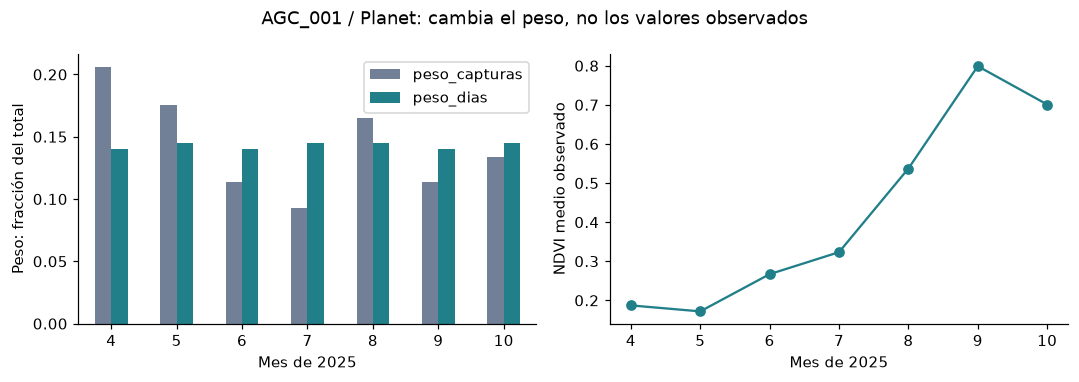

In [7]:
DIAS = pd.Series([30, 31, 30, 31, 31, 30, 31], index=range(4, 11), name="dias_mes")
assert DIAS.sum() == 214
assert mensual_ejemplo.n.gt(0).all() and mensual_ejemplo.media.notna().all()
mensual_ejemplo["peso_capturas"] = mensual_ejemplo.n/mensual_ejemplo.n.sum()
mensual_ejemplo["peso_dias"] = DIAS/DIAS.sum()
mensual_ejemplo["aporte_capturas"] = mensual_ejemplo.media*mensual_ejemplo.peso_capturas
mensual_ejemplo["aporte_dias"] = mensual_ejemplo.media*mensual_ejemplo.peso_dias
media_capturas = mensual_ejemplo.aporte_capturas.sum()
media_temporal = mensual_ejemplo.aporte_dias.sum()
media_uniforme_meses = mensual_ejemplo.media.mean()
display(mensual_ejemplo)
print("Por captura:", media_capturas, "| Por días (T1):", media_temporal,
      "| Meses iguales (otra receta):", media_uniforme_meses)
figura, ejes = plt.subplots(1, 2, figsize=(10, 3.5))
mensual_ejemplo[["peso_capturas", "peso_dias"]].plot.bar(ax=ejes[0], color=["#718096", "#207f89"])
mensual_ejemplo.media.plot(marker="o", ax=ejes[1], color="#207f89")
ejes[0].set_ylabel("Peso: fracción del total")
ejes[1].set_ylabel("NDVI medio observado")
for eje in ejes:
    eje.set_xlabel("Mes de 2025")
    eje.tick_params(axis="x", rotation=0)
figura.suptitle("AGC_001 / Planet: cambia el peso, no los valores observados")
figura.tight_layout()
plt.show()

Planet NDVI pasa de **0.402093 a 0.426709** para esta parcela. Es una definición
diferente, no una mejora predictiva demostrada. La media uniforme de meses es otra
receta y no se ensaya. Los resúmenes de Andrea por captura no estaban mal calculados.

## 4. Generalizar la regla y detener inconsistencias

Esta función visible no recibe etiquetas. Exige fechas, sensor, IDs y valores
finitos presentes; rechaza duplicados. Un mes sin valores detiene: no lo imputa,
borra ni redistribuye su peso. Conserva las observaciones ausentes hasta contarlas.

In [8]:
def agregar_meses(datos, sensor, campo, ids):
    ids = list(ids)
    if not ids or len(set(ids)) != len(ids):
        raise ValueError("Lista de parcelas vacía o duplicada")
    columnas = ["ID_POLIGONO", "sensor", "fecha_captura", campo]
    if not set(columnas) <= set(datos.columns):
        raise ValueError("Faltan columnas de capturas")
    df = datos[columnas].copy()
    if df[columnas[:3]].isna().any().any():
        raise ValueError("ID, sensor o fecha ausente")
    if set(df.ID_POLIGONO) != set(ids) or not df.sensor.eq(sensor).all():
        raise ValueError("Sensor o cobertura de parcelas incompatible")
    if not df.fecha_captura.astype(str).str.fullmatch(r"\d{2}/\d{2}/\d{4}").all():
        raise ValueError("Formato de fecha distinto de dd/mm/aaaa")
    df["fecha"] = pd.to_datetime(df.fecha_captura, format="%d/%m/%Y", errors="raise")
    if not df.fecha.between("2025-04-01", "2025-10-31").all():
        raise ValueError("Captura fuera de la ventana registrada")
    if df.duplicated(["ID_POLIGONO", "sensor", "fecha"]).any():
        raise ValueError("Captura duplicada")
    df[campo] = pd.to_numeric(df[campo], errors="raise")
    validos = df.dropna(subset=[campo]).copy()
    if not np.isfinite(validos[campo].to_numpy(dtype=float)).all():
        raise ValueError("Valor presente no finito")
    validos["mes"] = validos.fecha.dt.month
    mensual = validos.groupby(["ID_POLIGONO", "mes"])[campo].agg(media="mean", n="count")
    medias = mensual.media.unstack().reindex(index=ids, columns=DIAS.index)
    conteos = mensual.n.unstack().reindex(index=ids, columns=DIAS.index)
    if not np.isfinite(medias.to_numpy()).all() or not conteos.gt(0).all().all():
        raise ValueError("Mes ausente o sin valores; no se imputa")
    original = (medias*conteos).sum(axis=1)/conteos.sum(axis=1)
    temporal = (medias*DIAS).sum(axis=1)/DIAS.sum()
    tabla = mensual.reset_index()
    tabla["dias_mes"] = tabla.mes.map(DIAS)
    return temporal, original, tabla

CAMBIOS = {"C_PL_ndvi_media": (planet, "Planet", "ndvi_promedio"),
           "C_S2_ndvi_media": (s2, "Sentinel-2", "ndvi_promedio"),
           "C_S2_ndwi_media": (s2, "Sentinel-2", "ndwi_promedio")}
FIJAS = ["C_PL_ndvi_pico_prom", "C_PL_ndvi_doy_pico_prom", "C_LS_vi6t_media"]
assert list(CAMBIOS) == MAN["cambios"]
np.testing.assert_array_equal(DIAS.to_numpy(), MAN["pesos_dias"])
ids_todos = X.ID_POLIGONO.tolist()
atributos = X.set_index("ID_POLIGONO")[["Municipio", "Estado"]+list(CAMBIOS)+FIJAS].copy()
originales = pd.DataFrame(index=ids_todos)
tablas_mensuales = []
for nombre, (fuente, sensor, campo) in CAMBIOS.items():
    temporal, original, mensual = agregar_meses(fuente, sensor, campo, ids_todos)
    originales[nombre] = original
    atributos[nombre] = temporal
    tablas_mensuales.append(mensual.assign(variable=nombre))
mensuales = pd.concat(tablas_mensuales, ignore_index=True)
assert len(mensuales) == 197*3*7 == 4137
display(atributos.head())
print("197 parcelas × 3 variables × 7 meses: 4,137 medias calculadas sin rendimiento.")

,Municipio,Estado,C_PL_ndvi_media,C_S2_ndvi_media,C_S2_ndwi_media,C_PL_ndvi_pico_prom,C_PL_ndvi_doy_pico_prom,C_LS_vi6t_media
ID_POLIGONO,,,,,,,,
AGC_001,Calpulalpan,Tlaxcala,0.426709,0.314170,0.078541,0.836,245,-0.623929
AGC_002,Chignahuapan,Puebla,0.495058,0.402720,0.081721,0.835,184,-0.621455
AGC_003,Singuilucan,Hidalgo,0.482179,0.389864,0.068852,0.829,238,-0.645286
AGC_004,Calpulalpan,Tlaxcala,0.422085,0.313971,0.010987,0.700,245,-0.625833
AGC_005,Chignahuapan,Puebla,0.526089,0.404861,0.026611,0.871,248,-0.638115


197 parcelas × 3 variables × 7 meses: 4,137 medias calculadas sin rendimiento.


**Comprobación posterior:** ahora consultamos los controles guardados. La media
por captura debe recuperar la receta anterior; la ponderada debe recuperar T1.
Los picos, fecha del pico, VI6T y municipio permanecen fijos. Tolerancia absoluta
10⁻¹²: CSV y lectura flotante pueden diferir en los últimos decimales.

In [9]:
base_x = X.set_index("ID_POLIGONO")
np.testing.assert_allclose(originales.to_numpy(), base_x.loc[ids_todos, list(CAMBIOS)].to_numpy(), atol=1e-12, rtol=0)
guardado = leer_csv("atributos", "control_posterior").set_index("ID_POLIGONO")
assert guardado.index.is_unique and set(guardado.index) == set(ids_todos)
np.testing.assert_allclose(atributos[list(CAMBIOS)+FIJAS].to_numpy(),
                           guardado.loc[ids_todos, list(CAMBIOS)+FIJAS].to_numpy(), atol=1e-12, rtol=0)
np.testing.assert_allclose(atributos[FIJAS].to_numpy(), base_x.loc[ids_todos, FIJAS].to_numpy(), atol=0, rtol=0)
pd.testing.assert_frame_equal(atributos[["Municipio", "Estado"]], guardado.loc[ids_todos, ["Municipio", "Estado"]])
claves_mes = ["ID_POLIGONO", "variable", "mes"]
control_meses = leer_csv("mensuales", "control_posterior")
assert not control_meses.duplicated(claves_mes).any()
actual = mensuales.set_index(claves_mes).sort_index()
esperado_mes = control_meses.set_index(claves_mes).sort_index()
assert actual.index.equals(esperado_mes.index)
np.testing.assert_allclose(actual.media, esperado_mes.media, atol=1e-12, rtol=0)
np.testing.assert_array_equal(actual[["n", "dias_mes"]], esperado_mes[["n", "dias_mes"]])
delta_variables = atributos[list(CAMBIOS)]-originales
display(delta_variables.describe().T[["mean", "std", "min", "max"]])
display(pd.DataFrame({"por_captura": originales.loc["AGC_001"],
                      "por_dias_T1": atributos.loc["AGC_001", list(CAMBIOS)]}))
print("Medias mensuales y finales coinciden con los controles; tres columnas fijas intactas.")

,mean,std,min,max
C_PL_ndvi_media,0.027130,0.014695,-0.012805,0.056889
C_S2_ndvi_media,0.000653,0.011457,-0.033261,0.046622
C_S2_ndwi_media,0.003940,0.010828,-0.037147,0.037822


,por_captura,por_dias_T1
C_PL_ndvi_media,0.402093,0.426709
C_S2_ndvi_media,0.338325,0.31417
C_S2_ndwi_media,0.101100,0.078541


Medias mensuales y finales coinciden con los controles; tres columnas fijas intactas.


## 5. Misma comparación, selección separada de evaluación

Conservamos **FULL138**, cinco pliegues y diez repeticiones exteriores. Cada
parcela aparece diez veces fuera de muestra. Los cuatro pliegues interiores
contienen solo IDs del entrenamiento exterior: sirven para elegir alpha.
Repetir particiones no crea etiquetas; no son el split oficial del reto.

In [10]:
ids = set(etiquetas.ID_POLIGONO)
assert len(externas) == 6900 and len(internas) == 22080
assert not externas.duplicated(["repeticion", "pliegue", "ID_POLIGONO"]).any()
assert not internas.duplicated(["repeticion", "pliegue", "pliegue_interno", "ID_POLIGONO"]).any()
assert set(externas.rol) == set(internas.rol) == {"entrenamiento", "validacion"}
assert set(externas.repeticion) == set(range(10)) and set(externas.pliegue) == set(range(5))
assert set(internas.pliegue_interno) == set(range(4))
assert set(internas.groupby(["repeticion", "pliegue"]).groups) == set(externas.groupby(["repeticion", "pliegue"]).groups)
for (r, f), parte in externas.groupby(["repeticion", "pliegue"]):
    train_ids = set(parte.loc[parte.rol.eq("entrenamiento"), "ID_POLIGONO"])
    val_ids = set(parte.loc[parte.rol.eq("validacion"), "ID_POLIGONO"])
    assert train_ids.isdisjoint(val_ids) and train_ids | val_ids == ids
    dentro = internas.loc[internas.repeticion.eq(r) & internas.pliegue.eq(f)]
    assert set(dentro.ID_POLIGONO) == train_ids
    for _, iparte in dentro.groupby("pliegue_interno"):
        assert set(iparte.ID_POLIGONO) == train_ids
    frecuencia = dentro.loc[dentro.rol.eq("validacion")].groupby("ID_POLIGONO").size()
    assert set(frecuencia.index) == train_ids and frecuencia.eq(1).all()
claves = ["repeticion", "pliegue", "ID_POLIGONO"]
validaciones = externas.loc[externas.rol.eq("validacion"), claves].copy()
frecuencia = validaciones.groupby(["repeticion", "ID_POLIGONO"]).size()
assert len(validaciones) == len(frecuencia) == 1380 and frecuencia.eq(1).all()
ejemplo_roles = externas.loc[externas.repeticion.eq(0) & externas.pliegue.eq(0)]
display(ejemplo_roles.groupby("rol").size().rename("parcelas").to_frame())
display(internas.loc[internas.repeticion.eq(0) & internas.pliegue.eq(0)]
        .groupby(["pliegue_interno", "rol"]).size().rename("parcelas").to_frame())

,parcelas
rol,
entrenamiento,110
validacion,28


parcelas
pliegue_interno rol                    
0               entrenamiento        82
                validacion           28
1               entrenamiento        82
                validacion           28
2               entrenamiento        83
                validacion           27
3               entrenamiento        83
                validacion           27

**Pipeline histórico:** municipio → indicadores completos 0/1 sin escalar;
seis numéricas → mediana → escala → Ridge con intercepto. Categorías, medianas,
medias y escalas se aprenden dentro de cada entrenamiento. E0 penaliza efectos
municipales y no equivale a MUN. En Ridge un municipio desconocido tiene indicadores
cero; no un fallback explícito a la media global.

Elegimos Ridge para controlar la representación, no por demostrar que es el modelo
óptimo. La [definición oficial](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Ridge.html)
explica su penalización L2. T1 conserva las seis numéricas, solo sustituye tres.

**Alpha se reselecciona**, no se fija al de E2: misma rejilla 0.01, 0.1, 1, 10, 100;
mínimo RMSE de errores interiores concatenados; empate ≤10⁻¹² → mayor alpha.
La [validación cruzada](https://scikit-learn.org/stable/modules/cross_validation.html)
separa selección y evaluación, sin convertir la hipótesis posterior a EDA en confirmatoria.

In [11]:
ALPHAS = (0.01, 0.1, 1.0, 10.0, 100.0)

def seleccionar_alpha(fila):
    scores = np.array([fila[f"rmse_interno_alpha_{a:g}"] for a in ALPHAS], dtype=float)
    if not np.isfinite(scores).all() or (scores < 0).any():
        raise ValueError("Scores internos inválidos")
    return float(np.array(ALPHAS)[scores <= scores.min()+1e-12].max())

alpha_t1 = leer_csv("alpha_t1", "scores_guardados")
alpha_e2 = leer_csv("alpha_control_e2", "scores_guardados")
clave_pliegue = ["repeticion", "pliegue"]
exteriores = set(externas.groupby(clave_pliegue).groups)
for tabla, modelo in [(alpha_t1, "T1"), (alpha_e2, "E2")]:
    assert len(tabla) == 50 and set(tabla.modelo) == {modelo}
    assert not tabla.duplicated(clave_pliegue).any()
    assert set(zip(tabla.repeticion, tabla.pliegue)) == exteriores
    np.testing.assert_array_equal(tabla.apply(seleccionar_alpha, axis=1), tabla.alpha)
pares_alpha = alpha_t1.merge(alpha_e2, on=clave_pliegue, validate="one_to_one", suffixes=("_T1", "_E2"))
cambios_alpha = int(pares_alpha.alpha_T1.ne(pares_alpha.alpha_E2).sum())
fila = alpha_t1.loc[alpha_t1.repeticion.eq(0) & alpha_t1.pliegue.eq(0)].iloc[0]
display(pd.DataFrame({"alpha": ALPHAS, "RMSE_interno_guardado": [fila[f"rmse_interno_alpha_{a:g}"] for a in ALPHAS]}))
print("100 decisiones verificadas; cambios de alpha T1 frente a E2:", cambios_alpha)
assert cambios_alpha == 13
print("Ajustes históricos: 1,050 T1 + 1,050 control E2 = 2,100. Ajustes actuales: 0.")

,alpha,RMSE_interno_guardado
0,0.01,0.470148
1,0.10,0.469750
2,1.00,0.473850
3,10.00,0.531179
4,100.00,0.692250


100 decisiones verificadas; cambios de alpha T1 frente a E2: 13
Ajustes históricos: 1,050 T1 + 1,050 control E2 = 2,100. Ajustes actuales: 0.


Los cinco scores por exterior están guardados; sus errores internos individuales,
coeficientes y transformaciones ajustadas no. Verificamos la elección, **no
recalculamos scores**. Los 13 cambios de alpha forman parte del mismo procedimiento.

**Control histórico de entorno:** antes de ensayar T1 se volvió a ejecutar E2
porque cambió Python/scikit-learn respecto de la ronda anterior. Ahora cotejamos
esas OOF y scores almacenados con los originales; no afirmamos repetir sus ajustes.
El control E2 no es otro candidato ni debe duplicarse al contar predicciones.

In [12]:
oof_ronda = leer_csv("oof_ronda1", "resultados_guardados")
control_oof = leer_csv("oof_control_e2", "resultados_guardados")
origen_e2 = oof_ronda.loc[oof_ronda.modelo.eq("E2")]
comparacion_e2 = origen_e2.merge(control_oof, on=["modelo"]+claves,
                                validate="one_to_one", suffixes=("_original", "_control"))
assert len(comparacion_e2) == len(control_oof) == len(origen_e2) == 1380
np.testing.assert_array_equal(comparacion_e2.observado_original, comparacion_e2.observado_control)
np.testing.assert_array_equal(comparacion_e2.alpha_original, comparacion_e2.alpha_control)
np.testing.assert_allclose(comparacion_e2.predicho_original, comparacion_e2.predicho_control, atol=1e-8, rtol=0)
origen_alpha = leer_csv("alpha_ronda1", "scores_guardados")
origen_alpha = origen_alpha.loc[origen_alpha.modelo.eq("E2")]
comparacion_alpha = origen_alpha.merge(alpha_e2, on=["modelo"]+clave_pliegue,
                                      validate="one_to_one", suffixes=("_original", "_control"))
assert len(comparacion_alpha) == 50
np.testing.assert_array_equal(comparacion_alpha.alpha_original, comparacion_alpha.alpha_control)
max_score = 0.0
for a in ALPHAS:
    k = f"rmse_interno_alpha_{a:g}"
    dif = np.abs(comparacion_alpha[k+"_original"]-comparacion_alpha[k+"_control"])
    max_score = max(max_score, float(dif.max()))
    np.testing.assert_allclose(comparacion_alpha[k+"_original"], comparacion_alpha[k+"_control"], atol=1e-8, rtol=0)
print("Control guardado / original: máximo ΔOOF =", float(np.abs(comparacion_e2.predicho_original-comparacion_e2.predicho_control).max()),
      "| máximo Δscore =", max_score)
print("Tolerancia histórica: 10⁻⁸; 50 alphas idénticos. No hubo reentrenamiento actual.")

Control guardado / original: máximo ΔOOF = 8.881784197001252e-16 | máximo Δscore = 1.1102230246251565e-16
Tolerancia histórica: 10⁻⁸; 50 alphas idénticos. No hubo reentrenamiento actual.


## 6. ¿Son comparables las predicciones que puntuamos?

Comparadores: GLOBAL, MUN, MIX, E0, E2 y T1. MIX conserva 50 % MUN + 50 % IDW
(k=20, potencia 2, piso 1 m). Ubicación interviene en MIX, no como coordenadas
en los candidatos Ridge. Cada procedimiento debe tener exactamente las mismas
claves `(repetición, pliegue, parcela)` y el rendimiento original.

In [13]:
oof_t1 = leer_csv("oof_t1", "resultados_guardados")
ref = leer_csv("referencias", "resultados_guardados")
alias = {"Media global": "GLOBAL", "Media municipal": "MUN", "Municipio + IDW fijo": "MIX"}
ref = ref.loc[ref.modelo.isin(alias)].copy()
ref["modelo"] = ref.modelo.map(alias)
assert set(oof_t1.modelo) == {"T1"}
ridge = pd.concat([oof_ronda.loc[oof_ronda.modelo.isin(["E0", "E2"])], oof_t1], ignore_index=True)
seleccion_oof = pd.concat([leer_csv("alpha_ronda1", "scores_guardados").query("modelo in ['E0', 'E2']"), alpha_t1])
ver_alpha = ridge.merge(seleccion_oof[["modelo"]+clave_pliegue+["alpha"]],
                       on=["modelo"]+clave_pliegue, validate="many_to_one", suffixes=("", "_seleccion"))
np.testing.assert_array_equal(ver_alpha.alpha, ver_alpha.alpha_seleccion)
todos = pd.concat([ridge.drop(columns="alpha"), ref], ignore_index=True)
modelos = ["GLOBAL", "MUN", "MIX", "E0", "E2", "T1"]
assert set(todos.modelo) == set(modelos) and len(todos) == 8280
assert not todos.duplicated(["modelo"]+claves).any()
esperado = set(map(tuple, validaciones[claves].to_numpy()))
oficial = etiquetas.set_index("ID_POLIGONO").RENDIMIENTO_T_HA
for _, grupo in todos.groupby("modelo"):
    assert len(grupo) == 1380 and set(map(tuple, grupo[claves].to_numpy())) == esperado
    np.testing.assert_allclose(grupo.observado, grupo.ID_POLIGONO.map(oficial), atol=0, rtol=0)
    assert np.isfinite(grupo[["observado", "predicho"]].to_numpy()).all()
todos = todos.merge(X[["ID_POLIGONO", "Municipio", "Estado"]], on="ID_POLIGONO", validate="many_to_one")
todos["error"] = todos.predicho-todos.observado
todos["error2"] = todos.error**2
todos["zona"] = np.where(todos.Municipio.eq("Chignahuapan"), "Chignahuapan", "Resto")
print("6 procedimientos × 1,380 OOF: claves y etiquetas verificadas. Sin 59 predicciones finales.")

6 procedimientos × 1,380 OOF: claves y etiquetas verificadas. Sin 59 predicciones finales.


## 7. Calcular métricas antes de mirar el control

$RMSE=\sqrt{\overline{e^2}}$, $MAE=\overline{|e|}$,
$R^2=1-\sum e^2/\sum(y-\bar y)^2$. RMSE/MAE: t/ha; R²: sin unidades.
Agrupamos 1,380 errores por procedimiento; no promediamos primero las predicciones
de cada parcela ni los RMSE de pliegues. Denominador R² ≤10⁻¹² → NaN.

,RMSE,MAE,R2
GLOBAL,0.854426,0.753994,-0.015043
MUN,0.511757,0.335394,0.635865
MIX,0.493845,0.341711,0.660908
E0,0.510558,0.336560,0.637568
E2,0.519202,0.359676,0.625193
T1,0.522472,0.359620,0.620457


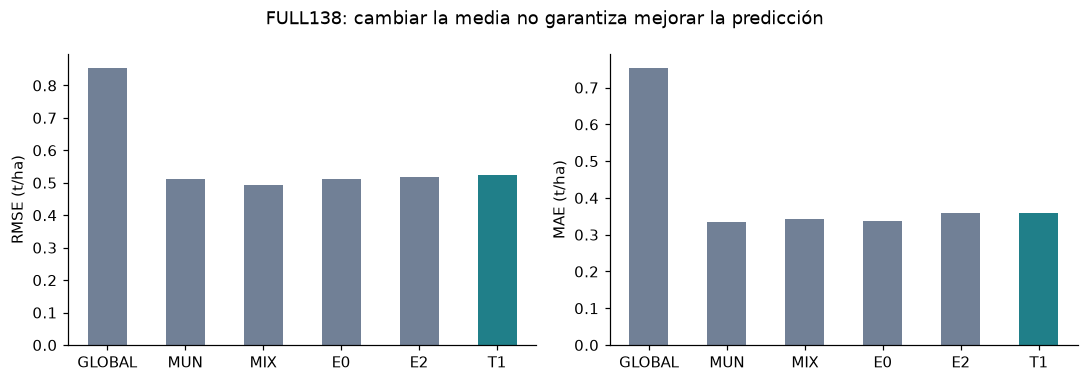

Las métricas agrupadas de los seis procedimientos coinciden con el control histórico a 10⁻¹².


In [14]:
def metricas(df):
    y = df.observado.to_numpy(dtype=float)
    p = df.predicho.to_numpy(dtype=float)
    if len(y) == 0 or not np.isfinite(y).all() or not np.isfinite(p).all():
        raise ValueError("Predicciones vacías o no finitas")
    e = p-y
    denominador = np.sum((y-y.mean())**2)
    return pd.Series({"RMSE": np.sqrt(np.mean(e**2)), "MAE": np.mean(np.abs(e)),
                      "R2": 1-np.sum(e**2)/denominador if denominador > 1e-12 else np.nan})

resultados = pd.DataFrame({k: metricas(g) for k, g in todos.groupby("modelo")}).T.loc[modelos]
display(resultados.round(9))
figura, ejes = plt.subplots(1, 2, figsize=(10, 3.5))
for eje, metrica in zip(ejes, ["RMSE", "MAE"]):
    resultados[metrica].plot.bar(ax=eje, color=["#718096"]*5+["#207f89"])
    eje.set_ylabel(metrica+" (t/ha)")
    eje.set_xlabel("")
    eje.tick_params(axis="x", rotation=0)
figura.suptitle("FULL138: cambiar la media no garantiza mejorar la predicción")
figura.tight_layout()
plt.show()
control_metricas = leer_csv("metricas_control", "control_posterior").set_index("modelo")
assert control_metricas.index.is_unique and set(modelos) <= set(control_metricas.index)
np.testing.assert_allclose(resultados.to_numpy(), control_metricas.loc[modelos, ["RMSE", "MAE", "R2"]].to_numpy(), atol=1e-12, rtol=0)
print("Las métricas agrupadas de los seis procedimientos coinciden con el control histórico a 10⁻¹².")

T1 RMSE **0.522472** frente a E2 **0.519202**: empeora 0.003270 t/ha.
MAE baja solo 0.000056 t/ha. No supera MIX en RMSE ni MUN en MAE.
La comparación es honesta porque cambia la representación, manteniendo el resto
del procedimiento, pero no demuestra significancia ni desempeño oficial.

## 8. ¿Se repite el cambio y es uniforme en el territorio?

Diferencia pareada: T1 menos comparador, negativa favorece T1. Las divisiones
comparten datos: su rango no es un intervalo de confianza. Mostramos también
Chignahuapan y el resto sin elegir otro modelo por región.

In [15]:
rep = pd.DataFrame([{"modelo": k, "repeticion": r, **metricas(g).to_dict()}
                    for (k, r), g in todos.groupby(["modelo", "repeticion"])])
rep_rmse = rep.pivot(index="repeticion", columns="modelo", values="RMSE")
rep_mae = rep.pivot(index="repeticion", columns="modelo", values="MAE")
pareadas = pd.DataFrame({"T1−E2_RMSE": rep_rmse.T1-rep_rmse.E2,
                         "T1−E2_MAE": rep_mae.T1-rep_mae.E2,
                         "T1−MIX_RMSE": rep_rmse.T1-rep_rmse.MIX,
                         "T1−MUN_MAE": rep_mae.T1-rep_mae.MUN})
display(pareadas)
mejoras_rmse = int(pareadas["T1−E2_RMSE"].lt(0).sum())
mejoras_mae = int(pareadas["T1−E2_MAE"].lt(0).sum())
print("Frente a E2: menor RMSE", mejoras_rmse, "/10; menor MAE", mejoras_mae, "/10.")
assert mejoras_rmse == 3 and mejoras_mae == 5
assert pareadas["T1−MIX_RMSE"].gt(0).all() and pareadas["T1−MUN_MAE"].gt(0).all()
zonas = pd.DataFrame([{"modelo": k, "zona": z, "parcelas": g.ID_POLIGONO.nunique(), **metricas(g).to_dict()}
                      for (k, z), g in todos.groupby(["modelo", "zona"])])
display(zonas.loc[zonas.modelo.isin(["E2", "T1", "MIX", "MUN"])])

,T1−E2_RMSE,T1−E2_MAE,T1−MIX_RMSE,T1−MUN_MAE
repeticion,,,,
0,-0.001764,-0.006605,0.040421,0.026350
1,0.006167,0.002440,0.036750,0.028073
2,-0.004970,-0.004962,0.017933,0.016173
3,0.003684,-0.001061,0.016941,0.016343
4,0.009879,0.010301,0.032035,0.025365
5,0.002736,0.000763,0.035125,0.028417
6,0.007485,0.000515,0.029370,0.033690
7,0.001855,-0.004201,0.024736,0.014070
8,0.008809,0.003373,0.032330,0.034329


Frente a E2: menor RMSE 3 /10; menor MAE 5 /10.


,modelo,zona,parcelas,RMSE,MAE,R2
2,E2,Chignahuapan,71,0.603285,0.399641,-0.080918
3,E2,Resto,67,0.411769,0.317325,0.680042
6,MIX,Chignahuapan,71,0.573628,0.389104,0.022745
7,MIX,Resto,67,0.391961,0.291488,0.710085
8,MUN,Chignahuapan,71,0.590198,0.381019,-0.034531
9,MUN,Resto,67,0.412669,0.287046,0.678641
10,T1,Chignahuapan,71,0.599866,0.400251,-0.068701
11,T1,Resto,67,0.425357,0.316563,0.658577


En Chignahuapan (71 etiquetas) RMSE baja ligeramente: 0.6033 → 0.5999;
MIX sigue en 0.5736. En las otras 67 sube: 0.4118 → 0.4254.
No es una mejora global uniforme.

## 9. ¿De qué parcelas depende? Sensibilidad prevista

El diagnóstico anterior identificó AGC_127/171. El manifiesto T1 ya incluyó
omitirlas **solo al calcular métricas**: sensibilidad prevista, exploratoria;
no retirar etiquetas del entrenamiento ni volver a ajustar modelos.
Contar cuántas mejoran no basta: importa cuánto cambia el error cuadrático.

In [16]:
error_parcela = todos.groupby(["ID_POLIGONO", "modelo"]).error2.mean().unstack()
error_parcela["delta_MSE_T1_E2"] = error_parcela.T1-error_parcela.E2
display(error_parcela[["E2", "T1", "delta_MSE_T1_E2"]].sort_values("delta_MSE_T1_E2").head(5))
display(error_parcela[["E2", "T1", "delta_MSE_T1_E2"]].sort_values("delta_MSE_T1_E2", ascending=False).head(5))
print("Menor MSE:", int(error_parcela.delta_MSE_T1_E2.lt(0).sum()),
      "| Mayor MSE:", int(error_parcela.delta_MSE_T1_E2.gt(0).sum()))
print("Suma ΔMSE de 138 parcelas:", error_parcela.delta_MSE_T1_E2.sum(), "(t/ha)²")
print("No es ΔSSE de 1,380 OOF: este vale diez veces esa suma.")
focos = ["AGC_127", "AGC_171"]
sin_focos = todos.loc[~todos.ID_POLIGONO.isin(focos)]
sensibilidad = pd.DataFrame({k: metricas(g) for k, g in sin_focos.groupby("modelo")}).T
display(sensibilidad.loc[["E2", "T1", "MIX", "MUN"]])
control_sensibilidad = leer_csv("sensibilidad_control", "control_posterior").set_index("modelo")
np.testing.assert_allclose(sensibilidad.loc[modelos].to_numpy(), control_sensibilidad.loc[modelos, ["RMSE", "MAE", "R2"]].to_numpy(), atol=1e-12, rtol=0)
assert sin_focos.ID_POLIGONO.nunique() == 136
assert sensibilidad.loc["T1", "RMSE"] > sensibilidad.loc["E2", "RMSE"]

modelo,E2,T1,delta_MSE_T1_E2
ID_POLIGONO,,,
AGC_127,1.336406,0.813688,-0.522718
AGC_049,1.086674,0.872872,-0.213802
AGC_069,0.792042,0.599346,-0.192696
AGC_055,1.222539,1.053921,-0.168617
AGC_164,0.848415,0.683118,-0.165297


modelo,E2,T1,delta_MSE_T1_E2
ID_POLIGONO,,,
AGC_024,2.211997,2.655122,0.443125
AGC_048,1.164186,1.455898,0.291712
AGC_001,0.225145,0.514923,0.289778
AGC_034,1.252999,1.521295,0.268295
AGC_074,0.315692,0.540499,0.224807


Menor MSE: 71 | Mayor MSE: 67
Suma ΔMSE de 138 parcelas: 0.47003919019682006 (t/ha)²
No es ΔSSE de 1,380 OOF: este vale diez veces esa suma.


,RMSE,MAE,R2
E2,0.468523,0.338457,0.680319
T1,0.476959,0.340449,0.668703
MIX,0.452476,0.322915,0.701841
MUN,0.464585,0.314856,0.685670


Mejoran 71 parcelas y empeoran 67; aun así el RMSE global empeora porque los
deterioros pesan más. Sin los dos focos, E2 RMSE 0.4685 frente a T1 0.4770.
Esta población de 136 es un diagnóstico, no la tarea principal ni una nueva
evaluación independiente. No predice qué ocurriría excluyéndolas al entrenar.

## 10. Decisión y límite del resultado negativo

**Decisión conservada: no promover T1 ni reemplazar la referencia.** Equilibrar
los pesos parece razonable, pero esta receta concreta no mejora E2 globalmente
ni supera MIX/MUN. Se conserva la evidencia negativa; no se buscan ventanas o
alphas nuevos para cambiar el desenlace.

No demuestra que toda ingeniería temporal, satélite, clima o Ridge sean inútiles.
No reconstruye la trayectoria diaria verdadera ni identifica fases fenológicas o
causas. Es una temporada, estas variables y estas particiones de desarrollo.

**Siguiente pregunta:** estudiar una representación con una hipótesis diferente,
conservando referencias y separación selección/evaluación. Esa continuidad se
documentará como otra ronda; no alteramos T1 ni anticipamos su resultado.

Exploración: 24 de septiembre; registro local y ejecución: 29; recortes/adaptación:
8 de octubre. No se inventan fechas, sello externo ni ratificación de todo el equipo.

In [17]:
resumen = {
    "id": "EXP_02", "modo": "lector_retrospectivo_sin_ajustes",
    "parcelas": 197, "etiquetas": 138, "medias_mensuales": len(mensuales),
    "variables_modificadas": list(CAMBIOS), "variables_fijas": FIJAS,
    "procedimientos": 6, "oof_por_procedimiento": 1380, "oof_total": len(todos),
    "particiones_externas": 50, "particiones_internas": 200,
    "decisiones_alpha_verificadas": 100, "cambios_alpha_T1_E2": cambios_alpha,
    "ajustes_actuales": 0, "predicciones_finales_generadas": 0, "poblacion": "FULL138",
    "scores_interiores_recalculados": False, "predicciones_recalculadas": False,
    "variables_recalculadas": True, "metricas_recalculadas": True, "T1_adoptado": False,
    "fecha_original": "2026-09-29", "fecha_adaptacion": "2026-10-08",
    "metricas": resultados.to_dict(orient="index"), "fecha_ejecucion_utc": FECHA_EJECUCION_UTC,
}
print("RESUMEN_EXP_02_JSON="+json.dumps(resumen, sort_keys=True))
print("Cierre: receta reconstruida y métricas conciliadas; cero ajustes y cero predicciones finales.")

RESUMEN_EXP_02_JSON={"T1_adoptado": false, "ajustes_actuales": 0, "cambios_alpha_T1_E2": 13, "decisiones_alpha_verificadas": 100, "etiquetas": 138, "fecha_adaptacion": "2026-10-08", "fecha_ejecucion_utc": "2026-10-08T14:04:36.638681+00:00", "fecha_original": "2026-09-29", "id": "EXP_02", "medias_mensuales": 4137, "metricas": {"E0": {"MAE": 0.3365600999503437, "R2": 0.6375682739824726, "RMSE": 0.5105584301201501}, "E2": {"MAE": 0.3596758963638445, "R2": 0.6251928722045933, "RMSE": 0.5192018945322401}, "GLOBAL": {"MAE": 0.7539942301985781, "R2": -0.015042909859176445, "RMSE": 0.854426183817986}, "MIX": {"MAE": 0.34171071524357766, "R2": 0.6609083799141342, "RMSE": 0.4938452449320778}, "MUN": {"MAE": 0.3353941346346938, "R2": 0.6358645937936153, "RMSE": 0.5117570123866723}, "T1": {"MAE": 0.3596198147353569, "R2": 0.6204571056363146, "RMSE": 0.5224717105970907}}, "metricas_recalculadas": true, "modo": "lector_retrospectivo_sin_ajustes", "oof_por_procedimiento": 1380, "oof_total": 8280, "pa

## Referencias y glosario breve

**Media por captura:** cada valor disponible pesa igual. **Ponderación temporal:**
cada media mensual pesa según sus días. **NaN:** dato ausente, no cero.
**OOF:** predicción guardada para una parcela apartada. **Alpha:** fuerza de
penalización seleccionada dentro del entrenamiento. **Sensibilidad:** cambiar
explícitamente una condición de evaluación para entender dependencia, no borrar
casos desfavorables. **Retrospectivo:** organiza y recalcula evidencia ya obtenida.

scikit-learn developers. (s. f.). *Ridge* [Documentación de software].
https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Ridge.html

scikit-learn developers. (s. f.). *Cross-validation: Evaluating estimator performance*.
https://scikit-learn.org/stable/modules/cross_validation.html

**Evidencia del equipo incorporada:** manifiesto `T1_ponderacion_temporal`, registro
y tablas (29 de septiembre de 2026); integración y referencias originales. Sus bytes
se identifican en los contratos del cuaderno. No hace falta abrir archivos de
procedencia para seguir o ejecutar esta lectura.